# Лекция 14. Latent diffusion, управляемая генерация и оценка генеративных моделей

Курс «Современное компьютерное зрение». Блокнот рассчитан на Google Colab: ячейки выполняются сверху вниз. Если в среде нет `diffusers` или `peft`, первая ячейка практикума установит их сама. Веса SD-Turbo (около 2,5 ГБ) и CLIP ViT-B/32 скачиваются с Hugging Face Hub автоматически. Все данные мини-модели рисуются процедурно, поэтому внешние датасеты не нужны.

Без GPU автоматически включается режим `FAST_DEV_RUN`: сети облегчены, обучение сокращено, SD-Turbo работает в bfloat16 при разрешении 384×384. Полный прогон на CPU (2 потока) занимает около 70 минут. В GPU-режиме (Colab) тестовая выборка увеличена до 4000 изображений, чтобы оценочная и эталонная части не пересекались. На GPU числа будут другими, поэтому переносить стоит направления эффектов, а не сами значения.

Лекция продолжает лекции 12 и 13. Там диффузионная модель работала прямо в пикселях, и разбирались способы сократить число шагов. Здесь та же модель переносится в латентное пространство автоэнкодера. В практикуме это делается дважды: сначала Stable Diffusion разбирается по компонентам на настоящих весах SD-Turbo, затем из тех же классов `diffusers` собирается мини-LDM. Мини-LDM обучается за минуты на CPU, и на ней можно провести все эксперименты лекции: адаптацию, управление, оценку, запоминание, маркировку.

## Цели лекции

После лекции слушатель должен уметь:

1. объяснить, зачем диффузию переносят в латентное пространство, и оценить выигрыш по вычислениям через коэффициент сжатия автоэнкодера;
2. назвать четыре компонента Stable Diffusion (VAE, текстовый энкодер, U-Net, планировщик) и для каждого указать, что он принимает, что возвращает и какие у него ограничения;
3. сравнить textual inversion, DreamBooth и LoRA по числу обучаемых параметров, выразительности и рискам: переобучению, language drift и дословному запоминанию;
4. объяснить устройство ControlNet (обучаемая копия энкодера, нулевые свёртки), IP-Adapter (раздельное cross-attention) и inpainting-моделей, а также проверить, соблюдает ли генерация заданное условие;
5. посчитать FID, KID, precision/recall, density/coverage, Vendi score и CLIP score и понимать, что каждая метрика видит, чего не видит и как зависит от размера выборки;
6. спланировать слепую попарную ручную оценку: рандомизация, размер выборки, согласованность оценщиков, модель Брэдли — Терри;
7. ориентироваться в лицензиях открытых моделей, судебной практике по авторскому праву, регулировании дипфейков и требованиях к маркировке синтетического контента; понимать, чем водяной знак отличается от подписанных метаданных.

## Обозначения

| Символ | Смысл |
|---|---|
| $x \in \mathbb R^{3 \times H \times W}$ | изображение |
| $\mathcal E, \mathcal D$ | энкодер и декодер VAE |
| $z = s \cdot \mathcal E(x) \in \mathbb R^{c \times h \times w}$ | латент; $f = H/h$ — коэффициент понижения разрешения, $s$ — `scaling_factor` |
| $z_t = \sqrt{\bar\alpha_t}\, z_0 + \sqrt{1 - \bar\alpha_t}\,\epsilon$ | зашумлённый латент на шаге $t$, $\epsilon \sim \mathcal N(0, I)$ |
| $y$, $\tau_\theta(y) \in \mathbb R^{L \times d}$ | подпись (промпт) и её эмбеддинги из текстового энкодера; $L$ — число токенов |
| $\epsilon_\theta(z_t, t, c)$ | U-Net, предсказывающая шум при условии $c$ |
| $w$ | масштаб classifier-free guidance |
| $\varnothing$ | пустое условие (пустой промпт) |
| $W_0, \Delta W = BA$ | исходный вес и низкоранговая добавка LoRA, ранг $r$ |
| $c_{\text{ctrl}}$ | управляющая карта ControlNet (контуры, глубина, поза, сегментация) |
| $\mu, \Sigma$ | среднее и ковариация признаков в FID |
| $\phi(\cdot)$ | экстрактор признаков для метрик (Inception, CLIP, DINOv2 или свой оценщик) |
| FD, KID | Fréchet distance и kernel inception distance в признаках $\phi$ |
| 2AFC | two-alternative forced choice: оценщик выбирает лучшее из двух изображений |

# Часть I. Теория

## 1. Latent diffusion

### 1.1. Где тратятся вычисления пиксельной диффузии

Диффузионная модель из лекции 12 на каждом шаге обрабатывает изображение целиком. При разрешении 512×512 это 786 432 числа, и сеть вызывается десятки раз. Основная часть этих чисел описывает мелкие, почти незаметные детали: текстуру шума, точное положение краёв. Rombach et al. называют это перцептивной избыточностью и предлагают разделить задачу на две ([Rombach et al., 2022](https://arxiv.org/abs/2112.10752)):

1. Перцептивное сжатие. Автоэнкодер один раз учится переводить изображение в компактный латент и обратно так, чтобы восстановленная картинка выглядела почти так же. Обучение идёт с перцептивной и состязательной функциями потерь, поэтому декодер восстанавливает правдоподобные текстуры, а не размытое среднее.
2. Семантическое моделирование. Диффузионная модель учится генерировать уже латенты. Ей не нужно тратить ёмкость на детали, которые восстановит декодер.

Авторы отмечают, что обучение сильной пиксельной диффузионной модели требует сотен GPU-дней ([Rombach et al., 2022](https://arxiv.org/abs/2112.10752)). Разделение на два этапа резко снижает стоимость и обучения, и генерации: автоэнкодер обучается один раз и потом переиспользуется для многих диффузионных моделей.

### 1.2. Сколько выигрываем

Пусть VAE понижает разрешение в $f$ раз и выдаёт $c$ каналов. Тогда изображение $3 \times H \times W$ превращается в латент $c \times \frac{H}{f} \times \frac{W}{f}$, и число чисел уменьшается в

$
\frac{3 H W}{c\, H W / f^2} = \frac{3 f^2}{c}
$

раз. У Stable Diffusion $f = 8$, $c = 4$: сжатие в 48 раз, латент $4 \times 64 \times 64$ для картинки 512×512. Свёртки U-Net дешевеют пропорционально площади, то есть в $f^2 = 64$ раза. Self-attention стоит квадратично от числа позиций, поэтому выигрыш на нём ещё больше: $f^4 = 4096$ раз. Именно поэтому attention в пиксельной U-Net ставят только на самых грубых уровнях, а в латентной его можно ставить уже на уровне $64 \times 64$.

Выбор $f$ — компромисс. Rombach et al. сравнили $f \in \{1, 2, 4, 8, 16, 32\}$: при $f = 1{-}2$ обучение медленное, при $f = 32$ теряется слишком много деталей, а лучшее соотношение качества и затрат дают $f = 4{-}16$ ([Rombach et al., 2022](https://arxiv.org/abs/2112.10752)).

### 1.3. Регуляризация латента и scaling_factor

Латент автоэнкодера без ограничений может иметь произвольный масштаб и сложную структуру. Диффузии же нужно, чтобы латенты данных были примерно стандартизованы: шум $\mathcal N(0, I)$ на последнем шаге должен «заглушать» сигнал. Поэтому латент регуляризуют одним из двух способов ([Rombach et al., 2022](https://arxiv.org/abs/2112.10752)):

- KL-регуляризация: энкодер выдаёт среднее и дисперсию, и к потере добавляется слабый штраф KL к $\mathcal N(0, I)$. Это AutoencoderKL, который используется в Stable Diffusion.
- VQ-регуляризация: латент квантуется по кодовой книге, как в VQGAN из лекции 11.

Штраф KL берётся очень слабым, чтобы не испортить реконструкцию, поэтому дисперсия латента всё равно далека от единицы. Её выравнивают одним числом: перед диффузией латент умножают на `scaling_factor` $s \approx 1/\operatorname{std}(z)$, а перед декодированием делят на него. У SD 1.x и 2.x $s = 0{,}18215$. В разделе 8.2 это проверяется на настоящем VAE, в разделе 9.2 то же число вычисляется для мини-VAE.

### 1.4. Условие через cross-attention

Латентная U-Net получает условие через cross-attention. Подпись кодируется в последовательность эмбеддингов $\tau_\theta(y) \in \mathbb R^{L \times d}$. В каждом трансформерном блоке U-Net признаки латента служат запросами, а эмбеддинги текста — ключами и значениями:

$
\operatorname{Attn}(Q, K, V) = \operatorname{softmax}\!\left(\frac{Q K^\top}{\sqrt{d_k}}\right) V,\qquad
Q = W_Q\, \varphi(z_t),\ K = W_K\, \tau_\theta(y),\ V = W_V\, \tau_\theta(y).
$

Каждая позиция латента сама выбирает, на какие слова смотреть. Это и позволяет модели помещать «красный круг слева» в левую часть картинки. Функция потерь — та же, что в лекции 12, только в латентах:

$
\mathcal L_{\text{LDM}} = \mathbb E_{z_0 = s\,\mathcal E(x),\ y,\ \epsilon,\ t}\ \bigl\|\epsilon - \epsilon_\theta(z_t, t, \tau_\theta(y))\bigr\|^2 .
$

Тот же механизм принимает и другие последовательности: эмбеддинги изображения (IP-Adapter, раздел 4.3), слои семантической карты, токены другой модальности. Это и делает LDM удобной основой для управляемой генерации.

### 1.5. Classifier-free guidance

При обучении подпись с некоторой вероятностью заменяют пустой (у SD v1 — в 10 % случаев, по [карточке модели](https://huggingface.co/CompVis/stable-diffusion-v1-4)). Так одна сеть учится и условному, и безусловному предсказанию. При генерации их смешивают ([Ho & Salimans, 2022](https://arxiv.org/abs/2207.12598)):

$
\hat\epsilon = \epsilon_\theta(z_t, t, \varnothing) + w\,\bigl(\epsilon_\theta(z_t, t, c) - \epsilon_\theta(z_t, t, \varnothing)\bigr).
$

При $w = 1$ это обычная условная модель, при $w > 1$ генерация сдвигается в сторону условия. Ho и Salimans показали, что $w$ управляет компромиссом между качеством отдельных образцов и разнообразием, примерно как температура. В разделе 11.3 этот компромисс измеряется численно: при росте $w$ точность соблюдения подписи растёт, recall и разнообразие падают, а FID сначала улучшается, потом ухудшается.

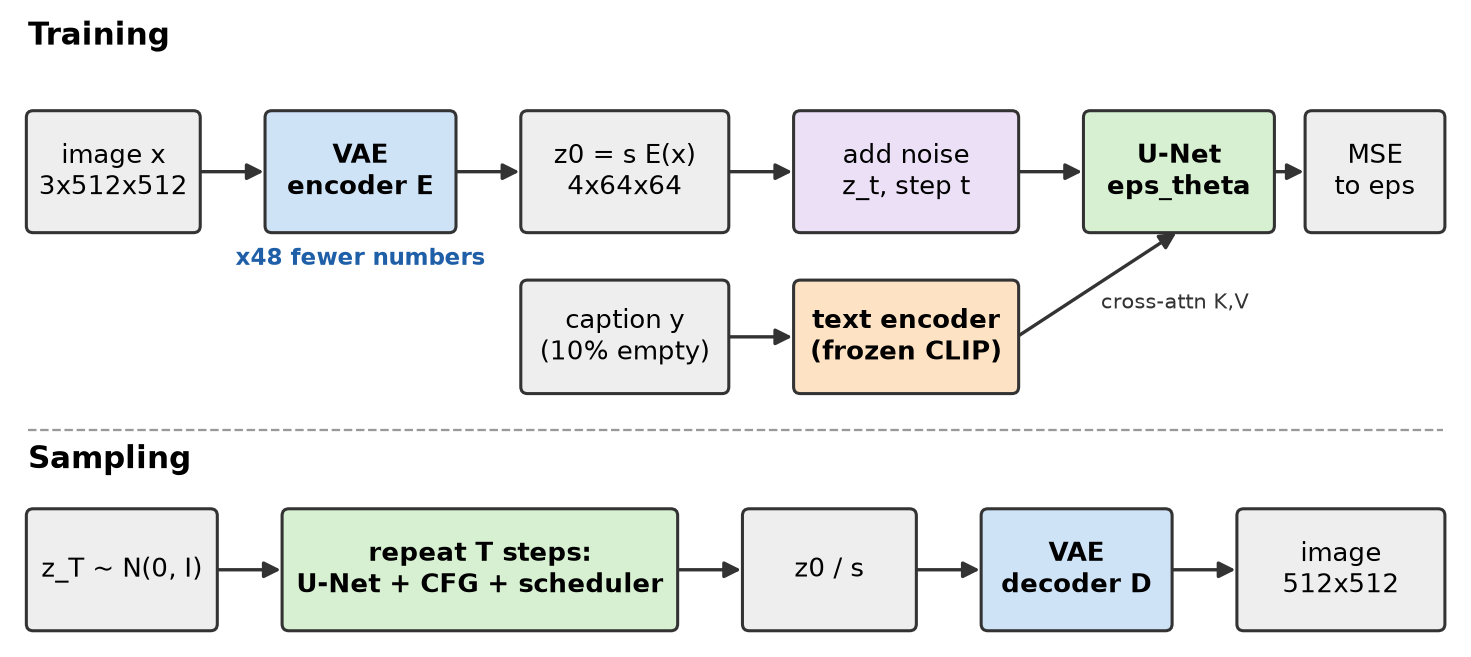

## 2. Stable Diffusion по компонентам

### 2.1. Четыре компонента

Пайплайн Stable Diffusion в `diffusers` — это контейнер из четырёх независимо заменяемых частей (у SD v1 есть ещё safety checker).

1. VAE (`AutoencoderKL`). Кодирует изображение в латент $4 \times \frac{H}{8} \times \frac{W}{8}$ и декодирует обратно. При генерации из текста нужен только декодер; энкодер работает в img2img, inpainting и при обучении. Реконструкция с потерями: мелкий текст, лица и тонкие узоры искажаются уже на этапе VAE, и никакая диффузия этого не исправит. В карточке SD-Turbo это прямо названо ограничением: «автоэнкодирующая часть модели работает с потерями» ([SD-Turbo model card](https://huggingface.co/stabilityai/sd-turbo)).
2. Текстовый энкодер. Замороженный трансформер из CLIP ([Radford et al., 2021](https://arxiv.org/abs/2103.00020)). SD v1 использует CLIP ViT-L/14 ([карточка SD v1-4](https://huggingface.co/CompVis/stable-diffusion-v1-4)), SD 2.x — OpenCLIP ViT-H ([карточка SD 2.1](https://huggingface.co/stabilityai/stable-diffusion-2-1)). Длина последовательности фиксирована: 77 токенов, включая служебные. Всё, что длиннее, обрезается без предупреждения в выводе пайплайна (раздел 8.3).
3. U-Net (`UNet2DConditionModel`). Предсказывает шум (или $v$) по зашумлённому латенту, номеру шага и эмбеддингам текста. Содержит основную часть параметров и вычислений.
4. Планировщик (scheduler). Не содержит обучаемых параметров. Задаёт сетку шагов и формулу перехода $z_t \to z_{t-1}$. DDIM, Euler и DPM-Solver++ из лекции 13 подставляются в один и тот же пайплайн без переобучения, если совпадает тип предсказания и расписание шума.

Такое разбиение важно на практике: LoRA меняет только U-Net (иногда и текстовый энкодер), textual inversion — только таблицу эмбеддингов токенизатора, ControlNet добавляется рядом с U-Net, а быстрый декодер TAESD заменяет VAE для предпросмотра ([TAESD](https://huggingface.co/madebyollin/taesd)).

### 2.2. Семейство моделей

| Модель | Денойзер | Текстовые энкодеры | Особенности |
|---|---|---|---|
| SD 1.x | U-Net | CLIP ViT-L/14 | 512 px, LAION-2B(en) и подвыборки ([карточка](https://huggingface.co/CompVis/stable-diffusion-v1-4)) |
| SD 2.x | U-Net | OpenCLIP ViT-H | 768 px, $v$-предсказание ([карточка](https://huggingface.co/stabilityai/stable-diffusion-2-1)) |
| SDXL | U-Net в 3 раза больше | OpenCLIP ViT-bigG + CLIP ViT-L | 1024 px, условия на размер и кадрирование, отдельный refiner ([Podell et al., 2023](https://arxiv.org/abs/2307.01952); [карточка](https://huggingface.co/stabilityai/stable-diffusion-xl-base-1.0)) |
| SD3 | MMDiT (трансформер) | два CLIP + T5 | rectified flow, раздельные веса для текстовых и визуальных токенов ([Esser et al., 2024](https://arxiv.org/abs/2403.03206)) |
| SD-Turbo, SDXL-Turbo | как у учителя | как у учителя | ADD-дистилляция, 1–4 шага ([Sauer et al., 2023](https://arxiv.org/abs/2311.17042)) |

SD-Turbo — дистиллированная версия SD 2.1, генерирующая за один шаг при разрешении 512×512 ([SD-Turbo model card](https://huggingface.co/stabilityai/sd-turbo)). Метод ADD сочетает дистилляцию по score от модели-учителя и состязательную потерю. По словам авторов, за один шаг он превосходит другие быстрые методы, а за четыре шага выходит на уровень SDXL ([Sauer et al., 2023](https://arxiv.org/abs/2311.17042)). Guidance у таких моделей «вшит» в веса ученика, поэтому при генерации ставят `guidance_scale=0`. В практикуме SD-Turbo выбрана потому, что один шаг U-Net позволяет показать весь пайплайн на CPU.

В разделе 8.1 параметры считаются напрямую: у SD-Turbo (архитектура SD 2.1) U-Net содержит около 866 млн параметров, текстовый энкодер — 340 млн, VAE — 84 млн. Из таблицы видно направление развития: текстовые энкодеры становятся сильнее (в SD3 добавление T5 особенно помогает с надписями и длинными описаниями, [Esser et al., 2024](https://arxiv.org/abs/2403.03206)), U-Net уступает место трансформеру, а diffusion в постановке DDPM — flow matching (лекция 13). Неизменным остаётся главное: генерация идёт в латенте VAE.

### 2.3. Расписание шума и ловушка конечного шага

Stable Diffusion обучена с расписанием `scaled_linear` на 1000 шагах. На последнем шаге $\bar\alpha_T$ не равна нулю, то есть в латенте остаётся немного сигнала исходного изображения. При генерации же стартуют с чистого шума. Lin et al. показали, что это расхождение не даёт модели генерировать очень светлые и очень тёмные изображения, и предложили четыре исправления: обнулить SNR на последнем шаге, обучать с $v$-предсказанием, начинать сэмплинг с последнего шага и масштабировать CFG ([Lin et al., 2024](https://arxiv.org/abs/2305.08891)). Параметр `timestep_spacing="trailing"` у SD-Turbo — третье из этих исправлений: сетка шагов начинается ровно с $t = 999$ (раздел 8.4).

## 3. Адаптация: textual inversion, DreamBooth, LoRA

### 3.1. Задача персонализации

Пользователь приносит 3–5 фотографий своего объекта (собаки, кружки, стиля художника) и хочет генерировать его в новых контекстах: «S на пляже», «S в стиле акварели». Предобученная модель этого объекта не знает, а подобрать описание словами обычно не удаётся: слова задают класс («собака»), но не конкретный экземпляр. Есть три основных способа научить модель новому концепту, и они различаются тем, какую часть модели разрешено менять.

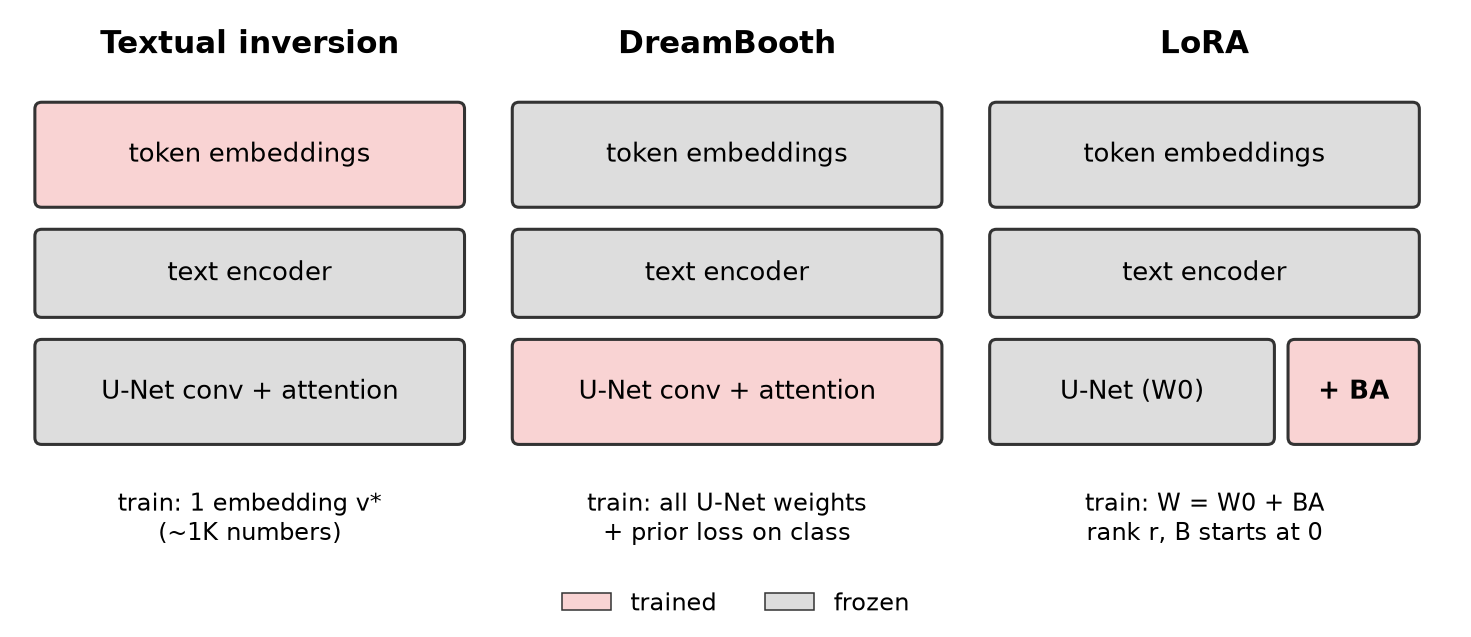

### 3.2. Textual inversion

Gal et al. предложили не трогать веса модели вовсе. В словарь токенизатора добавляется новый токен $S_*$, и обучается только его эмбеддинг $v_* \in \mathbb R^{d}$ — одна строка таблицы эмбеддингов ([Gal et al., 2022](https://arxiv.org/abs/2208.01618)):

$
v_* = \arg\min_v\ \mathbb E_{z_0, \epsilon, t}\ \bigl\|\epsilon - \epsilon_\theta\bigl(z_t, t, \tau_\theta(y(S_*))\bigr)\bigr\|^2,
$

где $y(S_*)$ — шаблонная подпись вида «a photo of $S_*$». Авторы обучали эмбеддинг по 3–5 изображениям и показали, что одного слова хватает, чтобы передать многие уникальные концепты ([Gal et al., 2022](https://arxiv.org/abs/2208.01618)).

Сильные стороны: файл адаптации весит несколько килобайт, модель не портится, несколько токенов можно комбинировать. Слабая сторона: выразительность ограничена тем, что уже умеет генератор. Textual inversion ищет точку во входном пространстве замороженной модели. Если ни одна точка этого пространства не порождает нужную форму, никакой эмбеддинг её не найдёт. В разделе 13.2 это проверяется прямо: мини-модель, не видевшая крестов, не учится рисовать крест через textual inversion, а выразимый концепт («крупный зелёный треугольник» под одним токеном) осваивает легко.

### 3.3. DreamBooth

Ruiz et al. дообучают всю U-Net на нескольких фотографиях объекта с подписью «a [V] dog», где [V] — редкий токен-идентификатор, а «dog» — класс ([Ruiz et al., 2023](https://arxiv.org/abs/2208.12242)). Выразительность здесь полная: меняются все веса, и модель может выучить форму, которой раньше не умела.

Расплата — два вида переобучения:

- Language drift. Модель начинает связывать с классом «dog» именно эту собаку, и запрос «a dog» выдаёт её же. Модель забывает разнообразие класса.
- Копирование. При долгом обучении на 3–5 изображениях модель начинает воспроизводить их почти дословно, вместе с фоном и позой, и перестаёт следовать новому контексту в подписи.

Против первого авторы предлагают class-specific prior preservation loss. Перед дообучением исходная модель генерирует несколько сотен изображений класса («a dog»), и во время дообучения к потере добавляется слагаемое, которое заставляет модель по-прежнему порождать их:

$
\mathcal L = \mathbb E\,\|\epsilon - \epsilon_\theta(z_t, t, c_{[V]})\|^2 + \lambda\, \mathbb E\,\|\epsilon' - \epsilon_\theta(z'_{t'}, t', c_{\text{class}})\|^2 .
$

В разделе 13.3 обе версии DreamBooth обучаются на пяти изображениях креста. Измеряются три величины: умеет ли модель рисовать концепт в новом контексте, как часто она копирует обучающие изображения и насколько ухудшается генерация обычных подписей.

### 3.4. LoRA

LoRA замораживает исходные веса и добавляет к выбранным матрицам низкоранговую поправку ([Hu et al., 2021](https://arxiv.org/abs/2106.09685)):

$
W = W_0 + \frac{\alpha}{r}\, B A,\qquad B \in \mathbb R^{d_{\text{out}} \times r},\ A \in \mathbb R^{r \times d_{\text{in}}},\ r \ll \min(d_{\text{in}}, d_{\text{out}}).
$

Матрица $B$ инициализируется нулями, поэтому в начале обучения модель совпадает с исходной. Для GPT-3 175B авторы сообщают уменьшение числа обучаемых параметров в 10 000 раз и требований к памяти GPU в 3 раза по сравнению с полным дообучением ([Hu et al., 2021](https://arxiv.org/abs/2106.09685)). В диффузионных моделях LoRA обычно ставят на проекции $W_Q, W_K, W_V, W_O$ слоёв внимания U-Net. Её часто сочетают с DreamBooth: функция потерь та же, но обучаются только $A$ и $B$.

У LoRA есть удобная ручка: множитель $\alpha/r$ можно менять после обучения (в `diffusers` — через `set_adapters` с весом). При весе 0 получаем исходную модель, при весе 1 — адаптированную, при промежуточных значениях — плавный переход. В разделе 13.4 по этой шкале видно, как концепт «проявляется» и как при весе больше 1 растут порча обычных подписей и утечка концепта в них.

### 3.5. Сравнение

| | Textual inversion | DreamBooth | LoRA (+ DreamBooth) |
|---|---|---|---|
| Что обучается | один эмбеддинг $v_*$ | все веса U-Net | $A, B$ в слоях внимания |
| Размер адаптации | килобайты | вся U-Net | мегабайты |
| Новая форма, которой модель не умела | нет | да | частично, зависит от ранга |
| Риск language drift | нет | высокий без prior loss | средний |
| Риск копирования | низкий | высокий | средний |
| Комбинирование нескольких концептов | легко | трудно | возможно, с интерференцией |

### 3.6. Memorization: когда модель хранит копии

Персонализация — частный случай общей проблемы. Carlini et al. генерировали изображения Stable Diffusion по подписям из обучающих данных и извлекли из современных моделей более тысячи обучающих изображений, воспроизведённых почти дословно ([Carlini et al., 2023](https://arxiv.org/abs/2301.13188)). Ключевой фактор — дублирование: изображения, которые встречались в обучающих данных много раз, запоминаются гораздо чаще уникальных. Somepalli et al. независимо нашли в генерациях Stable Diffusion копии объектов и целых композиций из LAION, используя детектор копий на признаках ([Somepalli et al., 2023](https://arxiv.org/abs/2212.03860)).

Отсюда практические меры:

- дедупликация обучающих данных, включая почти-дубликаты по эмбеддингам;
- проверка генераций на близость к обучающим данным (поиск ближайшего соседа);
- осторожность с подписями, которые однозначно указывают на конкретное изображение;
- в персонализации — ранняя остановка и prior preservation.

В разделе 12 зависимость «число повторов → доля копий» воспроизводится на мини-модели с «канарейками», повторёнными 1, 10, 50 и 200 раз.

Запоминание связано и с правом. Если модель воспроизводит охраняемое изображение, вопрос о нарушении авторского права становится гораздо конкретнее, чем при обучении на нём (раздел 6.1).

## 4. Управление генерацией

### 4.1. Зачем управлять не только текстом

Текст плохо задаёт геометрию. Фраза «человек поднял левую руку» допускает тысячи поз, и модель выберет любую. Дизайнеру же нужна конкретная поза, конкретный контур здания, конкретная глубина сцены. Поэтому к текстовому условию добавляют пространственные карты: контуры (Canny), глубину (MiDaS), позу (OpenPose), сегментацию, наброски.

### 4.2. ControlNet

Zhang et al. предложили добавлять управление, не трогая предобученную модель ([Zhang et al., 2023](https://arxiv.org/abs/2302.05543)):

1. Энкодер U-Net (нисходящие блоки и средний блок) копируется. Исходная U-Net замораживается, копия обучается.
2. Управляющая карта $c_{\text{ctrl}}$ проходит через небольшую свёрточную сеть до разрешения латента и прибавляется ко входу копии.
3. Выход каждого блока копии проходит через свёртку 1×1 с нулевой инициализацией («zero convolution») и прибавляется к соответствующей skip-связи исходной U-Net.

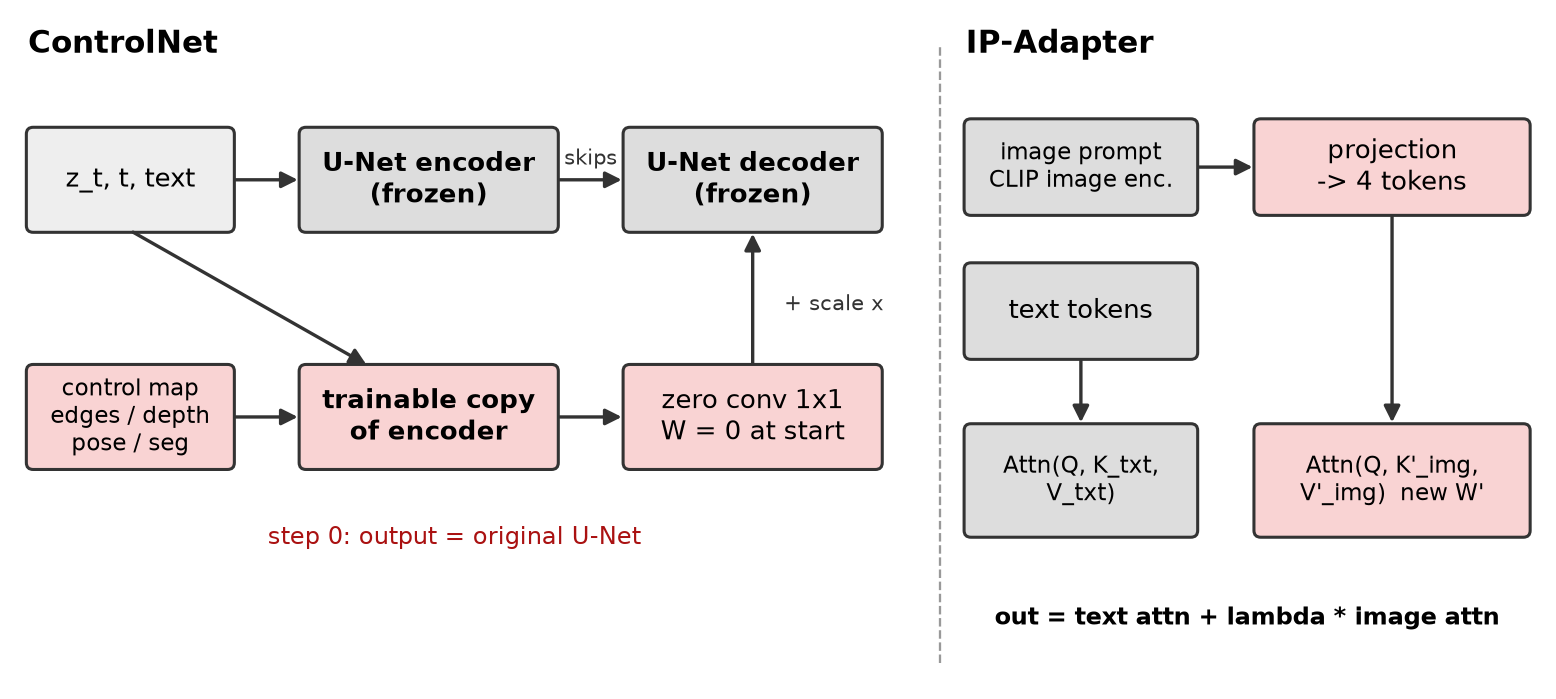

Нулевые свёртки — главная идея. В начале обучения их выход равен нулю, поэтому модель с ControlNet в точности совпадает с исходной: обучение не начинается с разрушения предобученных признаков. Градиент по весам нулевой свёртки при этом не нулевой (он пропорционален входу), так что веса быстро отходят от нуля. Энкодер-копия с первого шага использует признаки, выученные на миллиардах изображений. Авторы сообщают, что обучение устойчиво и на малых (менее 50 тысяч пар), и на больших (более миллиона) наборах ([Zhang et al., 2023](https://arxiv.org/abs/2302.05543)). В разделе 14.1 нулевая инициализация проверяется на мини-модели: до обучения выход U-Net с ControlNet совпадает с выходом без него.

При генерации у ControlNet есть свой масштаб `controlnet_conditioning_scale`: остатки умножаются на него перед сложением. Масштаб 0 выключает управление, большие значения усиливают его, но могут портить качество. В разделе 14.2 сделан такой перебор масштаба.

T2I-Adapter решает ту же задачу легче: небольшая отдельная сеть извлекает из карты признаки нескольких масштабов и прибавляет их к признакам энкодера U-Net, без копии энкодера ([Mou et al., 2023](https://arxiv.org/abs/2302.08453)). Он дешевле при обучении и генерации, но обычно слабее держит геометрию.

### 4.3. IP-Adapter

Иногда условие проще показать, чем описать: «в стиле этой картинки», «этот же персонаж». IP-Adapter добавляет к модели изображение-подсказку ([Ye et al., 2023](https://arxiv.org/abs/2308.06721)). Изображение кодируется замороженным энкодером изображений CLIP, небольшая проекционная сеть превращает эмбеддинг в несколько токенов, и для них в каждом слое cross-attention добавляются свои матрицы $W'_K, W'_V$:

$
\operatorname{out} = \operatorname{Attn}(Q, K_{\text{txt}}, V_{\text{txt}}) + \lambda \cdot \operatorname{Attn}(Q, K_{\text{img}}, V_{\text{img}}).
$

Это «раздельное» (decoupled) cross-attention: текст и изображение не конкурируют внутри одного softmax, и вес $\lambda$ регулирует их баланс уже после обучения. Обучаются только проекция и новые $W'_K, W'_V$. У авторов это 22 млн параметров, и качество сравнимо с полностью дообученной моделью для image prompt или лучше неё ([Ye et al., 2023](https://arxiv.org/abs/2308.06721)). В разделе 15 такой адаптер обучается на мини-модели, и $\lambda$ перебирается в ситуации конфликта: подпись просит одно, образ показывает другое.

### 4.4. Inpainting и img2img

Img2img (SDEdit) начинает генерацию не с чистого шума, а с исходного изображения, зашумлённого до промежуточного шага $t_0$ ([Meng et al., 2022](https://arxiv.org/abs/2108.01073)). Параметр `strength` = $t_0 / T$ задаёт компромисс: малые значения сохраняют исходник, большие отдают управление подписи.

Inpainting — дорисовка области под маской $m$. Есть два подхода:

- Смешивание без переобучения. На каждом шаге латент вне маски заменяется зашумлённым до текущего уровня латентом оригинала: $z_{t-1} \leftarrow m \odot z_{t-1} + (1 - m) \odot z^{\text{orig}}_{t-1}$. RePaint дополняет это повторным зашумлением, чтобы дорисованное лучше согласовалось с контекстом ([Lugmayr et al., 2022](https://arxiv.org/abs/2201.09865)). Модель не знает о маске, поэтому на границе часто остаются швы, а содержимое маски плохо учитывает окружение.
- Специальная inpainting-модель. На вход U-Net подаются 9 каналов: зашумлённый латент (4), маска, уменьшенная до разрешения латента (1), и латент изображения с вырезанной областью (4). Модель дообучается на случайных масках и видит контекст напрямую. Так устроены, например, `stable-diffusion-inpainting` и `stable-diffusion-2-inpainting`.

В разделе 8.6 смешивание показано на SD-Turbo, в разделе 16 оба подхода сравниваются на мини-модели по трём числам: правильно ли дорисован объект, сохранён ли контекст и насколько заметен шов.

### 4.5. Проверка соблюдения условия

Управляемая модель должна не только выдавать красивые картинки, но и выполнять условие. Проверять это нужно отдельной моделью, которая не участвовала в обучении генератора:

| Условие | Как проверить | Метрика |
|---|---|---|
| Контуры | извлечь контуры из генерации тем же детектором | F1 по пикселям контура (с допуском) |
| Глубина | оценить глубину (MiDaS, Depth Anything) | MAE или корреляция с заданной картой |
| Поза | оценить ключевые точки (OpenPose) | PCK, OKS или IoU конечностей |
| Сегментация | сегментировать генерацию | mIoU с заданной картой |
| Атрибуты из текста | детектор или VQA-модель | доля выполненных требований |

Для текстовых условий используют бенчмарки вроде GenEval, который проверяет объекты, их число, цвета и взаимное расположение с помощью детектора ([Ghosh et al., 2023](https://arxiv.org/abs/2310.11513)), и TIFA, который генерирует по подписи вопросы и отвечает на них VQA-моделью: 4 тысячи подписей, 25 тысяч вопросов, 12 категорий ([Hu et al., 2023](https://arxiv.org/abs/2303.11897)). В практикуме роль такого проверяющего играют оценщик атрибутов и аннотатор карт, обученные на настоящих изображениях ShapeWorld (раздел 7.4).

## 5. Оценка генеративных моделей

### 5.1. Что вообще измеряем

У генеративной модели нет одной «правильной» выдачи, поэтому оценка разбивается на несколько независимых вопросов:

1. Качество (fidelity): похожи ли отдельные изображения на настоящие?
2. Разнообразие и покрытие (diversity, coverage): воспроизводит ли модель всё распределение данных или только часть мод?
3. Соответствие условию (alignment): выполняет ли изображение подпись, позу, карту глубины?
4. Предпочтения людей: какое изображение люди выбирают, когда сравнивают?
5. Новизна: не копирует ли модель обучающие данные (раздел 3.6)?

Ни одна метрика не отвечает на все вопросы сразу. Модель, которая выдаёт копии обучающих изображений, получит идеальный FID и нулевую новизну.

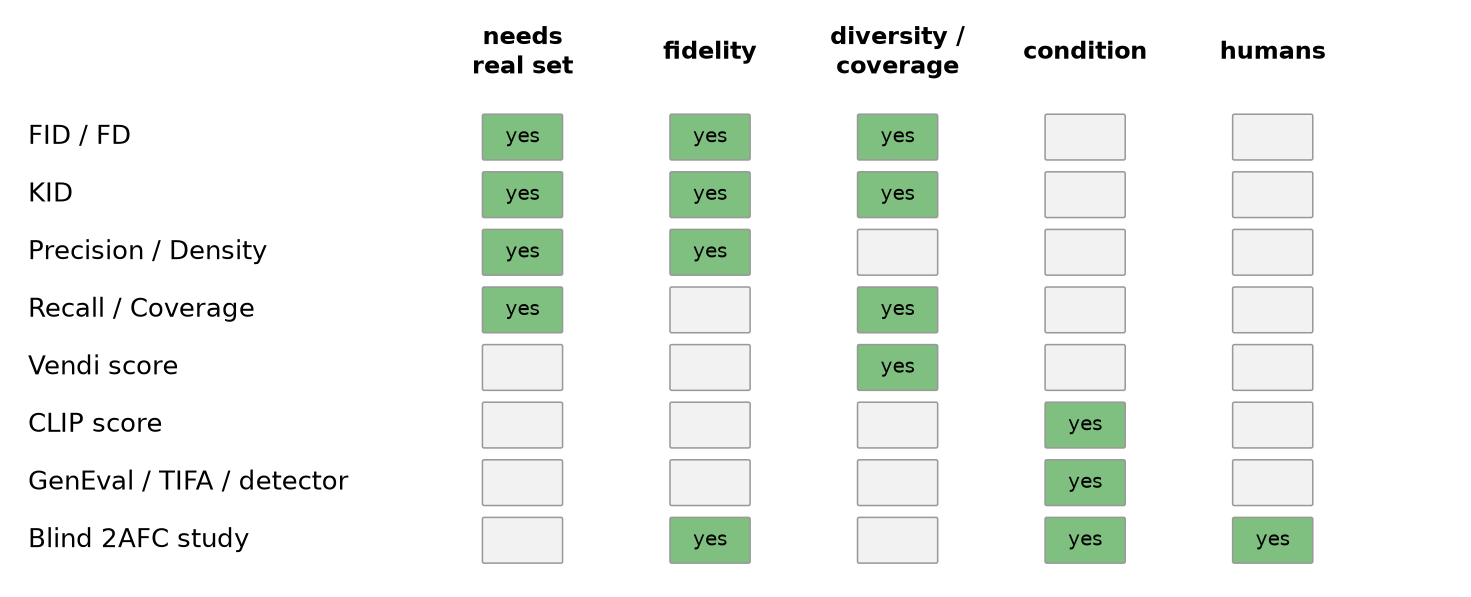

### 5.2. FID

Fréchet Inception Distance сравнивает распределения признаков настоящих и сгенерированных изображений, приближая каждое гауссовым ([Heusel et al., 2017](https://arxiv.org/abs/1706.08500)):

$
\operatorname{FID} = \|\mu_r - \mu_g\|^2 + \operatorname{tr}\Bigl(\Sigma_r + \Sigma_g - 2\,(\Sigma_r \Sigma_g)^{1/2}\Bigr),
$

где $\mu, \Sigma$ — среднее и ковариация признаков Inception-v3 (2048-мерный слой перед классификатором). В общем случае говорят о Fréchet distance (FD) в признаках произвольного экстрактора $\phi$.

Свойства и подводные камни:

- Смещение. Оценка по конечной выборке смещена вверх, и смещение зависит от модели. Поэтому FID разных моделей сравним только при одинаковом числе образцов; обычно берут 50 тысяч. Chong & Forsyth предложили экстраполировать FID к бесконечной выборке ([Chong & Forsyth, 2020](https://arxiv.org/abs/1911.07023)). В разделе 11.2 смещение видно напрямую: FD между двумя выборками одних и тех же настоящих данных при 50 образцах в десятки раз больше, чем при 2000.
- Чувствительность к предобработке. Способ уменьшения изображения до 299×299, JPEG-сжатие и библиотека реализации заметно меняют число. Parmar et al. показали это и выпустили Clean-FID с корректным ресайзом ([Parmar et al., 2022](https://arxiv.org/abs/2104.11222)).
- Зависимость от ImageNet. Признаки Inception обучены классифицировать ImageNet. Kynkäänniemi et al. показали, что FID можно заметно снизить, просто подогнав гистограмму предсказанных ImageNet-классов, без улучшения качества. Модель с ImageNet-предобучением получила FID на уровне StyleGAN2, хотя люди оценивали её хуже ([Kynkäänniemi et al., 2023](https://arxiv.org/abs/2203.06026)).
- Слабая связь с оценкой людей. Stein et al. сравнили 17 метрик и не нашли ни одной, которая сильно коррелирует с оценкой людей; признаки DINOv2-ViT-L/14 дали более содержательную оценку, чем Inception ([Stein et al., 2023](https://arxiv.org/abs/2306.04675)).
- Одно число смешивает качество и разнообразие. Ухудшение FID не говорит, что именно испортилось.

### 5.3. KID

Kernel Inception Distance — квадрат MMD с полиномиальным ядром $k(a, b) = (a^\top b / d + 1)^3$ в тех же признаках ([Bińkowski et al., 2018](https://arxiv.org/abs/1801.01401)):

$
\operatorname{KID} = \frac{1}{m(m-1)}\sum_{i \ne j} k(r_i, r_j) + \frac{1}{n(n-1)}\sum_{i \ne j} k(g_i, g_j) - \frac{2}{mn}\sum_{i, j} k(r_i, g_j).
$

Это несмещённая оценка: среднее по выборкам равно истинному значению при любом размере. Поэтому KID удобнее на малых выборках, хотя дисперсия у него большая, и его усредняют по подвыборкам. Отдельные значения KID могут быть отрицательными, что нормально для несмещённой оценки нуля.

### 5.4. Precision, recall, density, coverage

Чтобы разделить качество и разнообразие, Kynkäänniemi et al. строят вокруг каждой настоящей точки шар радиуса до её $k$-го соседа ([Kynkäänniemi et al., 2019](https://arxiv.org/abs/1904.06991)):

- precision — доля сгенерированных точек, попавших хотя бы в один шар настоящих (качество);
- recall — доля настоящих точек, попавших в шары сгенерированных (покрытие).

Naeem et al. показали, что эти оценки неустойчивы к выбросам: один далёкий настоящий образец раздувает шар и «покрывает» много мусора. Они предложили density (сколько шаров настоящих в среднем накрывают сгенерированную точку) и coverage (доля настоящих точек, в шаре которых есть хотя бы одна сгенерированная) ([Naeem et al., 2020](https://arxiv.org/abs/2002.09797)).

### 5.5. Разнообразие без эталона

Vendi score — «эффективное число различных образцов» в выборке ([Friedman & Dieng, 2023](https://arxiv.org/abs/2210.02410)). Если $K$ — матрица сходств $n \times n$ с единицами на диагонали, а $\lambda_i$ — собственные значения $K/n$, то

$
\operatorname{VS} = \exp\Bigl(-\sum_i \lambda_i \log \lambda_i\Bigr).
$

Для $n$ одинаковых образцов VS = 1, для $n$ попарно ортогональных VS = $n$. Эталонные данные не нужны, поэтому Vendi удобно считать внутри одной подписи: насколько разные картинки модель выдаёт на один и тот же промпт. В разделе 11.3 так измеряется, как CFG снижает разнообразие.

### 5.6. CLIP score и проверка подписи

CLIPScore измеряет соответствие изображения тексту как косинус их эмбеддингов CLIP ([Hessel et al., 2021](https://arxiv.org/abs/2104.08718)):

$
\operatorname{CLIPScore}(x, y) = w \cdot \max\bigl(\cos(E_I(x), E_T(y)),\ 0\bigr).
$

В исходной работе $w = 2{,}5$. В работах о генерации изображений чаще берут $w = 100$, так же сделано и в практикуме; в разделе 8.5 совпадающие пары изображение — подпись получают около 33. Метрика не требует эталонных изображений, но наследует слабости CLIP. CLIP плохо понимает счёт, отрицания и связывание атрибутов с объектами («красный круг и синий квадрат» против «синий круг и красный квадрат»), потому что эмбеддинг текста ведёт себя отчасти как «мешок слов». В разделе 11.4 это видно на прямом тесте: CLIP score почти не меняется при перестановке цветов между объектами.

Поэтому для проверки соблюдения подписи используют композиционные бенчмарки. GenEval проверяет объекты, счёт, цвета и положение детектором ([Ghosh et al., 2023](https://arxiv.org/abs/2310.11513)). TIFA и подобные методы задают VQA-модели вопросы по подписи ([Hu et al., 2023](https://arxiv.org/abs/2303.11897)).

### 5.7. Модели человеческих предпочтений

По большим наборам попарных сравнений обучают модели, предсказывающие выбор человека: HPS v2 обучена на 798 090 выборах для 433 760 пар изображений ([Wu et al., 2023](https://arxiv.org/abs/2306.09341)), ImageReward — на 137 тысячах экспертных сравнений ([Xu et al., 2023](https://arxiv.org/abs/2304.05977)), PickScore — на открытом наборе Pick-a-Pic, собранном у пользователей веб-приложения ([Kirstain et al., 2023](https://arxiv.org/abs/2305.01569)). Они полезны как дешёвый заменитель ручной оценки и как награда для alignment (лекция 9). Но если на такую модель оптимизировать генератор, он научится её обманывать (reward hacking), поэтому итоговую оценку всё равно проводят на людях.

### 5.8. Слепая ручная оценка

Ручная оценка остаётся золотым стандартом, но только при аккуратном протоколе:

1. Попарное сравнение (2AFC) вместо шкалы 1–5: людям проще выбрать лучшее из двух, чем выставить абсолютную оценку, и разные оценщики по-разному понимают шкалу.
2. Слепота: оценщик не знает, какая модель породила какое изображение. Имена файлов случайные, ключ хранится отдельно.
3. Рандомизация положения: модель A показывается слева в половине пар. Иначе склонность выбирать левое изображение смещает результат.
4. Одинаковые подписи и сиды у обеих моделей, отбор без «вишенок»: все пары, а не лучшие.
5. Чёткий вопрос: «какое изображение лучше соответствует подписи?» и «какое реалистичнее?» — разные вопросы, их задают отдельно.
6. Контрольные пары с очевидным ответом для отсева невнимательных оценщиков.

Анализ:

- доля побед с доверительным интервалом Уилсона и биномиальный тест против 50 %;
- согласованность оценщиков — каппа Флейсса $\kappa$: 0 соответствует случайному согласию, 1 — полному;
- при нескольких моделях — модель Брэдли — Терри, где $P(i \succ j) = \sigma(\beta_i - \beta_j)$, с бутстрепом для интервалов;
- размер выборки заранее: чтобы отличить долю побед 0,6 от 0,5 при $\alpha = 0{,}05$ и мощности 0,8, нужно около 200 независимых сравнений.

В разделе 17 собирается полный набор для слепой оценки (изображения, бланк, ключ) и показан весь анализ. По умолчанию оценки дают симулированные оценщики. Это явно отмечено в выводе, а для настоящей оценки в блокноте есть интерактивный виджет.

## 6. Этика, лицензии, маркировка

Этот раздел — обзор для инженера, а не юридическая консультация. Право в этой области быстро меняется; ниже указано состояние на октябрь 2026 года.

### 6.1. Авторское право: обучение и выдача

Вопросы делятся на три группы: законно ли обучать модель на чужих изображениях, нарушает ли права сама модель (веса) и нарушает ли права конкретная генерация. Плюс отдельный вопрос: охраняется ли сама генерация.

- Великобритания, Getty Images v Stability AI. Решение Высокого суда Англии и Уэльса от 4 ноября 2025 года. Getty отказалась от претензий по первичному нарушению при обучении, потому что не смогла доказать, что обучение проходило в Великобритании. Суд отклонил иск о вторичном нарушении: веса Stable Diffusion не хранят и не хранили копий произведений Getty и потому не являются «контрафактной копией». При этом суд признал, что «изделием» может быть и нематериальный объект, например файл модели. По товарным знакам Getty выиграла узко: ранние версии SD (v1.x и v2.x) в нескольких примерах генерировали водяные знаки Getty и iStock ([Latham & Watkins](https://www.lw.com/en/insights/getty-images-v-stability-ai-english-high-court-rejects-secondary-copyright-claim); [текст решения](https://www.judiciary.uk/wp-content/uploads/2025/11/Getty-Images-v-Stability-AI.pdf); [Orrick](https://www.orrick.com/en/Insights/2025/11/Pixels-at-Dawn-Getty-Images-v-Stability-AI)). Обратите внимание на связь с разделом 3.6: сгенерированный водяной знак — это и есть запоминание часто повторённого элемента обучающих данных.
- США, Andersen v. Stability AI. Коллективный иск художников против Stability AI, Midjourney, DeviantArt и Runway рассматривается в Северном округе Калифорнии с 2023 года. Претензии о прямом нарушении авторского права при обучении пережили ходатайства об отклонении, защита ссылается на fair use, и по существу дело пока не решено ([AI Lawsuit Tracker](https://ailawsuittracker.com/cases/andersen-v-stability-ai-ltd-3-23-cv-00201/); [CourtListener](https://www.courtlistener.com/docket/66732129/andersen-v-stability-ai-ltd/?entry_gte=177&page=3)).
- США, охраноспособность генераций. Апелляционный суд округа Колумбия в деле Thaler v. Perlmutter (18 марта 2025 года) подтвердил, что закон об авторском праве требует, чтобы произведение было создано человеком; изображение, у которого автором указан ИИ, не регистрируется ([решение суда](https://media.cadc.uscourts.gov/opinions/docs/2025/03/23-5233.pdf)). Бюро авторского права США в докладе от января 2025 года заключило, что при нынешних технологиях одних промптов недостаточно для авторства. Охраняется вклад человека: его собственное произведение, видимое в выдаче, или творческий отбор, расположение и доработка результата ([U.S. Copyright Office, Part 2](https://www.copyright.gov/ai/Copyright-and-Artificial-Intelligence-Part-2-Copyrightability-Report.pdf)).

### 6.2. Лицензии моделей и данных

«Открытые веса» не означают «можно всё». Лицензии моделей Stable Diffusion разные:

| Модель | Лицензия |
|---|---|
| SD 1.x | CreativeML OpenRAIL-M ([карточка](https://huggingface.co/CompVis/stable-diffusion-v1-4)) |
| SD 2.x, SDXL 1.0 | CreativeML Open RAIL++-M ([SD 2.1](https://huggingface.co/stabilityai/stable-diffusion-2-1); [SDXL](https://huggingface.co/stabilityai/stable-diffusion-xl-base-1.0)) |
| SD-Turbo | для коммерческого использования карточка отсылает к лицензии Stability AI ([SD-Turbo](https://huggingface.co/stabilityai/sd-turbo)) |
| SD 3.5, SDXL-Turbo и др. | Stability AI Community License: бесплатно, в том числе коммерчески, при годовой выручке менее 1 млн долларов; выше — корпоративная лицензия ([Stability AI License](https://stability.ai/license)) |

Лицензии семейства OpenRAIL разрешают использование и распространение, но содержат список запрещённых применений, которые обязаны унаследовать все производные модели. LoRA или DreamBooth-модель, обученная поверх базовой, — производная, и её лицензия не может быть мягче базовой.

С данными тоже есть проблемы. В декабре 2023 года Stanford Internet Observatory обнаружила в LAION-5B ссылки на материалы сексуального насилия над детьми; LAION убрала набор и в августе 2024 года выпустила Re-LAION-5B, удалив 2236 ссылок по хеш-спискам IWF и C3P ([LAION](https://laion.ai/blog/relaion-5b/)). Модели, уже обученные на старой версии, это не исправляет.

### 6.3. Дипфейки

Персонализация из раздела 3 по 3–5 фотографиям — это ровно та технология, которая позволяет создать правдоподобное изображение конкретного человека без его согласия. Регулирование здесь развивается быстрее всего:

- США: TAKE IT DOWN Act подписан 19 мая 2025 года. Он делает уголовно наказуемой публикацию интимных изображений без согласия, включая сгенерированные ИИ («digital forgeries»), и обязывает платформы удалять такой контент в течение 48 часов после обращения. Требования к платформам действуют с 19 мая 2026 года, их исполнение контролирует FTC ([FTC](https://www.ftc.gov/business-guidance/blog/2026/05/take-it-down-act-enforcement-starts-now-what-know-about-ftc-tida); [CRS](https://www.congress.gov/crs_external_products/LSB/HTML/LSB11314.html)).
- ЕС: статья 50(4) AI Act обязывает того, кто использует ИИ-систему для создания дипфейка, раскрыть, что содержание создано или изменено искусственно; для явно художественных и сатирических произведений раскрытие должно не мешать восприятию ([AI Act Service Desk](https://ai-act-service-desk.ec.europa.eu/en/ai-act/article-50)).
- Россия: Федеральный закон № 130-ФЗ от 2 мая 2026 года запретил использовать в агитационных материалах изображение и голос человека, в том числе созданные с применением информационных технологий, кроме случаев, перечисленных в законе, например с письменного согласия ([Гарант](https://www.garant.ru/news/2078500/)). Законопроект № 1288702-8, который добавляет использование дипфейка в перечень отягчающих обстоятельств (ст. 63 УК), внесён в Госдуму 14 июля 2026 года; Правительство и Верховный суд отнеслись к нему сдержанно ([Гарант](https://www.garant.ru/news/2168210/)).

Для разработчика из этого следуют практические меры: фильтры промптов и выдачи, запрет персонализации по фотографиям реальных людей без подтверждённого согласия, журналирование и, главное, маркировка выдачи.

### 6.4. Маркировка синтетики: требования

- ЕС, AI Act, статья 50(2). Поставщики систем, генерирующих синтетические изображения, аудио, видео и текст, обязаны маркировать выдачу в машиночитаемом формате так, чтобы её можно было распознать как искусственную. Решения должны быть эффективными, совместимыми, устойчивыми и надёжными, насколько это технически возможно ([AI Act Service Desk](https://ai-act-service-desk.ec.europa.eu/en/ai-act/article-50)). Статья 50 применяется с 2 августа 2026 года; для систем, выпущенных на рынок раньше, обязанность маркировки отложена до 2 декабря 2026 года ([European Commission](https://digital-strategy.ec.europa.eu/en/faqs/transparency-obligations-under-article-50-ai-act)).
- Китай. С 1 сентября 2025 года действуют Меры по маркировке синтетического контента, созданного ИИ, и обязательный стандарт GB 45438-2025. Поставщики обязаны встраивать неявную метку в метаданные файла (атрибуты контента, имя поставщика, номер), а в ряде случаев — и явную видимую метку. Удалять и подделывать метки запрещено ([Agora / ETO, текст мер](https://agora.eto.tech/instrument/2096); [Allen & Gledhill](https://www.allenandgledhill.com/publication/articles/30284/further-regulates-ai-generated-content)).
- Россия. Федеральный закон № 243-ФЗ от 26 июля 2026 года «О поддержке развития технологий искусственного интеллекта в Российской Федерации» вступил в силу 1 сентября 2026 года. Его статья 9 (с 1 марта 2027 года) не обязывает маркировать контент, а обязывает обеспечить пользователю возможность разместить предупреждение о применении ИИ; крупные платформы с суточной аудиторией более 500 тысяч пользователей из России должны дать такую возможность ([КонсультантПлюс, ст. 9](https://www.consultant.ru/document/cons_doc_LAW_540336/8694776acd071da231c9a76eea4963707333e495/); [КонсультантПлюс, обзор](https://www.consultant.ru/law/hotdocs/95007.html)). Законопроект об обязательной маркировке внесён в Госдуму в августе 2026 года ([ComNews](https://www.comnews.ru/content/246954/2026-08-19/2026-w34/1008/gosduma-rf-pometit-kontent)).

### 6.5. Маркировка синтетики: техника

Есть два класса механизмов, и они дополняют друг друга.

1. Невидимый водяной знак в пикселях. Сигнал встраивается в само изображение и переживает копирование файла без метаданных.
   - Постобработка: знак добавляется к готовому изображению. Пример — библиотека invisible-watermark (DWT + DCT), которую карточка SDXL предлагает установить вместе с моделью ([карточка SDXL](https://huggingface.co/stabilityai/stable-diffusion-xl-base-1.0)). По данным самой библиотеки, она устойчива к JPEG, шуму и изменению яркости, но не к уменьшению размера и повороту ([invisible-watermark](https://github.com/ShieldMnt/invisible-watermark)).
   - Встраивание в генератор: Stable Signature дообучает декодер VAE так, что любое его изображение несёт знак. Авторы сообщают более 90 % обнаружения после обрезки до 10 % изображения при доле ложных срабатываний ниже $10^{-6}$ ([Fernandez et al., 2023](https://arxiv.org/abs/2303.15435)). Tree-Ring записывает знак в начальный шум в пространстве Фурье и проверяет его, обращая DDIM ([Wen et al., 2023](https://arxiv.org/abs/2305.20030)). SynthID от Google DeepMind маркирует изображения, видео, аудио и текст ([Google DeepMind](https://deepmind.google/models/synthid/)).
   - Ограничение: Zhao et al. доказали, что пиксельные невидимые знаки удаляются «регенерацией» — зашумлением и восстановлением изображения генеративной моделью ([Zhao et al., 2023](https://arxiv.org/abs/2306.01953)). Saberi et al. показали фундаментальный компромисс между ложными срабатываниями и устойчивостью детекторов ([Saberi et al., 2024](https://arxiv.org/abs/2310.00076)).
2. Подписанные метаданные о происхождении. C2PA (Content Credentials) — открытый стандарт: в файл встраивается манифест с утверждениями о том, кто и как создал или изменил контент, включая отметку об ИИ-генерации, и манифест подписывается криптографически ([C2PA Specification 2.5](https://spec.c2pa.org/specifications/specifications/2.5/specs/C2PA_Specification.html)). Подпись не подделать, и любое изменение пикселей обнаруживается. Но метаданные легко удалить: скриншот или пересохранение без манифеста — и метки нет.

Вывод: водяной знак отвечает на вопрос «может ли это быть синтетикой?» и переживает удаление метаданных, но не криптографически надёжен. Подпись C2PA отвечает на вопрос «кто и как создал этот файл?» надёжно, но только пока манифест не удалён. В разделе 18 оба механизма реализованы в миниатюре: водяной знак расширенного спектра в DCT проверяется на типичных атаках, включая регенерацию через VAE SD, а подписанный HMAC манифест — на подмене пикселей и удалении.

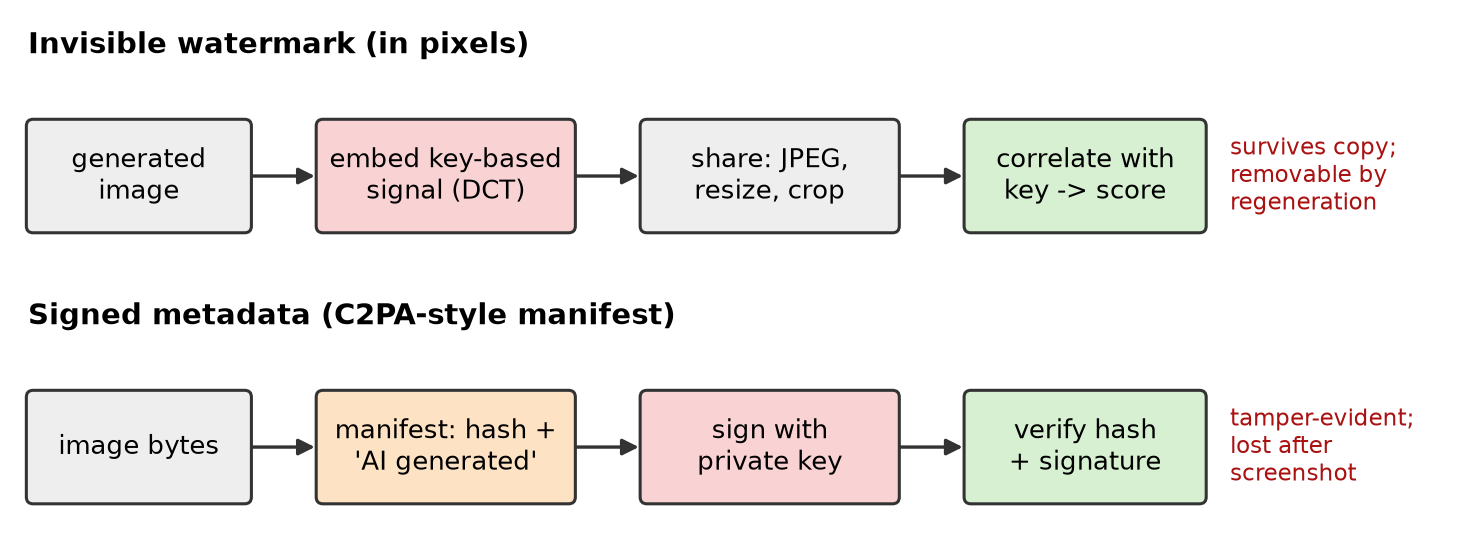

# Часть II. Практикум

## 7. Подготовка: среда, данные, оценщики

### 7.1. Задача практикума

Практикум устроен в два слоя. Первый слой — настоящий Stable Diffusion: модель SD-Turbo ([Stability AI](https://huggingface.co/stabilityai/sd-turbo)) разбирается на четыре компонента (VAE, текстовый энкодер, U-Net, планировщик), и цикл генерации собирается вручную. Второй слой — мини-модель латентной диффузии, на которой можно обучить всё остальное за минуты на CPU: адаптацию, ControlNet, IP-Adapter, inpainting. Мини-модель собрана из тех же классов библиотеки diffusers, что и Stable Diffusion (`AutoencoderKL`, `UNet2DConditionModel`, `ControlNetModel`, `DDIMScheduler`), а текстовый энкодер у неё — настоящий замороженный CLIP. Поэтому в конце её можно вставить в стандартный `StableDiffusionPipeline`.

Данные мини-модели — процедурный мир ShapeWorld: изображения 32×32 с одной или двумя фигурами и подписями вида «a large red circle on the left». Мир синтетический сознательно: для каждого изображения известны истинные сегментация, глубина, поза и атрибуты. Поэтому соблюдение условия (цвет, форма, положение, контур, поза) можно проверить численно, а не на глаз.

| Раздел | Что делаем | Что измеряем |
|---|---|---|
| 7 | среда, ShapeWorld, оценщик атрибутов и аннотатор карт | точность оценщиков |
| 8 | SD-Turbo по компонентам, ручной цикл, ограничение в 77 токенов | совпадение с пайплайном, время, CLIP score |
| 9 | мини-VAE и масштабный множитель латентов | PSNR, статистика латентов |
| 10 | мини-U-Net с cross-attention, планировщики, CFG | потери, соблюдение подписи |
| 11 | метрики: FID/KID, precision/recall, разнообразие, CLIP score | смещение метрик, компромисс CFG |
| 12 | memorization: дубликаты в обучающих данных | доля копий |
| 13 | textual inversion, DreamBooth, LoRA | точность концепта, дрейф, копирование |
| 14 | ControlNet: контуры, глубина, поза, сегментация | соблюдение управляющей карты |
| 15 | IP-Adapter | следование образцу, баланс текст/образ |
| 16 | inpainting: смешивание латентов и обученная модель | шов, соответствие подписи |
| 17 | слепая ручная оценка | доля побед, доверительный интервал, согласие |
| 18 | маркировка синтетики: водяной знак и метаданные | обнаружение после искажений |
| 19 | сводка | всё в одной таблице |

### 7.2. Режимы запуска

В Colab с GPU (`Runtime → Change runtime type → T4 GPU`) SD-Turbo работает в fp16 на 512×512, мини-модели обучаются в 3–4 раза дольше, оценочные выборки больше. На CPU автоматически включается `FAST_DEV_RUN`: SD-Turbo генерирует в bfloat16 на 384×384, шагов обучения меньше. Блокнот поставляется без сохранённых выводов: числа появятся после запуска. Ориентиры в тексте получены в пробном CPU-прогоне. На GPU и при другой версии библиотек числа будут другими, поэтому сравнивать стоит направление эффектов, а не сами значения. В GPU-режиме тестовая выборка — 4000 изображений (`n_test`): первые 2000 подписей (`n_eval`) идут на генерацию и оценку, остальные 2000 изображений — эталон для метрик, карты для ControlNet и подписи для слепой оценки. На CPU — 2000 изображений, из них 600 на оценку.

Нужно около 3 ГБ на диске для SD-Turbo (веса fp16) и около 0,6 ГБ для CLIP ViT-B/32. Если в среде нет библиотек `diffusers` и `peft`, первая ячейка их установит.

In [1]:
import os, sys, io, math, time, random, platform, copy, json, hashlib, hmac, itertools, collections, warnings
import importlib.util, subprocess
warnings.filterwarnings("ignore", message="IProgress not found")                # tqdm без ipywidgets
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1"); os.environ.setdefault("TRANSFORMERS_VERBOSITY", "error")
for pkg in ("diffusers", "peft"):
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, PngImagePlugin
from scipy import linalg, stats
import diffusers, transformers, peft
from diffusers import (AutoencoderKL, UNet2DConditionModel, ControlNetModel, DDPMScheduler, DDIMScheduler,
                       EulerDiscreteScheduler, DPMSolverMultistepScheduler, StableDiffusionPipeline)
from transformers import CLIPModel, CLIPTokenizer
warnings.filterwarnings("ignore", category=linalg.LinAlgWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
diffusers.utils.logging.set_verbosity_error(); transformers.utils.logging.set_verbosity_error()
import huggingface_hub; huggingface_hub.utils.logging.set_verbosity_error()
diffusers.utils.logging.disable_progress_bar(); transformers.utils.logging.disable_progress_bar()

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
FAST_DEV_RUN = DEVICE == "cpu"
torch.set_num_threads(max(1, os.cpu_count() or 1))
T_START = time.time()

S = dict(  # размеры выборок и число шагов оптимизатора
    n_train=60000, bs=128, steps_chk=1500, steps_ann=2000, steps_vae=4000, steps_unet=10000, ch=(64, 128),
    n_eval=2000, n_test=4000, steps_cn=4000, steps_ip=3000, n_ip=20000, steps_inp=2000, steps_ti=600, steps_db=400,
    sd_res=512, sd_dtype="float16", n_sd=6)
if FAST_DEV_RUN:
    S.update(n_train=30000, bs=64, steps_chk=500, steps_ann=600, steps_vae=1000, steps_unet=2500, ch=(48, 96),
             n_eval=600, n_test=2000, steps_cn=1200, steps_ip=900, n_ip=3000, steps_inp=600, steps_ti=300, steps_db=200,
             sd_res=384, sd_dtype="bfloat16", n_sd=4)
# Тестовая выборка делится на две непересекающиеся части: первые n_eval подписей — для генерации и оценки,
# остальные изображения — эталон для FD/KID/PRDC, карты для ControlNet (200 шт.) и подписи слепой оценки (40 шт.).
assert S["n_test"] - S["n_eval"] >= max(1000, 200), "эталонная часть теста слишком мала: увеличьте n_test или уменьшите n_eval"

def seed_all(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
seed_all(0)

class Timer:
    def __enter__(self):
        if torch.cuda.is_available(): torch.cuda.synchronize()
        self.t = time.time(); return self
    def __exit__(self, *a):
        if torch.cuda.is_available(): torch.cuda.synchronize()
        self.s = time.time() - self.t

def show(imgs, nrow=10, title=None, scale=1.0, labels=None):
    """imgs: тензор Nx3xHxW в [0, 1]."""
    imgs = imgs.detach().float().cpu().clamp(0, 1)
    if imgs.shape[1] == 1: imgs = imgs.repeat(1, 3, 1, 1)
    grid = torchvision.utils.make_grid(imgs, nrow=nrow, padding=2, pad_value=1.0)
    ncol = math.ceil(len(imgs) / nrow)
    plt.figure(figsize=(scale * nrow * 0.75, scale * ncol * 0.75 + (0.5 if title else 0)))
    plt.imshow(grid.permute(1, 2, 0).numpy(), interpolation="nearest"); plt.axis("off")
    if title: plt.title(title, fontsize=15)
    plt.tight_layout(); plt.show()

print("python", platform.python_version(), "| torch", torch.__version__, "| diffusers", diffusers.__version__,
      "| transformers", transformers.__version__, "| peft", peft.__version__)
print("device:", DEVICE, "| FAST_DEV_RUN:", FAST_DEV_RUN, "| threads:", torch.get_num_threads())
print(S)

python 3.12.6 | torch 2.14.1+cu132 | diffusers 0.42.1 | transformers 5.21.0 | peft 0.21.2
device: cuda | FAST_DEV_RUN: False | threads: 20
{'n_train': 60000, 'bs': 128, 'steps_chk': 1500, 'steps_ann': 2000, 'steps_vae': 4000, 'steps_unet': 10000, 'ch': (64, 128), 'n_eval': 2000, 'n_test': 4000, 'steps_cn': 4000, 'steps_ip': 3000, 'n_ip': 20000, 'steps_inp': 2000, 'steps_ti': 600, 'steps_db': 400, 'sd_res': 512, 'sd_dtype': 'float16', 'n_sd': 6}


### 7.3. Мир ShapeWorld

Каждое изображение 32×32 содержит одну фигуру (60 %) или две (40 %) на сером фоне случайной яркости. Фигуры: circle, square, triangle, person (схематичный человечек с суставами). Цвета: red, green, blue, yellow, magenta, cyan. Подписи двух типов:

- одна фигура: «a {small | large} {цвет} {форма} {on the left | on the right | at the top | at the bottom | in the center}», 240 вариантов;
- две фигуры: «a {цвет} {форма} on the left and a {цвет} {форма} on the right», 576 вариантов.

Вместе с изображением рисуются четыре истинные карты, те же, что используют ControlNet-модели ([Zhang et al., 2023](https://arxiv.org/abs/2302.05543)): сегментация (класс фигуры в каждом пикселе), глубина (фон — наклонный «пол», крупные фигуры ближе мелких, круг выпуклый, как шар), поза (конечности человечка, каждая своим цветом, как в OpenPose) и контуры (детектор Собеля с порогом вместо Canny). Ещё одна форма, cross, в обучающие данные диффузии не входит. Её модель увидит только в разделе 13 как «новый концепт».

Фигуры рисуются в 4 раза крупнее и уменьшаются усреднением, поэтому края сглажены. Генерация 30 000 изображений занимает несколько секунд.

60000 + 4000 images in 22.7 s; unique captions: train 816, test 784
examples: ['a red circle on the left and a yellow triangle on the right', 'a cyan circle on the left and a green person on the right', 'a large blue square at the top']


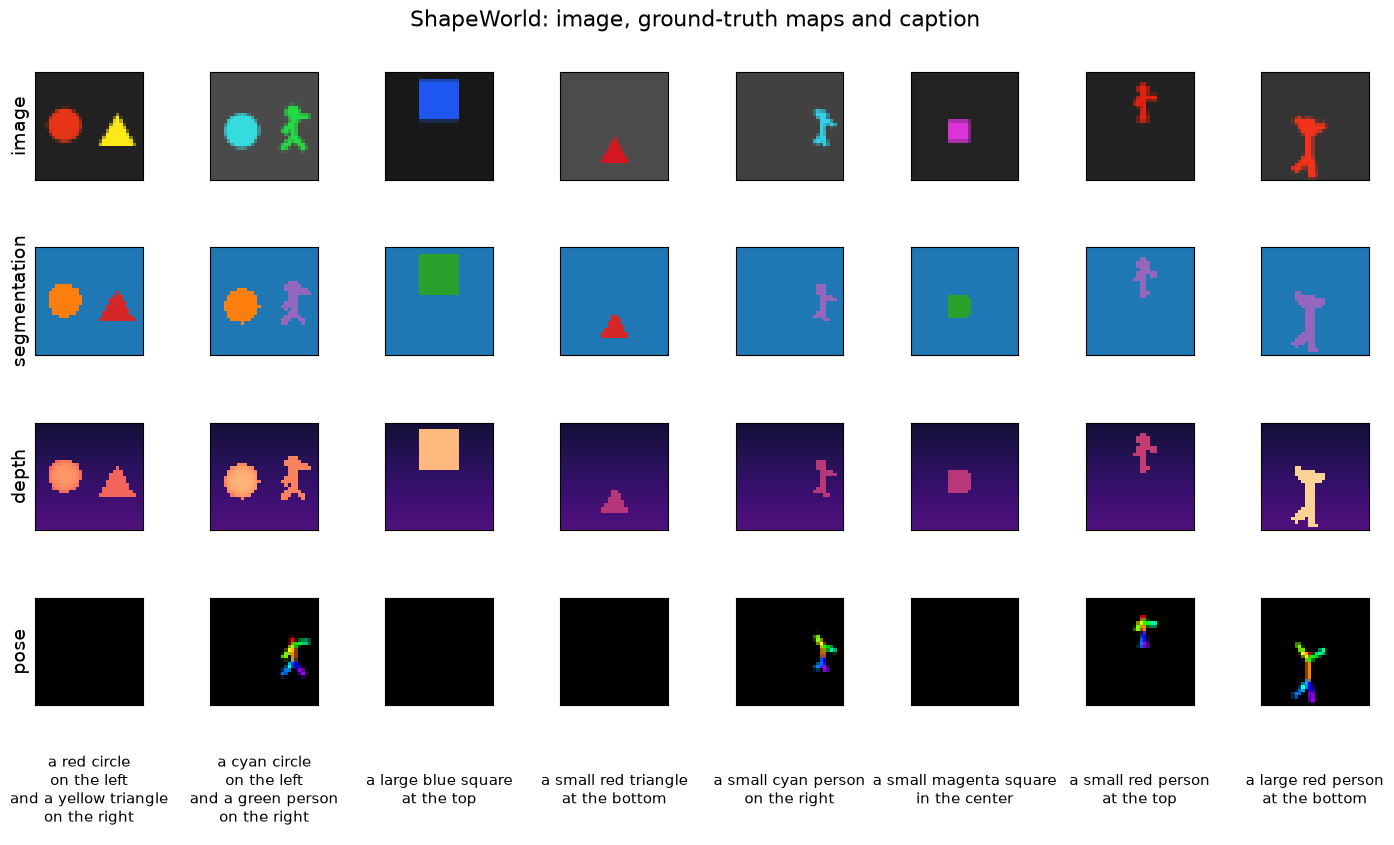

In [2]:
SHAPES = ["circle", "square", "triangle", "person", "cross"]          # cross: только для новых концептов
BASE_SHAPES = SHAPES[:4]
COLORS = {"red": (0.90, 0.15, 0.10), "green": (0.15, 0.80, 0.20), "blue": (0.15, 0.30, 0.95),
          "yellow": (0.95, 0.90, 0.15), "magenta": (0.90, 0.20, 0.85), "cyan": (0.15, 0.85, 0.90)}
CNAMES = list(COLORS)
POS = {"on the left": (8, 16), "on the right": (24, 16), "at the top": (16, 8), "at the bottom": (16, 24),
       "in the center": (16, 16)}
PNAMES = list(POS); SIZES = ["small", "large"]
LIMBS = [(1, 0), (1, 2), (1, 3), (3, 4), (1, 5), (5, 6), (2, 7), (7, 8), (2, 9), (9, 10)]   # пары ключевых точек
LIMB_COLORS = [(1, 0, 0), (1, .5, 0), (1, 1, 0), (.5, 1, 0), (0, 1, 0), (0, 1, .6), (0, 1, 1), (0, .5, 1), (0, 0, 1), (.6, 0, 1)]
R = 4                                                                     # коэффициент суперсэмплинга

def person_kp(cx, cy, r, rng):
    s = r * 1.45; kp = {0: (cx, cy - 0.72 * s), 1: (cx, cy - 0.45 * s), 2: (cx, cy + 0.15 * s)}
    def seg(p, ang, ln): return (p[0] + ln * math.sin(ang), p[1] + ln * math.cos(ang))
    for side, (e, h) in ((-1, (3, 4)), (1, (5, 6))):                      # руки: угол от вертикали вниз
        a = rng.uniform(0.3, 2.6); b = a + rng.uniform(-0.8, 0.8)
        kp[e] = seg(kp[1], side * a, 0.33 * s); kp[h] = seg(kp[e], side * b, 0.30 * s)
    for side, (k, f) in ((-1, (7, 8)), (1, (9, 10))):                     # ноги
        a = rng.uniform(0.1, 0.7); b = a + rng.uniform(-0.4, 0.4)
        kp[k] = seg(kp[2], side * a, 0.35 * s); kp[f] = seg(kp[k], side * b, 0.33 * s)
    return [kp[i] for i in range(11)]

def obj_alpha(o):
    """Маска фигуры с антиалиасингом: рисуем на холсте 128×128 и уменьшаем до 32×32."""
    m = Image.new("L", (32 * R, 32 * R), 0); d = ImageDraw.Draw(m)
    cx, cy, r = o["cx"] * R, o["cy"] * R, o["r"] * R; sh = o["shape"]
    if sh == "circle": d.ellipse([cx - r, cy - r, cx + r, cy + r], fill=255)
    elif sh == "square": h = 0.8 * r; d.rectangle([cx - h, cy - h, cx + h, cy + h], fill=255)
    elif sh == "triangle": d.polygon([(cx, cy - r), (cx - r, cy + 0.8 * r), (cx + r, cy + 0.8 * r)], fill=255)
    elif sh == "cross":
        w = 0.3 * r; d.rectangle([cx - r, cy - w, cx + r, cy + w], fill=255); d.rectangle([cx - w, cy - r, cx + w, cy + r], fill=255)
    elif sh == "person":
        kp = [(x * R, y * R) for x, y in o["kp"]]; w = int(0.32 * o["r"] * R) + 2; hr = 0.26 * o["r"] * 1.45 * R
        for a, b in LIMBS[1:]: d.line([kp[a], kp[b]], fill=255, width=w)
        d.ellipse([kp[0][0] - hr, kp[0][1] - hr, kp[0][0] + hr, kp[0][1] + hr], fill=255)
    return np.asarray(m.resize((32, 32), Image.BOX), dtype=np.float32) / 255

def pose_map(objs):
    m = Image.new("RGB", (32 * R, 32 * R), (0, 0, 0)); d = ImageDraw.Draw(m)
    for o in objs:
        if o["shape"] != "person": continue
        kp = [(x * R, y * R) for x, y in o["kp"]]
        for (a, b), c in zip(LIMBS, LIMB_COLORS): d.line([kp[a], kp[b]], fill=tuple(int(255 * v) for v in c), width=6)
    return np.asarray(m.resize((32, 32), Image.BOX), dtype=np.float32).transpose(2, 0, 1) / 255

YY, XX = np.mgrid[0:32, 0:32].astype(np.float32) + 0.5
def render(objs, bg):
    img = np.ones((3, 32, 32), np.float32) * bg; seg = np.zeros((32, 32), np.uint8)
    depth = 0.10 + 0.15 * YY / 32                                         # «пол»: низ кадра ближе
    for o in sorted(objs, key=lambda o: o["z"]):                          # дальние рисуются первыми
        a = obj_alpha(o); col = np.array(o["rgb"], np.float32)[:, None, None]
        img = img * (1 - a) + col * a; inside = a > 0.5
        seg[inside] = SHAPES.index(o["shape"]) + 1
        dz = np.full((32, 32), o["z"], np.float32)
        if o["shape"] == "circle": dz += 0.12 * np.sqrt(np.clip(1 - ((XX - o["cx"]) ** 2 + (YY - o["cy"]) ** 2) / o["r"] ** 2, 0, 1))
        depth = np.where(inside, dz, depth)
    return img.clip(0, 1), seg, depth.clip(0, 1), pose_map(objs)

def make_obj(rng, shape, color, cx, cy, r, z):
    rgb = tuple(np.clip(np.array(COLORS[color]) + np.array([rng.uniform(-0.07, 0.07) for _ in range(3)]), 0, 1))
    o = dict(shape=shape, color=color, cx=cx, cy=cy, r=r, z=z, rgb=rgb)
    if shape == "person": o["kp"] = person_kp(cx, cy, r, rng)
    return o

def sample_scene(rng, shapes=BASE_SHAPES, p_double=0.4, force=None):
    """force: словарь с фиксированными атрибутами (shape, color, pos, size или shape2, color2)."""
    f = force or {}
    if (f.get("double") if "double" in f else rng.random() < p_double):
        s1, s2 = f.get("shape", rng.choice(shapes)), f.get("shape2", rng.choice(shapes))
        c1, c2 = f.get("color", rng.choice(CNAMES)), f.get("color2", rng.choice(CNAMES))
        objs = [make_obj(rng, s1, c1, 8 + rng.uniform(-1.5, 1.5), 16 + rng.uniform(-3, 3), rng.uniform(4.5, 5.5), 0.7 + rng.uniform(-.05, .05)),
                make_obj(rng, s2, c2, 24 + rng.uniform(-1.5, 1.5), 16 + rng.uniform(-3, 3), rng.uniform(4.5, 5.5), 0.7 + rng.uniform(-.05, .05))]
        cap = f"a {c1} {s1} on the left and a {c2} {s2} on the right"
        lab = (2, shapes_id(s1), CNAMES.index(c1), -1, -1, shapes_id(s2), CNAMES.index(c2))
    else:
        s, c = f.get("shape", rng.choice(shapes)), f.get("color", rng.choice(CNAMES))
        p, sz = f.get("pos", rng.choice(PNAMES)), f.get("size", rng.choice(SIZES))
        cx, cy = POS[p]; r = rng.uniform(3.5, 4.5) if sz == "small" else rng.uniform(6.5, 7.5)
        objs = [make_obj(rng, s, c, cx + rng.uniform(-2, 2), cy + rng.uniform(-2, 2), r, (0.5 if sz == "small" else 0.9) + rng.uniform(-.05, .05))]
        cap = f"a {sz} {c} {s} {p}"
        lab = (1, shapes_id(s), CNAMES.index(c), PNAMES.index(p), SIZES.index(sz), -1, -1)
    return objs, cap, lab

def shapes_id(s): return SHAPES.index(s)

def make_dataset(n, seed, **kw):
    rng = random.Random(seed); X = np.zeros((n, 3, 32, 32), np.uint8); SEG = np.zeros((n, 32, 32), np.uint8)
    DEP = np.zeros((n, 32, 32), np.uint8); POSE = np.zeros((n, 3, 32, 32), np.uint8); caps, labs = [], []
    for i in range(n):
        objs, cap, lab = sample_scene(rng, **kw)
        img, seg, dep, pose = render(objs, rng.uniform(0.05, 0.30))
        X[i] = (img * 255).round(); SEG[i] = seg; DEP[i] = (dep * 255).round(); POSE[i] = (pose * 255).round()
        caps.append(cap); labs.append(lab)
    return dict(X=torch.from_numpy(X), SEG=torch.from_numpy(SEG), DEP=torch.from_numpy(DEP), POSE=torch.from_numpy(POSE),
                caps=caps, lab=torch.tensor(labs))

u8 = lambda t: t.float() / 255                                            # uint8 → [0, 1]
with Timer() as t:
    TR = make_dataset(S["n_train"], seed=1)
    TE = make_dataset(S["n_test"], seed=2)                                # тест: те же правила, другие случайные сцены
print(f"{S['n_train']} + {S['n_test']} images in {t.s:.1f} s; unique captions: train {len(set(TR['caps']))}, test {len(set(TE['caps']))}")
print("examples:", TR["caps"][:3])

fig, ax = plt.subplots(5, 8, figsize=(14, 8.6), gridspec_kw=dict(height_ratios=[1, 1, 1, 1, 0.55]))
pers = [i for i in range(6, 300) if TR["lab"][i, 0] == 1 and TR["lab"][i, 1] == 3][:2]   # два примера с человечками
for j, i in enumerate([0, 1, 2, 3, 4, 5] + pers):
    ax[0, j].imshow(u8(TR["X"][i]).permute(1, 2, 0)); ax[1, j].imshow(TR["SEG"][i], cmap="tab10", vmin=0, vmax=9)
    ax[2, j].imshow(TR["DEP"][i], cmap="magma", vmin=0, vmax=255); ax[3, j].imshow(u8(TR["POSE"][i]).permute(1, 2, 0))
    ax[4, j].text(0.5, 0.5, TR["caps"][i].replace(" on the", "\non the").replace(" and", "\nand").replace(" at the", "\nat the").replace(" in the", "\nin the"),
                  ha="center", va="center", fontsize=11)
for a in ax.ravel(): a.set_xticks([]); a.set_yticks([])
for a in ax[4]: a.axis("off")
for r_, name in enumerate(["image", "segmentation", "depth", "pose"]): ax[r_, 0].set_ylabel(name, fontsize=14)
plt.suptitle("ShapeWorld: image, ground-truth maps and caption", fontsize=16); plt.tight_layout(); plt.show()

### 7.4. Оценщик атрибутов и аннотатор карт

Чтобы проверять соблюдение условия, нужны два «судьи», обученные на настоящих данных ShapeWorld (с крестами, чтобы судьи их знали).

- Оценщик атрибутов — свёрточный классификатор с головами «число фигур», «форма», «цвет», «положение», «размер», а для двух фигур — «форма и цвет справа». Его 256-мерный предпоследний слой служит пространством признаков для FID, KID, precision/recall и разнообразия. Это тот же приём, что в лекциях 12–13: признаки Inception для изображений 32×32 из синтетического мира малоинформативны.
- Аннотатор — маленькая полносвёрточная сеть, которая по изображению предсказывает сегментацию, глубину и позу. Это аналог «препроцессоров» ControlNet (OpenPose, MiDaS, сегментаторов). В разделе 14 он применяется к сгенерированным изображениям, и карта, которую он «видит», сравнивается с заданной.

Контуры извлекаются без обучения: оператор Собеля по каждому каналу RGB и порог 0,25.

In [3]:
class Checker(nn.Module):
    HEADS = dict(nobj=2, sh1=5, co1=6, pos1=5, size1=2, sh2=5, co2=6)
    def __init__(self):
        super().__init__()
        self.f = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.Conv2d(32, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Flatten(), nn.Linear(64 * 16, 256), nn.ReLU())
        self.heads = nn.ModuleDict({k: nn.Linear(256, v) for k, v in self.HEADS.items()})
    def forward(self, x):
        h = self.f(x * 2 - 1); return h, {k: m(h) for k, m in self.heads.items()}

class Annotator(nn.Module):
    """Изображение → сегментация (6 классов), глубина (1), поза (3)."""
    def __init__(self, c=32):
        super().__init__()
        blk = lambda i, o: nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.ReLU(), nn.Conv2d(o, o, 3, padding=1), nn.ReLU())
        self.e1, self.e2, self.e3 = blk(3, c), blk(c, 2 * c), blk(2 * c, 2 * c)
        self.d2, self.d1 = blk(4 * c, 2 * c), blk(3 * c, c); self.out = nn.Conv2d(c, 10, 1)
    def forward(self, x):
        x = x * 2 - 1; h1 = self.e1(x); h2 = self.e2(F.avg_pool2d(h1, 2)); h3 = self.e3(F.avg_pool2d(h2, 2))
        h = self.d2(torch.cat([F.interpolate(h3, scale_factor=2), h2], 1)); h = self.d1(torch.cat([F.interpolate(h, scale_factor=2), h1], 1))
        o = self.out(h); return o[:, :6], torch.sigmoid(o[:, 6]), torch.sigmoid(o[:, 7:])

def sobel_edges(x, thr=0.25):
    """x: N×3×H×W в [0, 1] → бинарная карта контуров N×1×H×W."""
    k = torch.tensor([[-1., 0, 1], [-2, 0, 2], [-1, 0, 1]], device=x.device) / 4
    w = torch.stack([k, k.t()]).unsqueeze(1).repeat(3, 1, 1, 1)
    g = F.conv2d(F.pad(x, (1, 1, 1, 1), mode="replicate"), w, groups=3).view(len(x), 3, 2, *x.shape[-2:])
    return (g.pow(2).sum(2).sqrt().amax(1, keepdim=True) > thr).float()

seed_all(0)
CHK_DATA = make_dataset(12000, seed=3, shapes=SHAPES)                     # с крестами
chk, ann = Checker().to(DEVICE), Annotator().to(DEVICE)
with Timer() as t:
    opt = torch.optim.Adam(chk.parameters(), 1e-3); g = torch.Generator().manual_seed(0)
    for step in range(S["steps_chk"]):
        i = torch.randint(0, 12000, (128,), generator=g)
        x = u8(CHK_DATA["X"][i]).to(DEVICE); lab = CHK_DATA["lab"][i].to(DEVICE)
        x = (x + 0.03 * torch.randn_like(x)).clamp(0, 1)                   # лёгкий шум: судья не должен быть хрупким
        _, out = chk(x); loss = 0
        for j, k in enumerate(Checker.HEADS):
            y = lab[:, j] - (1 if k == "nobj" else 0); m = y >= 0
            if m.any(): loss = loss + F.cross_entropy(out[k][m], y[m])
        opt.zero_grad(); loss.backward(); opt.step()
t_chk = t.s
with Timer() as t:
    opt = torch.optim.Adam(ann.parameters(), 2e-3)
    for step in range(S["steps_ann"]):
        i = torch.randint(0, 12000, (48,), generator=g)
        x = u8(CHK_DATA["X"][i]).to(DEVICE)
        sg, dp, ps = ann((x + 0.03 * torch.randn_like(x)).clamp(0, 1))
        loss = F.cross_entropy(sg, CHK_DATA["SEG"][i].long().to(DEVICE)) + 5 * F.l1_loss(dp, u8(CHK_DATA["DEP"][i]).to(DEVICE)) \
               + 5 * F.binary_cross_entropy(ps, u8(CHK_DATA["POSE"][i]).to(DEVICE))   # BCE: с L1 тонкие линии позы «схлопываются» в нули
        opt.zero_grad(); loss.backward(); opt.step()
t_ann = t.s
chk.eval().requires_grad_(False); ann.eval().requires_grad_(False)

@torch.no_grad()
def judge(x01, bs=500):
    """Признаки (N×256) и предсказанные атрибуты (словарь N-векторов)."""
    fs, outs = [], {k: [] for k in Checker.HEADS}
    for i in range(0, len(x01), bs):
        h, o = chk(x01[i:i + bs].to(DEVICE).float().clamp(0, 1)); fs.append(h.cpu())
        for k in o: outs[k].append(o[k].argmax(1).cpu())
    p = {k: torch.cat(v) for k, v in outs.items()}; p["nobj"] = p["nobj"] + 1
    return torch.cat(fs).double().numpy(), p

@torch.no_grad()
def annotate(x01, bs=500):
    r = [ann(x01[i:i + bs].to(DEVICE).float().clamp(0, 1)) for i in range(0, len(x01), bs)]
    return torch.cat([a[0].argmax(1).cpu() for a in r]), torch.cat([a[1].cpu() for a in r]), torch.cat([a[2].cpu() for a in r])

pose_mask = lambda p: (p.amax(1) > 0.25)                                  # пиксели, где нарисована хоть одна конечность
def mask_iou(a, b): return float((a & b).sum() / (a | b).sum().clamp(min=1))

def miou(pred, gt, ncls=6):
    ious = []
    for c in range(ncls):
        inter = ((pred == c) & (gt == c)).sum().item(); union = ((pred == c) | (gt == c)).sum().item()
        if union > 0: ious.append(inter / union)
    return float(np.mean(ious))

def attr_acc(p, lab):
    """Доли верных атрибутов относительно заданных меток (формат lab как в sample_scene)."""
    lab = lab.cpu(); one, two = lab[:, 0] == 1, lab[:, 0] == 2; r = {"count": (p["nobj"] == lab[:, 0]).float().mean().item()}
    if one.any():
        for k, j in (("shape", 1), ("color", 2), ("pos", 3), ("size", 4)):
            r[k] = (p[["sh1", "sh1", "co1", "pos1", "size1"][j]][one] == lab[one, j]).float().mean().item()
        r["all1"] = ((p["sh1"] == lab[:, 1]) & (p["co1"] == lab[:, 2]) & (p["pos1"] == lab[:, 3]) & (p["size1"] == lab[:, 4]) & (p["nobj"] == 1))[one].float().mean().item()
    if two.any():
        ok = (p["sh1"] == lab[:, 1]) & (p["co1"] == lab[:, 2]) & (p["sh2"] == lab[:, 5]) & (p["co2"] == lab[:, 6]) & (p["nobj"] == 2)
        r["all2"] = ok[two].float().mean().item()
        r["colors2"] = ((p["co1"] == lab[:, 2]) & (p["co2"] == lab[:, 6]))[two].float().mean().item()
    return r

F_TE, P_TE = judge(u8(TE["X"]))
acc_te = attr_acc(P_TE, TE["lab"])
s_te, d_te, p_te = annotate(u8(TE["X"]))
print(f"checker {t_chk:.0f} s, annotator {t_ann:.0f} s")
print("checker on real test:", {k: round(v, 3) for k, v in acc_te.items()})
print(f"annotator on real test: seg mIoU {miou(s_te, TE['SEG'].long()):.3f} | depth MAE {(d_te - u8(TE['DEP'])).abs().mean():.4f} | "
      f"pose limb IoU {mask_iou(pose_mask(p_te), pose_mask(u8(TE['POSE']))):.3f}")
CX = make_dataset(300, seed=4, shapes=["cross"], p_double=0)
print("checker: crosses recognised as cross:", f"{(judge(u8(CX['X']))[1]['sh1'] == 4).float().mean():.3f}")

checker 50 s, annotator 50 s
checker on real test: {'count': 1.0, 'shape': 0.999, 'color': 1.0, 'pos': 1.0, 'size': 1.0, 'all1': 0.998, 'all2': 0.998, 'colors2': 1.0}
annotator on real test: seg mIoU 0.765 | depth MAE 0.0122 | pose limb IoU 0.745
checker: crosses recognised as cross: 1.000


## 8. Stable Diffusion по компонентам: SD-Turbo

### 8.1. Четыре компонента пайплайна

SD-Turbo — это Stable Diffusion 2.1, дистиллированный методом adversarial diffusion distillation (ADD, лекция 13) для генерации за 1–4 шага ([Sauer et al., 2023](https://arxiv.org/abs/2311.17042); [карточка модели](https://huggingface.co/stabilityai/sd-turbo)). Архитектура у него та же, что у SD 2.1, поэтому на нём удобно разобрать все компоненты, не дожидаясь 50 шагов на CPU. Пайплайн diffusers — это просто контейнер: в `pipe.components` лежат VAE, токенизатор, текстовый энкодер, U-Net и планировщик. Каждый можно вызвать отдельно.

In [4]:
from diffusers import AutoPipelineForInpainting, AutoPipelineForImage2Image, AutoencoderTiny
SD_ID = "stabilityai/sd-turbo"
SD_DTYPE = getattr(torch, S["sd_dtype"])
with Timer() as t:
    pipe = StableDiffusionPipeline.from_pretrained(SD_ID, torch_dtype=SD_DTYPE, variant="fp16",
                                                   safety_checker=None, requires_safety_checker=False).to(DEVICE)
pipe.set_progress_bar_config(disable=True)
print(f"loaded in {t.s:.0f} s")
nparam = lambda m: sum(p.numel() for p in m.parameters())
for name, comp in pipe.components.items():
    if comp is None: continue
    extra = f"{nparam(comp) / 1e6:8.1f} M params" if isinstance(comp, nn.Module) else ""
    print(f"{name:14s} {type(comp).__name__:28s} {extra}")
vc, uc, tc = pipe.vae.config, pipe.unet.config, pipe.text_encoder.config
VAE_F = 2 ** (len(vc.block_out_channels) - 1)
print(f"\nVAE: downsampling ×{VAE_F}, latent channels {vc.latent_channels}, scaling_factor {vc.scaling_factor}")
print(f"text encoder: {tc.num_hidden_layers} layers, hidden {tc.hidden_size}, max tokens {pipe.tokenizer.model_max_length}")
print(f"U-Net: in {uc.in_channels} ch, blocks {uc.block_out_channels}, cross_attention_dim {uc.cross_attention_dim}, "
      f"sample_size {uc.sample_size} (→ {uc.sample_size * VAE_F} px)")
print("scheduler:", type(pipe.scheduler).__name__, {k: pipe.scheduler.config[k] for k in
      ("beta_schedule", "beta_start", "beta_end", "prediction_type", "timestep_spacing")})

loaded in 12 s
vae            AutoencoderKL                    83.7 M params
text_encoder   CLIPTextModel                   340.4 M params
tokenizer      CLIPTokenizer                
unet           UNet2DConditionModel            865.9 M params
scheduler      EulerDiscreteScheduler       

VAE: downsampling ×8, latent channels 4, scaling_factor 0.18215
text encoder: 23 layers, hidden 1024, max tokens 77
U-Net: in 4 ch, blocks [320, 640, 1280, 1280], cross_attention_dim 1024, sample_size 64 (→ 512 px)
scheduler: EulerDiscreteScheduler {'beta_schedule': 'scaled_linear', 'beta_start': 0.00085, 'beta_end': 0.012, 'prediction_type': 'epsilon', 'timestep_spacing': 'trailing'}


### 8.2. VAE: сжатие в 48 раз

Изображение $512 \times 512 \times 3$ VAE сжимает в латент $64 \times 64 \times 4$, то есть в 48 раз по числу чисел. Латент умножается на `scaling_factor` (0,18215 у SD 1.x и 2.x), чтобы его дисперсия была близка к единице: так подобрано в LDM ([Rombach et al., 2022](https://arxiv.org/abs/2112.10752)), и это важно для расписания шума, рассчитанного на данные единичной дисперсии. Ниже — реконструкция фотографии из COCO и сравнение с TAESD ([madebyollin/taesd](https://huggingface.co/madebyollin/taesd)), крошечным декодером того же латентного пространства, который используют для быстрого предпросмотра.

image (3, 512, 512) = 786432 numbers -> latent (4, 64, 64) = 16384 numbers (×48)
raw latent std 4.388; scaled latent mean -0.377, std 0.799
VAE: encode 0.8 s, decode 0.4 s, PSNR 23.29 dB | TAESD decode 0.10 s (1.2 M params), PSNR 20.82 dB


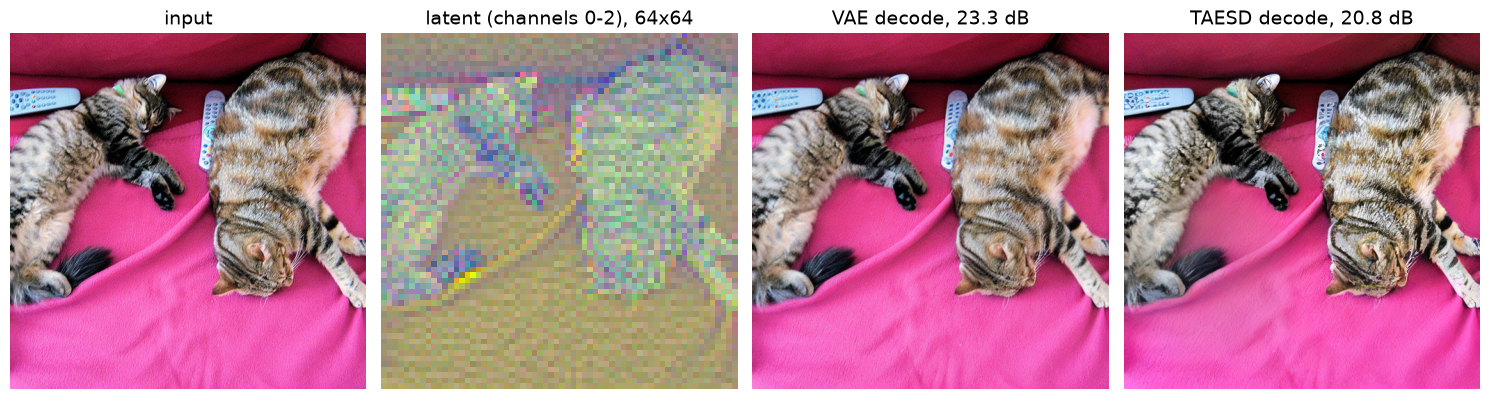

In [5]:
import urllib.request
COCO_URL = "http://images.cocodataset.org/val2017/000000039769.jpg"          # две кошки на диване
photo = Image.open(io.BytesIO(urllib.request.urlopen(COCO_URL, timeout=60).read())).convert("RGB")
side = min(photo.size); res = S["sd_res"]
photo = photo.crop(((photo.width - side) // 2, (photo.height - side) // 2, (photo.width + side) // 2, (photo.height + side) // 2)).resize((res, res), Image.LANCZOS)
to_t = lambda im: torch.from_numpy(np.asarray(im, dtype=np.float32) / 255).permute(2, 0, 1)[None]
x_ph = to_t(photo)
psnr = lambda a, b: float(10 * torch.log10(1 / F.mse_loss(a.float().clamp(0, 1), b.float().clamp(0, 1))))
with torch.no_grad(), Timer() as t_enc:
    lat = pipe.vae.encode((x_ph * 2 - 1).to(DEVICE, SD_DTYPE)).latent_dist.mean
with torch.no_grad(), Timer() as t_dec:
    rec = (pipe.vae.decode(lat).sample.float().cpu() + 1) / 2
taesd = AutoencoderTiny.from_pretrained("madebyollin/taesd", torch_dtype=SD_DTYPE).to(DEVICE)
with torch.no_grad(), Timer() as t_tiny:
    rec_t = (taesd.decode(lat * vc.scaling_factor).sample.float().cpu() + 1) / 2   # TAESD ждёт масштабированный латент
z = lat.float() * vc.scaling_factor
print(f"image {tuple(x_ph.shape[1:])} = {x_ph.numel()} numbers -> latent {tuple(lat.shape[1:])} = {lat.numel()} numbers "
      f"(×{x_ph.numel() / lat.numel():.0f})")
print(f"raw latent std {lat.float().std():.3f}; scaled latent mean {z.mean():.3f}, std {z.std():.3f}")
print(f"VAE: encode {t_enc.s:.1f} s, decode {t_dec.s:.1f} s, PSNR {psnr(rec, x_ph):.2f} dB | "
      f"TAESD decode {t_tiny.s:.2f} s ({nparam(taesd.decoder) / 1e6:.1f} M params), PSNR {psnr(rec_t, x_ph):.2f} dB")
fig, ax = plt.subplots(1, 4, figsize=(15, 4.2))
ax[0].imshow(photo); ax[0].set_title("input", fontsize=14)
ax[1].imshow(z[0, :3].permute(1, 2, 0).sub(z.min()).div(z.max() - z.min()).cpu()); ax[1].set_title(f"latent (channels 0-2), {lat.shape[-1]}x{lat.shape[-1]}", fontsize=14)
ax[2].imshow(rec[0].clamp(0, 1).permute(1, 2, 0)); ax[2].set_title(f"VAE decode, {psnr(rec, x_ph):.1f} dB", fontsize=14)
ax[3].imshow(rec_t[0].clamp(0, 1).permute(1, 2, 0)); ax[3].set_title(f"TAESD decode, {psnr(rec_t, x_ph):.1f} dB", fontsize=14)
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

### 8.3. Текстовый энкодер и предел в 77 токенов

Подпись превращается в последовательность из ровно 77 векторов: токенизатор CLIP добавляет начальный и конечный токены, а остаток заполняет токеном-заполнителем. Всё, что длиннее 75 содержательных токенов, молча отбрасывается. U-Net видит все 77 векторов через cross-attention, а не только итоговый эмбеддинг подписи.

In [6]:
tok = pipe.tokenizer
short = "a red fox in the snow"
long_p = ("a highly detailed photograph of a red fox sitting in a snowy pine forest at golden hour, soft warm light, "
          "shallow depth of field, bokeh, frost on the fur, breath visible in the cold air, award winning wildlife photography, "
          "shot on a telephoto lens, ultra sharp focus on the eyes, gentle snowfall in the background, "
          "and a small wooden cabin with a glowing window far behind the trees")
for p in (short, long_p):
    ids = tok(p, truncation=False).input_ids
    kept = tok(p, truncation=True, max_length=tok.model_max_length).input_ids
    print(f"{len(p.split()):3d} words -> {len(ids)} tokens; kept {len(kept)}")
lost = tok.decode(tok(long_p, truncation=False).input_ids[tok.model_max_length - 1:-1])
print("dropped tail:", repr(lost))
with torch.no_grad():
    ids = tok([short], padding="max_length", max_length=tok.model_max_length, return_tensors="pt").input_ids.to(DEVICE)
    emb = pipe.text_encoder(ids)[0]
print("first tokens:", tok.convert_ids_to_tokens(ids[0, :10].tolist()))
print("embedding shape:", tuple(emb.shape))

  6 words -> 8 tokens; kept 8
 68 words -> 82 tokens; kept 77
dropped tail: 'window far behind the trees'
first tokens: ['<|startoftext|>', 'a</w>', 'red</w>', 'fox</w>', 'in</w>', 'the</w>', 'snow</w>', '<|endoftext|>', '!', '!']
embedding shape: (1, 77, 1024)


### 8.4. Цикл генерации вручную

Ниже воспроизведён `pipe(...)` в шесть строк: шум в латентном пространстве, масштабирование входа планировщиком, предсказание шума U-Net, шаг планировщика, деление на `scaling_factor` и декодирование VAE. SD-Turbo обучен без classifier-free guidance, поэтому `guidance_scale=0` и безусловная ветка не нужна. Совпадение с библиотечным вызовом проверяется на одном и том же начальном шуме.

In [7]:
@torch.no_grad()
def sd_manual(prompt, latents, steps=1):
    ids = tok([prompt], padding="max_length", max_length=tok.model_max_length, truncation=True, return_tensors="pt").input_ids.to(DEVICE)
    cond = pipe.text_encoder(ids)[0]
    sch = pipe.scheduler; sch.set_timesteps(steps, device=DEVICE)
    lat = latents * sch.init_noise_sigma
    for t_ in sch.timesteps:
        eps = pipe.unet(sch.scale_model_input(lat, t_), t_, encoder_hidden_states=cond).sample
        lat = sch.step(eps, t_, lat).prev_sample
    return ((pipe.vae.decode(lat / vc.scaling_factor).sample.float().cpu() + 1) / 2).clamp(0, 1)

PROMPTS = ["a photo of a red fox sitting in a snowy forest, golden hour",
           "an astronaut riding a horse on the moon, digital art",
           "a cozy wooden cabin by a mountain lake, watercolor painting",
           "a bowl of ramen with chopsticks, studio photo, top view",
           "a lighthouse on a rocky coast during a storm, oil painting",
           "a cute robot reading a book in a library, 3d render"][:S["n_sd"]]
lat_shape = (1, 4, res // VAE_F, res // VAE_F)
noise0 = torch.randn(lat_shape, generator=torch.Generator().manual_seed(0)).to(DEVICE, SD_DTYPE)
with Timer() as t_man: img_man = sd_manual(PROMPTS[0], noise0.clone())
with Timer() as t_pipe:
    img_pipe = pipe(PROMPTS[0], num_inference_steps=1, guidance_scale=0.0, latents=noise0.clone(), height=res, width=res, output_type="pt").images.float().cpu()
print(f"timesteps for 1 step: {pipe.scheduler.timesteps.tolist()}")
print(f"manual loop {t_man.s:.1f} s, pipeline {t_pipe.s:.1f} s, max |difference| = {(img_man - img_pipe).abs().max():.4f}")

timesteps for 1 step: [999.0]
manual loop 0.9 s, pipeline 0.6 s, max |difference| = 0.0002


### 8.5. Шаги, время и CLIP score

CLIP score оценивает согласие изображения и подписи как косинус их эмбеддингов в CLIP, умноженный на 100 и обрезанный снизу нулём ([Hessel et al., 2021](https://arxiv.org/abs/2104.08718); в исходной статье множитель 2,5). Для оценки берётся другая модель CLIP (OpenAI ViT-B/32), а не OpenCLIP ViT-H, на котором обучен текстовый энкодер SD 2: иначе метрика оценивала бы модель её же «глазами». Проверка простая: каждое изображение сравнивается со всеми подписями, и на диагонали матрицы должен стоять максимум строки.

1 step: 0.5 s per image at 512x512; steps 1/2/4 for one prompt: 0.6 s, 0.6 s, 0.8 s
CLIP score matrix (rows: images, columns: prompts):
    34.38   8.54   9.96  13.54   3.41  11.94 <- argmax 0
    14.49  36.60  10.19  20.01   9.21  18.56 <- argmax 1
    11.09  11.78  36.31  13.25  14.76  11.82 <- argmax 2
    10.58  10.18   4.58  31.56   4.06  12.16 <- argmax 3
     5.95  12.93  15.20  12.86  36.41   8.27 <- argmax 4
     9.35  15.88   7.56  14.80   6.06  37.88 <- argmax 5
matched CLIP score 35.52 vs mismatched 11.10


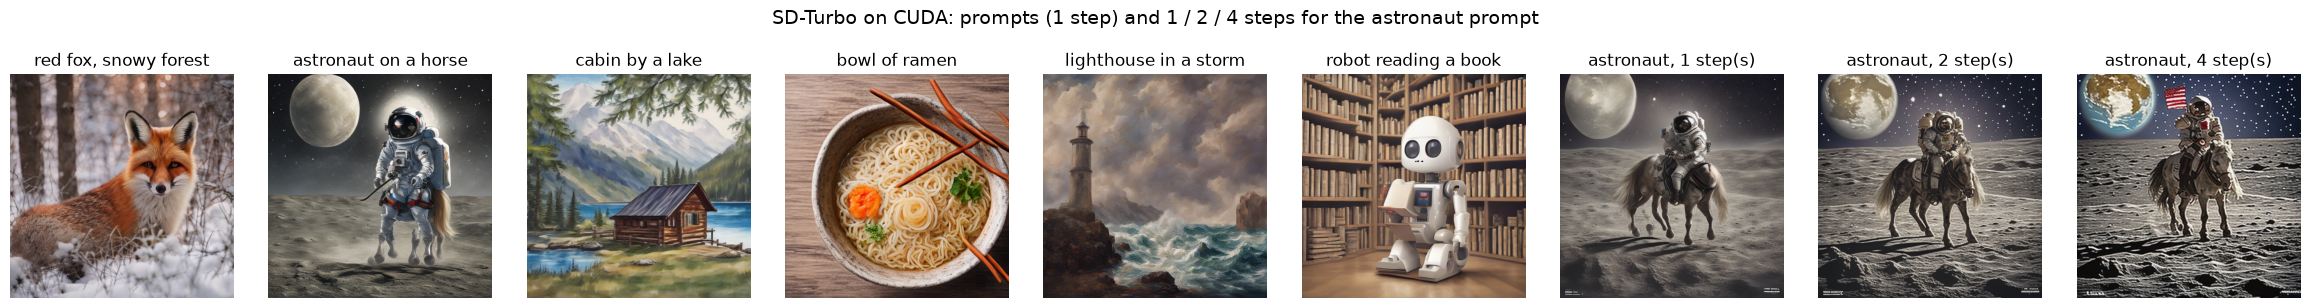

In [8]:
clip_model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(DEVICE).eval().requires_grad_(False)
clip_tok = CLIPTokenizer.from_pretrained("openai/clip-vit-base-patch32")
CLIP_MEAN = torch.tensor([0.4815, 0.4578, 0.4082]).view(1, 3, 1, 1); CLIP_STD = torch.tensor([0.2686, 0.2613, 0.2758]).view(1, 3, 1, 1)
def _feat(o): return o if torch.is_tensor(o) else (o.image_embeds if getattr(o, "image_embeds", None) is not None else o.pooler_output)

@torch.no_grad()
def clip_img_emb(x01, size=224, bs=64):
    out = []
    for i in range(0, len(x01), bs):
        xb = F.interpolate(x01[i:i + bs].float().cpu(), size=(size, size), mode="bicubic", align_corners=False).clamp(0, 1)
        xb = ((xb - CLIP_MEAN) / CLIP_STD).to(DEVICE)
        out.append(F.normalize(_feat(clip_model.get_image_features(pixel_values=xb, interpolate_pos_encoding=size != 224)).float(), dim=-1).cpu())
    return torch.cat(out)

@torch.no_grad()
def clip_txt_emb(texts, bs=256):
    out = []
    for i in range(0, len(texts), bs):
        b = clip_tok(texts[i:i + bs], padding=True, truncation=True, return_tensors="pt").to(DEVICE)
        out.append(F.normalize(_feat(clip_model.get_text_features(**b)).float(), dim=-1).cpu())
    return torch.cat(out)

def clip_score(img_emb, txt_emb): return 100 * (img_emb * txt_emb).sum(-1).clamp(min=0)

SD_IMAGES, sd_times = [], []
for i, p in enumerate(PROMPTS):
    nz = torch.randn(lat_shape, generator=torch.Generator().manual_seed(100 + i)).to(DEVICE, SD_DTYPE)
    with Timer() as t: SD_IMAGES.append(sd_manual(p, nz, steps=1))
    sd_times.append(t.s)
steps_imgs, steps_t = [], []
for st in (1, 2, 4):
    with Timer() as t: steps_imgs.append(sd_manual(PROMPTS[1], noise0.clone(), steps=st))
    steps_t.append(t.s)
SD_X = torch.cat(SD_IMAGES)
cs = 100 * clip_img_emb(SD_X) @ clip_txt_emb(PROMPTS).T
print(f"1 step: {np.mean(sd_times):.1f} s per image at {res}x{res}; steps 1/2/4 for one prompt: " + ", ".join(f"{s_:.1f} s" for s_ in steps_t))
print("CLIP score matrix (rows: images, columns: prompts):")
for i in range(len(PROMPTS)): print("  ", " ".join(f"{v:6.2f}" for v in cs[i].tolist()), "<- argmax", int(cs[i].argmax()))
print(f"matched CLIP score {cs.diag().mean():.2f} vs mismatched {cs[~torch.eye(len(PROMPTS), dtype=bool)].mean():.2f}")
ims = list(SD_X) + list(torch.cat(steps_imgs))
SHORT = ["red fox, snowy forest", "astronaut on a horse", "cabin by a lake", "bowl of ramen", "lighthouse in a storm", "robot reading a book"]
ttl = SHORT[:len(PROMPTS)] + [f"astronaut, {s_} step(s)" for s_ in (1, 2, 4)]
nc = len(ims); fig, ax = plt.subplots(1, nc, figsize=(2.6 * nc, 3.1))
for a, im, tt in zip(ax, ims, ttl):
    a.imshow(im.permute(1, 2, 0)); a.set_title(tt, fontsize=12); a.axis("off")
plt.suptitle("SD-Turbo on " + DEVICE.upper() + ": prompts (1 step) and 1 / 2 / 4 steps for the astronaut prompt", fontsize=14)
plt.tight_layout(rect=(0, 0, 1, 0.93)); plt.show()

### 8.6. Те же компоненты, другой цикл: img2img и inpainting

Img2img (SDEdit, [Meng et al., 2022](https://arxiv.org/abs/2108.01073)) начинает не с чистого шума, а с латента исходного изображения, зашумлённого до уровня `strength`. Inpainting для обычной 4-канальной U-Net устроен как смешивание: после каждого шага латент вне маски заменяется зашумлённым латентом оригинала, и модель дорисовывает только область маски. Специальные inpainting-модели (9-канальный вход: латент, маска, латент изображения с вырезанной областью) делают это лучше; на мини-модели эти два подхода сравниваются в разделе 16. Пайплайны создаются из того же набора компонентов через `from_pipe` без повторной загрузки весов.

img2img 0.9 s; inpainting 1.3 s
PSNR outside the mask: img2img 15.7 dB, inpainting 20.7 dB


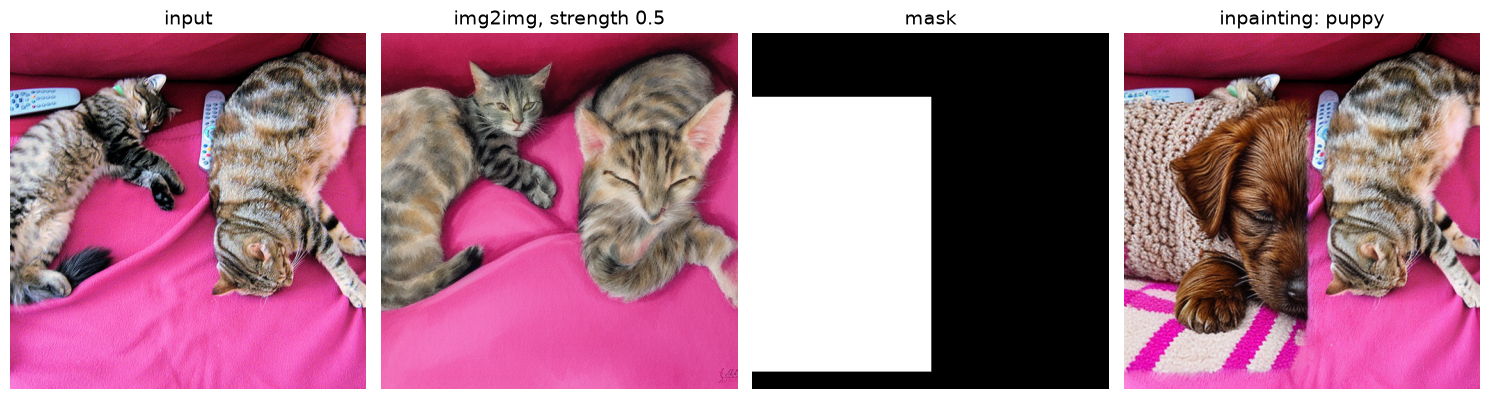

In [9]:
i2i = AutoPipelineForImage2Image.from_pipe(pipe); inp = AutoPipelineForInpainting.from_pipe(pipe)
i2i.set_progress_bar_config(disable=True); inp.set_progress_bar_config(disable=True)
mask = Image.new("L", (res, res), 0); ImageDraw.Draw(mask).rectangle([0, int(res * 0.18), int(res * 0.5), int(res * 0.95)], fill=255)
gen = lambda s: torch.Generator().manual_seed(s)
with Timer() as t1:
    im_i2i = i2i("a watercolor painting of two cats sleeping on a pink sofa", image=photo, strength=0.5, num_inference_steps=2,
                 guidance_scale=0.0, generator=gen(1), output_type="pt").images.float().cpu()
with Timer() as t2:
    im_inp = inp("a small brown puppy sleeping on a pink blanket", image=photo, mask_image=mask, strength=1.0, num_inference_steps=2,
                 guidance_scale=0.0, generator=gen(2), height=res, width=res, output_type="pt").images.float().cpu()
m_t = to_t(mask.convert("RGB"))[:, :1]
outside = (1 - m_t).bool().expand_as(x_ph)
print(f"img2img {t1.s:.1f} s; inpainting {t2.s:.1f} s")
print(f"PSNR outside the mask: img2img {psnr(im_i2i[outside].view(1, -1), x_ph[outside].view(1, -1)):.1f} dB, "
      f"inpainting {psnr(im_inp[outside].view(1, -1), x_ph[outside].view(1, -1)):.1f} dB")
SD_IMAGES += [im_i2i, im_inp]
fig, ax = plt.subplots(1, 4, figsize=(15, 4.2))
for a, im, tt in zip(ax, [x_ph[0], im_i2i[0], m_t[0].repeat(3, 1, 1), im_inp[0]], ["input", "img2img, strength 0.5", "mask", "inpainting: puppy"]):
    a.imshow(im.permute(1, 2, 0)); a.set_title(tt, fontsize=14); a.axis("off")
plt.tight_layout(); plt.show()
SD_VAE = pipe.vae                                                       # пригодится в разделе 18
del i2i, inp, pipe, taesd
import gc; _ = gc.collect()

## 9. Мини-LDM: VAE и текстовый энкодер

### 9.1. Дубликаты в обучающих данных

Перед обучением в данные подмешаны восемь «канареек» — конкретных изображений с обычными подписями, повторённых 1, 10, 50 и 200 раз (по два изображения на каждый уровень). Остальные `n_train` изображений уникальны (30 000 на CPU, 60 000 на GPU). В разделе 12 по этим канарейкам будет измерено, как число повторов влияет на дословное запоминание, как в работе [Carlini et al. (2023)](https://arxiv.org/abs/2301.13188). Добавка составляет 1,7 % выборки на CPU и 0,9 % на GPU и на остальные эксперименты почти не влияет.

In [10]:
CANARY_SPEC = [("large", "red", "circle", "on the left", 1), ("large", "blue", "square", "at the top", 1),
               ("large", "green", "triangle", "on the right", 10), ("large", "yellow", "person", "in the center", 10),
               ("large", "magenta", "circle", "at the bottom", 50), ("large", "cyan", "square", "in the center", 50),
               ("large", "magenta", "triangle", "at the top", 200), ("large", "green", "person", "on the left", 200)]
CANARIES = []
for k, (sz, c, sh, p, dup) in enumerate(CANARY_SPEC):
    rng = random.Random(1000 + k)
    objs, cap, lab = sample_scene(rng, force=dict(double=False, size=sz, color=c, shape=sh, pos=p))
    img = render(objs, rng.uniform(0.05, 0.30))
    CANARIES.append(dict(cap=cap, dup=dup, lab=torch.tensor(lab), X=torch.from_numpy((img[0] * 255).round().astype(np.uint8)),
                         SEG=torch.from_numpy(img[1]), DEP=torch.from_numpy((img[2] * 255).round().astype(np.uint8)),
                         POSE=torch.from_numpy((img[3] * 255).round().astype(np.uint8))))
for key in ("X", "SEG", "DEP", "POSE"):
    TR[key] = torch.cat([TR[key]] + [c[key][None].repeat(c["dup"], *[1] * c[key].dim()) for c in CANARIES])
TR["lab"] = torch.cat([TR["lab"]] + [c["lab"][None].repeat(c["dup"], 1) for c in CANARIES])
TR["caps"] = TR["caps"] + [c["cap"] for c in CANARIES for _ in range(c["dup"])]
N_TR = len(TR["caps"])
print(f"train set: {N_TR} images, of them {N_TR - S['n_train']} canary copies")
for c in CANARIES: print(f"  x{c['dup']:<4d} {c['cap']}  (other train images with this caption: {TR['caps'][:S['n_train']].count(c['cap'])})")

train set: 60522 images, of them 522 canary copies
  x1    a large red circle on the left  (other train images with this caption: 160)
  x1    a large blue square at the top  (other train images with this caption: 146)
  x10   a large green triangle on the right  (other train images with this caption: 145)
  x10   a large yellow person in the center  (other train images with this caption: 161)
  x50   a large magenta circle at the bottom  (other train images with this caption: 159)
  x50   a large cyan square in the center  (other train images with this caption: 153)
  x200  a large magenta triangle at the top  (other train images with this caption: 153)
  x200  a large green person on the left  (other train images with this caption: 144)


### 9.2. VAE: латент 4×8×8

Мини-VAE — тот же класс `AutoencoderKL`, что в Stable Diffusion, только с тремя блоками на 16, 32 и 64 канала. Он уменьшает изображение в 4 раза по стороне (32 → 8) и хранит 4 канала, то есть сжимает 3072 числа в 256, в 12 раз. Потеря: MSE реконструкции и KL-регуляризатор с крошечным весом $10^{-5}$. Как и в LDM, KL здесь нужен не для генерации из $\mathcal N(0, I)$, а только чтобы латенты не «разъезжались» по масштабу. Генерацию делает диффузия. После обучения масштабный множитель подбирается так, чтобы латенты обучающей выборки имели единичную дисперсию: `scaling_factor = 1 / std(z)`. Ровно так получено число 0,18215 у SD.

VAE: 0.65 M params, 4000 steps in 5.4 min; MSE 0.1288 -> 0.0011
encoding the train set: 3.5 s; latent (4, 8, 8), scaling_factor = 0.6676
scaled latents: mean 0.676, std 1.000, per-channel std [0.47, 0.44, 1.49, 0.66]
test reconstruction PSNR 36.80 dB (5th percentile 31.91); checker on reconstructions: {'shape': 0.998, 'color': 1.0, 'all1': 0.997, 'all2': 0.998}


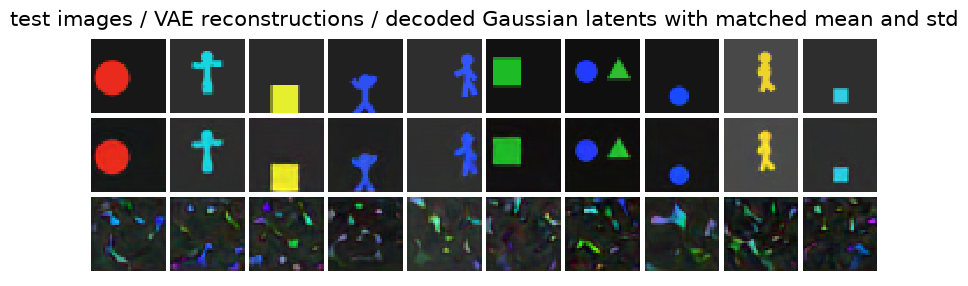

In [11]:
seed_all(0)
vae = AutoencoderKL(in_channels=3, out_channels=3, down_block_types=("DownEncoderBlock2D",) * 3, up_block_types=("UpDecoderBlock2D",) * 3,
                    block_out_channels=(16, 32, 64), latent_channels=4, layers_per_block=1, norm_num_groups=16, sample_size=32,
                    mid_block_add_attention=False).to(DEVICE)
opt = torch.optim.AdamW(vae.parameters(), 1e-3); g = torch.Generator().manual_seed(1); vae_log = []
with Timer() as t:
    for step in range(S["steps_vae"]):
        i = torch.randint(0, N_TR, (S["bs"],), generator=g); x = u8(TR["X"][i]).to(DEVICE) * 2 - 1
        post = vae.encode(x).latent_dist; rec = vae.decode(post.sample()).sample
        mse = F.mse_loss(rec, x); kl = post.kl().mean() / 256
        loss = mse + 1e-5 * kl; opt.zero_grad(); loss.backward(); opt.step()
        for gr in opt.param_groups: gr["lr"] = 1e-3 * (0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * step / S["steps_vae"])))
        vae_log.append((mse.item(), kl.item()))
vae.eval().requires_grad_(False); t_vae = t.s

@torch.no_grad()
def vae_enc(x01, bs=1000): return torch.cat([vae.encode((x01[i:i + bs].to(DEVICE).float() * 2 - 1)).latent_dist.mean.cpu() for i in range(0, len(x01), bs)])
@torch.no_grad()
def vae_dec(z, bs=1000): return torch.cat([((vae.decode(z[i:i + bs].to(DEVICE)).sample.cpu() + 1) / 2).clamp(0, 1) for i in range(0, len(z), bs)])

with Timer() as t_e: Z_RAW = torch.cat([vae_enc(u8(TR["X"][i:i + 5000])) for i in range(0, N_TR, 5000)])
SF = float(1 / Z_RAW.std()); vae.register_to_config(scaling_factor=SF)
Z_TR = Z_RAW * SF; del Z_RAW
rec_te = vae_dec(vae_enc(u8(TE["X"])))
psnr_te = [psnr(rec_te[i:i + 1], u8(TE["X"][i:i + 1])) for i in range(len(rec_te))]
f_rec, p_rec = judge(rec_te)
print(f"VAE: {nparam(vae) / 1e6:.2f} M params, {S['steps_vae']} steps in {t_vae / 60:.1f} min; MSE {np.mean([a for a, _ in vae_log[:50]]):.4f} -> {np.mean([a for a, _ in vae_log[-50:]]):.4f}")
print(f"encoding the train set: {t_e.s:.1f} s; latent {tuple(Z_TR.shape[1:])}, scaling_factor = {SF:.4f}")
print(f"scaled latents: mean {Z_TR.mean():.3f}, std {Z_TR.std():.3f}, per-channel std {[round(v, 2) for v in Z_TR.std((0, 2, 3)).tolist()]}")
print(f"test reconstruction PSNR {np.mean(psnr_te):.2f} dB (5th percentile {np.percentile(psnr_te, 5):.2f}); "
      f"checker on reconstructions: {({k: round(v, 3) for k, v in attr_acc(p_rec, TE['lab']).items() if k in ('shape', 'color', 'all1', 'all2')})}")
z_rand = torch.randn(10, 4, 8, 8) * Z_TR.std((0, 2, 3)).view(1, 4, 1, 1) + Z_TR.mean((0, 2, 3)).view(1, 4, 1, 1)
show(torch.cat([u8(TE["X"][:10]), rec_te[:10], vae_dec(z_rand / SF)]), nrow=10, scale=1.1,
     title="test images / VAE reconstructions / decoded Gaussian latents with matched mean and std")

### 9.3. Текстовый энкодер: замороженный CLIP

Как и в SD 1.x, текстовый энкодер — текстовая башня CLIP ([Radford et al., 2021](https://arxiv.org/abs/2103.00020)), здесь ViT-B/32 (63 млн параметров, ширина 512). Он заморожен, поэтому эмбеддинги всех 816 подписей можно посчитать один раз и хранить. U-Net получает всю последовательность скрытых состояний последнего слоя, а не один вектор. Наши подписи короче 20 токенов, поэтому длина последовательности уменьшена с 77 до 20. Это экономит время cross-attention, а позиционные эмбеддинги первых 20 позиций остаются теми же. Пустая подпись `""` даёт безусловный эмбеддинг для classifier-free guidance.

In [12]:
from transformers import CLIPTextModel
text_enc = CLIPTextModel.from_pretrained("openai/clip-vit-base-patch32").to(DEVICE).eval().requires_grad_(False)
L_TXT = 20
tok20 = CLIPTokenizer.from_pretrained("openai/clip-vit-base-patch32", model_max_length=L_TXT)
_EMB_CACHE = {}
@torch.no_grad()
def encode_text(caps, bs=256):
    new = [c for c in dict.fromkeys(caps) if c not in _EMB_CACHE]
    for i in range(0, len(new), bs):
        ids = tok20(new[i:i + bs], padding="max_length", max_length=L_TXT, truncation=True, return_tensors="pt").input_ids.to(DEVICE)
        h = text_enc(ids).last_hidden_state.cpu()
        for c, e in zip(new[i:i + bs], h): _EMB_CACHE[c] = e
    return torch.stack([_EMB_CACHE[c] for c in caps])

longest = max(set(TR["caps"]), key=lambda c: len(tok20(c, truncation=False).input_ids))
with Timer() as t: _ = encode_text(sorted(set(TR["caps"]) | set(TE["caps"])) + [""])
E_UNCOND = encode_text([""])[0]
print(f"{len(_EMB_CACHE)} captions encoded in {t.s:.1f} s -> {L_TXT}x{text_enc.config.hidden_size} each")
print(f"longest caption: {len(tok20(longest, truncation=False).input_ids)} tokens: {longest!r}")
e = encode_text(["a large red circle on the left", "a large blue circle on the left", "a large red square on the left",
                 "a large red circle on the right", "a red circle on the left and a blue square on the right",
                 "a blue square on the left and a red circle on the right"])
eos = lambda caps: [len(tok20(c).input_ids) - 1 for c in caps]           # позиция конечного токена
pooled = F.normalize(torch.stack([e[i, j] for i, j in enumerate(eos(["a large red circle on the left", "a large blue circle on the left",
         "a large red square on the left", "a large red circle on the right", "a red circle on the left and a blue square on the right",
         "a blue square on the left and a red circle on the right"]))]), dim=-1)
print("cosine of final-token states to 'a large red circle on the left':",
      dict(zip(["blue circle", "red square", "circle right", "pair", "pair swapped"], [round(v, 3) for v in (pooled[1:] @ pooled[0]).tolist()])))
print(f"cosine 'pair' vs 'pair swapped': {float(pooled[4] @ pooled[5]):.3f}")

817 captions encoded in 0.6 s -> 20x512 each
longest caption: 17 tokens: 'a cyan square on the left and a cyan circle on the right'
cosine of final-token states to 'a large red circle on the left': {'blue circle': 0.811, 'red square': 0.567, 'circle right': 0.995, 'pair': 0.833, 'pair swapped': 0.795}
cosine 'pair' vs 'pair swapped': 0.971


## 10. Мини-LDM: U-Net с cross-attention, планировщик и CFG

### 10.1. Обучение

U-Net — класс `UNet2DConditionModel`, как в SD, с двумя уровнями (8×8 и 4×4), блоками `CrossAttnDownBlock2D` / `CrossAttnUpBlock2D` и cross-attention к 20 векторам CLIP размерности 512. Расписание шума взято из конфигурации SD: 1000 шагов, `scaled_linear` от 0,00085 до 0,012, предсказание шума $\epsilon$. В 10 % примеров подпись заменяется пустой, чтобы та же сеть умела и безусловное предсказание для CFG ([Ho & Salimans, 2022](https://arxiv.org/abs/2207.12598)). Для генерации используются веса EMA.

In [13]:
NOISE_CFG = dict(num_train_timesteps=1000, beta_schedule="scaled_linear", beta_start=0.00085, beta_end=0.012,
                 prediction_type="epsilon", clip_sample=False, set_alpha_to_one=False, steps_offset=1, timestep_spacing="leading")
train_sched = DDPMScheduler(**{k: v for k, v in NOISE_CFG.items() if k not in ("set_alpha_to_one",)})
def make_unet(in_ch=4):
    return UNet2DConditionModel(sample_size=8, in_channels=in_ch, out_channels=4, block_out_channels=S["ch"],
        down_block_types=("CrossAttnDownBlock2D",) * 2, up_block_types=("CrossAttnUpBlock2D",) * 2, layers_per_block=1,
        cross_attention_dim=512, attention_head_dim=8, norm_num_groups=16).to(DEVICE)

class EMA:
    def __init__(self, model, decay=0.999):
        self.m = copy.deepcopy(model).eval().requires_grad_(False); self.d = decay
    @torch.no_grad()
    def update(self, model):
        for pe, p in zip(self.m.parameters(), model.parameters()): pe.lerp_(p, 1 - self.d)

def diffusion_loss(unet_fn, z0, emb, t=None):
    noise = torch.randn_like(z0)
    t = torch.randint(0, 1000, (len(z0),), device=z0.device) if t is None else t
    zt = train_sched.add_noise(z0, noise, t)
    return F.mse_loss(unet_fn(zt, t, emb), noise)

TR_EMB_IDX = None
def train_batches(bs, steps, seed, p_drop=0.1, idx_pool=None):
    g = torch.Generator().manual_seed(seed); pool = torch.arange(N_TR) if idx_pool is None else idx_pool
    for _ in range(steps):
        i = pool[torch.randint(0, len(pool), (bs,), generator=g)]
        caps = [TR["caps"][j] if random.random() > p_drop else "" for j in i.tolist()]
        yield i, Z_TR[i].to(DEVICE), encode_text(caps).to(DEVICE)

seed_all(0)
unet = make_unet(); ema = EMA(unet)
opt = torch.optim.AdamW(unet.parameters(), 5e-4, weight_decay=0.0); unet_log = []
with Timer() as t:
    for step, (i, z0, emb) in enumerate(train_batches(S["bs"], S["steps_unet"], seed=2)):
        loss = diffusion_loss(lambda zt, tt, e: unet(zt, tt, encoder_hidden_states=e).sample, z0, emb)
        opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(unet.parameters(), 1.0); opt.step(); ema.update(unet)
        for gr in opt.param_groups: gr["lr"] = 5e-4 * min(1, (step + 1) / 200)
        unet_log.append(loss.item())
t_unet = t.s; unet = ema.m
print(f"U-Net: {nparam(unet) / 1e6:.2f} M params, {S['steps_unet']} steps in {t_unet / 60:.1f} min ({t_unet / S['steps_unet']:.2f} s/step)")
print(f"loss: first 100 steps {np.mean(unet_log[:100]):.4f}, last 200 steps {np.mean(unet_log[-200:]):.4f}")

U-Net: 4.82 M params, 10000 steps in 31.8 min (0.19 s/step)
loss: first 100 steps 0.4833, last 200 steps 0.0271


### 10.2. Генерация с CFG и замена планировщика

Сэмплер ниже — это тот же цикл, что в разделе 8.4, плюс classifier-free guidance: сеть вызывается для условного и безусловного эмбеддинга в одном батче, и предсказания смешиваются как $\hat\epsilon = \hat\epsilon_\varnothing + w(\hat\epsilon_c - \hat\epsilon_\varnothing)$. При $w = 1$ guidance выключен. Функция принимает любую `model_fn`, поэтому в следующих разделах та же функция работает с LoRA, ControlNet и IP-Adapter. Планировщик меняется одной строкой, без переобучения: DDIM, Euler и DPM-Solver++ используют одну и ту же сеть.

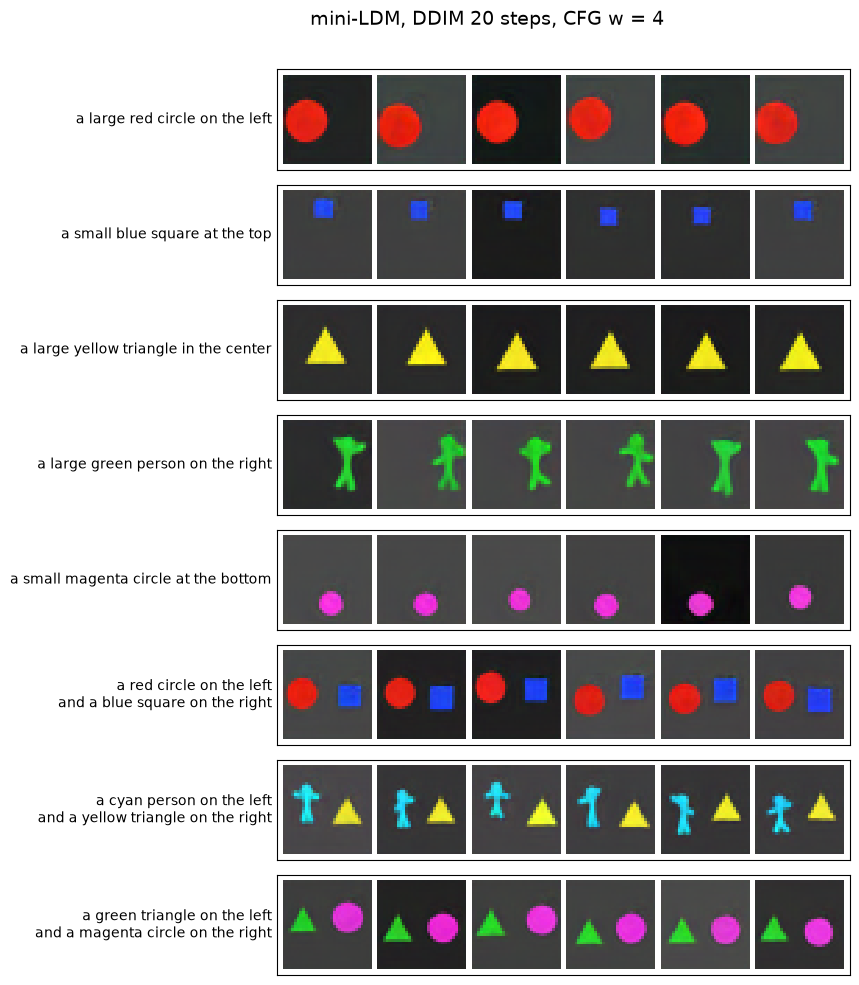

In [14]:
SCHEDULERS = {"ddim": lambda: DDIMScheduler(**NOISE_CFG),
              "euler": lambda: EulerDiscreteScheduler(**{k: v for k, v in NOISE_CFG.items() if k not in ("clip_sample", "set_alpha_to_one")}),
              "dpm++": lambda: DPMSolverMultistepScheduler(**{k: v for k, v in NOISE_CFG.items() if k not in ("clip_sample", "set_alpha_to_one")})}
base_fn = lambda zt, t, e, **kw: unet(zt, t, encoder_hidden_states=e).sample

@torch.no_grad()
def generate(caps, w=4.0, steps=20, sched="ddim", seed=0, model_fn=None, emb=None, bs=500, decode=True, z_init=None, blend=None):
    """caps: подписи; emb: готовые эмбеддинги (N×L×512) вместо подписей; blend: (z_known, mask) для inpainting смешиванием."""
    model_fn = model_fn or base_fn; out = []
    emb = encode_text(caps) if emb is None else emb
    g = torch.Generator().manual_seed(seed)
    zs_all = torch.randn(len(emb), 4, 8, 8, generator=g) if z_init is None else z_init
    for b in range(0, len(emb), bs):
        sch = SCHEDULERS[sched](); sch.set_timesteps(steps)
        e = emb[b:b + bs].to(DEVICE); n = len(e); z = zs_all[b:b + bs].to(DEVICE) * sch.init_noise_sigma
        idx = slice(b, b + n)
        for t_ in sch.timesteps:
            zin = sch.scale_model_input(z, t_); tt = t_.repeat(n if w == 1 else 2 * n).to(DEVICE)
            if w == 1: eps = model_fn(zin, tt, e, idx=idx, cond=True)
            else:
                eps2 = model_fn(torch.cat([zin, zin]), tt, torch.cat([E_UNCOND.to(DEVICE).expand(n, -1, -1), e]), idx=idx, cond=None)
                eu, ec = eps2.chunk(2); eps = eu + w * (ec - eu)
            z = sch.step(eps, t_, z).prev_sample
            if blend is not None:                                         # inpainting смешиванием: известная часть = зашумлённый оригинал
                zk, m = blend[0][idx].to(DEVICE), blend[1][idx].to(DEVICE)
                nxt = sch.timesteps[sch.timesteps < t_]
                zk_t = train_sched.add_noise(zk, torch.randn_like(zk), nxt[:1].repeat(n)) if len(nxt) else zk
                z = m * z + (1 - m) * zk_t
        out.append(vae_dec(z / SF) if decode else z.cpu())
    return torch.cat(out)

DEMO = ["a large red circle on the left", "a small blue square at the top", "a large yellow triangle in the center",
        "a large green person on the right", "a small magenta circle at the bottom",
        "a red circle on the left and a blue square on the right", "a cyan person on the left and a yellow triangle on the right",
        "a green triangle on the left and a magenta circle on the right"]
grid = generate([c for c in DEMO for _ in range(6)], w=4, steps=20, seed=1)
def parse_cap(c):
    w_ = c.split()
    if " and " in c: return dict(double=True, color=w_[1], shape=w_[2], color2=w_[8], shape2=w_[9])
    return dict(double=False, size=w_[1], color=w_[2], shape=w_[3], pos=" ".join(w_[4:]))
cap_lab = lambda caps: torch.tensor([sample_scene(random.Random(0), shapes=SHAPES, force=parse_cap(c))[2] for c in caps])
fig, ax = plt.subplots(len(DEMO), 1, figsize=(9, 1.25 * len(DEMO)))
for r_, c in enumerate(DEMO):
    ax[r_].imshow(torchvision.utils.make_grid(grid[6 * r_:6 * r_ + 6], nrow=6, padding=2, pad_value=1).permute(1, 2, 0), interpolation="nearest")
    ax[r_].set_xticks([]); ax[r_].set_yticks([]); ax[r_].set_ylabel(c.replace(" and", "\nand"), rotation=0, ha="right", va="center", fontsize=10)
plt.suptitle("mini-LDM, DDIM 20 steps, CFG w = 4", fontsize=14); plt.tight_layout(rect=(0, 0, 1, 0.97)); plt.show()

### 10.3. Мини-модель внутри стандартного StableDiffusionPipeline

Раз компоненты мини-модели — те же классы, их можно передать в конструктор `StableDiffusionPipeline` и вызвать обычный `pipe(prompt)`. Это лучшая проверка, что мы поняли устройство пайплайна: ручной цикл и библиотечный должны дать одно и то же из одного шума. Здесь же сравниваются планировщики на 300 подписях тестовой выборки по точности атрибутов.

In [15]:
pipe_mini = StableDiffusionPipeline(vae=vae, text_encoder=text_enc, tokenizer=tok20, unet=unet, scheduler=SCHEDULERS["ddim"](),
                                    safety_checker=None, feature_extractor=None, requires_safety_checker=False, image_encoder=None)
pipe_mini.set_progress_bar_config(disable=True)
z0 = torch.randn(2, 4, 8, 8, generator=torch.Generator().manual_seed(5))
img_lib = pipe_mini(["a large red circle on the left", "a small blue square at the top"], height=32, width=32, num_inference_steps=20,
                    guidance_scale=4.0, latents=z0.to(DEVICE), output_type="pt").images.cpu()
img_own = generate(["a large red circle on the left", "a small blue square at the top"], w=4, steps=20, z_init=z0)
print(f"StableDiffusionPipeline vs own loop: max |difference| = {(img_lib - img_own).abs().max():.2e}")
caps_te = TE["caps"][:300]; lab_te = TE["lab"][:300]
for name, st in (("ddim", 20), ("ddim", 50), ("euler", 20), ("dpm++", 10)):
    with Timer() as t: x = generate(caps_te, w=4, steps=st, sched=name, seed=3)
    a = attr_acc(judge(x)[1], lab_te)
    print(f"{name:6s} {st:2d} steps: {t.s:5.1f} s | single object all-correct {a['all1']:.3f} | two objects all-correct {a['all2']:.3f}")

StableDiffusionPipeline vs own loop: max |difference| = 1.11e-03
ddim   20 steps:   1.7 s | single object all-correct 1.000 | two objects all-correct 1.000
ddim   50 steps:   3.4 s | single object all-correct 1.000 | two objects all-correct 1.000
euler  20 steps:   1.3 s | single object all-correct 1.000 | two objects all-correct 1.000
dpm++  10 steps:   0.7 s | single object all-correct 1.000 | two objects all-correct 1.000


## 11. Оценка: FID/KID, precision/recall, разнообразие, CLIP score

### 11.1. Реализации метрик

Все метрики распределений считаются в 256-мерных признаках оценщика атрибутов (раздел 7.4).

- FD — формула FID ([Heusel et al., 2017](https://arxiv.org/abs/1706.08500)) в наших признаках.
- KID — несмещённая оценка квадрата MMD с полиномиальным ядром $k(x, y) = (x^\top y / d + 1)^3$, усреднённая по 50 случайным подвыборкам. Перед KID признаки делятся на одно число — среднеквадратичную величину координаты эталонных признаков, чтобы $x^\top y / d$ было порядка единицы, как у признаков Inception ([Bińkowski et al., 2018](https://arxiv.org/abs/1801.01401)).
- Precision и recall на основе $k$-NN шаров, $k = 3$ ([Kynkäänniemi et al., 2019](https://arxiv.org/abs/1904.06991)); density и coverage, $k = 5$ ([Naeem et al., 2020](https://arxiv.org/abs/2002.09797)).
- Vendi score — экспонента энтропии собственных чисел матрицы косинусных сходств, «эффективное число различных объектов» в выборке ([Friedman & Dieng, 2023](https://arxiv.org/abs/2210.02410)).
- Разнообразие внутри подписи — среднее попарное расстояние признаков между изображениями одной подписи, делённое на то же для настоящих изображений с той же подписью. Настоящие изображения для любой подписи можно нарисовать заново, это преимущество синтетического мира.
- Соблюдение условия — доли верных атрибутов по оценщику; для двух фигур засчитываются только полностью верные пары (обе формы и оба цвета на своих местах).

In [16]:
def frechet(fa, fb):
    mu1, mu2 = fa.mean(0), fb.mean(0); s1, s2 = np.cov(fa, rowvar=False), np.cov(fb, rowvar=False)
    covmean = linalg.sqrtm(s1 @ s2)
    if isinstance(covmean, tuple): covmean = covmean[0]
    return float(((mu1 - mu2) ** 2).sum() + np.trace(s1 + s2 - 2 * covmean.real))

def kid(fa, fb, n_sub=50, m=None, seed=0):
    rng = np.random.default_rng(seed); d = fa.shape[1]; m = m or min(len(fa), len(fb), 1000); vals = []
    sc = np.sqrt((fb ** 2).sum(1).mean() / d); fa, fb = fa / sc, fb / sc          # масштаб признаков ~1 на координату
    for _ in range(n_sub):
        x = fa[rng.choice(len(fa), m, replace=False)]; y = fb[rng.choice(len(fb), m, replace=False)]
        kxx, kyy, kxy = (x @ x.T / d + 1) ** 3, (y @ y.T / d + 1) ** 3, (x @ y.T / d + 1) ** 3
        vals.append((kxx.sum() - np.trace(kxx)) / (m * (m - 1)) + (kyy.sum() - np.trace(kyy)) / (m * (m - 1)) - 2 * kxy.mean())
    return float(np.mean(vals)), float(np.std(vals))

def prdc(real, fake, k_pr=3, k_dc=5):
    r, f = torch.from_numpy(real).float(), torch.from_numpy(fake).float()
    drr, dff, drf = torch.cdist(r, r), torch.cdist(f, f), torch.cdist(r, f)
    rad_r = lambda k: drr.kthvalue(k + 1, dim=1).values; rad_f = dff.kthvalue(k_pr + 1, dim=1).values
    precision = (drf <= rad_r(k_pr)[:, None]).any(0).float().mean().item()
    recall = (drf <= rad_f[None, :]).any(1).float().mean().item()
    inside = drf <= rad_r(k_dc)[:, None]
    density = inside.sum().item() / (k_dc * len(f)); coverage = inside.any(1).float().mean().item()
    return dict(precision=precision, recall=recall, density=density, coverage=coverage)

def vendi(feat):
    x = F.normalize(torch.from_numpy(feat).float(), dim=1); lam = torch.linalg.eigvalsh(x @ x.T / len(x)).clamp(min=0)
    lam = lam[lam > 1e-12]; return float(torch.exp(-(lam * lam.log()).sum()))

def real_like(caps, seed):
    """Настоящие изображения ShapeWorld с заданными подписями (новая случайная сцена на каждую)."""
    rng = random.Random(seed); xs = []
    for c in caps:
        objs, _, _ = sample_scene(rng, shapes=SHAPES, force=parse_cap(c)); xs.append(render(objs, rng.uniform(0.05, 0.30))[0])
    return torch.from_numpy(np.stack(xs))

def within_caption_div(feat, groups):
    vals = [torch.pdist(torch.from_numpy(feat[g])).mean().item() for g in groups]; return float(np.mean(vals))

DIV_CAPS = sorted(set(TE["caps"]))[:: max(1, len(set(TE["caps"])) // 20)][:20]
DIV_GROUPS = [list(range(10 * i, 10 * i + 10)) for i in range(len(DIV_CAPS))]
F_DIV_REAL = judge(real_like([c for c in DIV_CAPS for _ in range(10)], seed=11))[0]
DIV_REAL = within_caption_div(F_DIV_REAL, DIV_GROUPS)
N_EV = S["n_eval"]; EV_CAPS, EV_LAB = TE["caps"][:N_EV], TE["lab"][:N_EV]
F_REF = F_TE[N_EV:]                                                        # эталон: остальные тестовые изображения
assert len(F_REF) >= N_EV // 2 and len(F_REF) >= 1000, f"эталон для метрик слишком мал: {len(F_REF)} изображений"
print(f"real reference: {len(F_REF)} images; evaluation captions: {N_EV}; within-caption diversity of real images {DIV_REAL:.3f}")

def full_eval(x, caps=EV_CAPS, lab=EV_LAB, div_x=None, clip=True, clip_n=300):
    f, p = judge(x); a = attr_acc(p, lab)
    r = dict(FD=frechet(f, F_REF), KID=kid(f, F_REF)[0] * 1e3, **prdc(F_REF[:len(f)], f), vendi=vendi(f),
             acc1=a.get("all1", float("nan")), acc2=a.get("all2", float("nan")))
    if div_x is not None: r["div"] = within_caption_div(judge(div_x)[0], DIV_GROUPS) / DIV_REAL
    if clip: r["clip"] = clip_score(clip_img_emb(x[:clip_n]), clip_txt_emb(caps[:clip_n])).mean().item()
    return r

def fmt(r): return "  ".join(f"{k}={v:.3f}" if abs(v) < 100 else f"{k}={v:.1f}" for k, v in r.items())
x_real = u8(TE["X"][:N_EV])
R_REAL = full_eval(x_real, div_x=real_like([c for c in DIV_CAPS for _ in range(10)], seed=12))
print("real test images:", fmt(R_REAL))

real reference: 2000 images; evaluation captions: 2000; within-caption diversity of real images 82.468
real test images: FD=299.5  KID=-0.168  precision=0.952  recall=0.950  density=1.015  coverage=0.971  vendi=7.236  acc1=0.998  acc2=0.999  div=1.043  clip=28.885


### 11.2. Смещение FID и несмещённость KID

Сравним две независимые выборки настоящих изображений. Истинное расстояние между распределениями равно нулю, но оценка FD положительна и тем больше, чем меньше выборка. Смещение порядка $1/n$ — известное свойство FID ([Chong & Forsyth, 2020](https://arxiv.org/abs/1911.07023)). Поэтому FID разных работ сравнимы только при одинаковом $n$ и одинаковой предобработке. KID несмещён: его среднее около нуля при любом $n$, меняется только разброс.

n=   50: FD 11429.38 ± 1338.02 | KID×1e3 -10.363 ± 55.721
n=  100: FD  5736.94 ± 857.99 | KID×1e3  -7.296 ± 27.318
n=  200: FD  2631.85 ± 208.30 | KID×1e3  -8.581 ± 10.455
n=  400: FD  1407.07 ± 117.01 | KID×1e3  -2.413 ± 6.812
n= 1000: FD   548.44 ±  53.99 | KID×1e3  -1.053 ± 1.469
n= 2000: FD   311.12 ±  18.10 | KID×1e3   0.368 ± 0.699


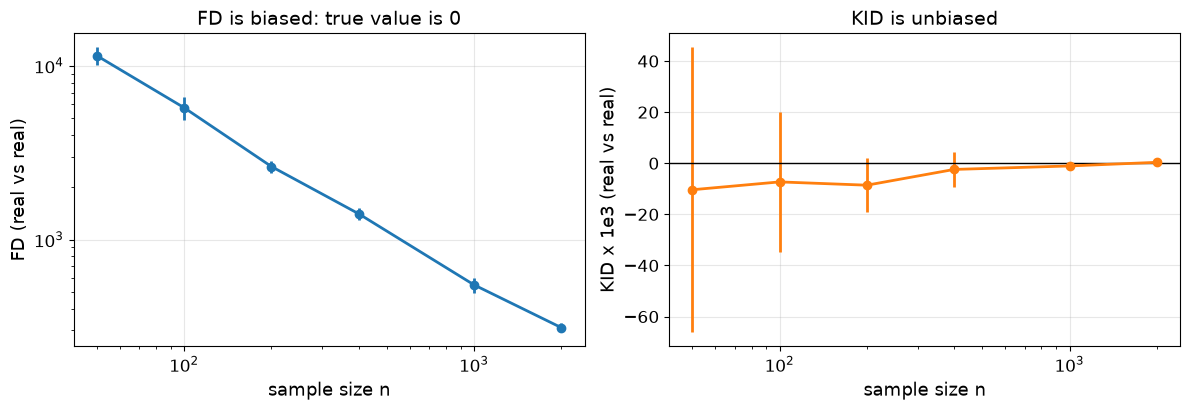

In [17]:
F_REAL2 = judge(u8(make_dataset(4000, seed=7)["X"]))[0]
bias = []
for n in (50, 100, 200, 400, 1000, 2000):
    fds, kids = [], []
    for rep in range(5):
        rng = np.random.default_rng(rep); a_ = F_REAL2[rng.choice(len(F_REAL2), n, replace=False)]; b_ = F_TE[rng.choice(len(F_TE), n, replace=False)]
        fds.append(frechet(a_, b_)); kids.append(kid(a_, b_, n_sub=20, m=n, seed=rep)[0] * 1e3)
    bias.append((n, np.mean(fds), np.std(fds), np.mean(kids), np.std(kids)))
    print(f"n={n:5d}: FD {np.mean(fds):8.2f} ± {np.std(fds):6.2f} | KID×1e3 {np.mean(kids):7.3f} ± {np.std(kids):.3f}")
b = np.array(bias)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].errorbar(b[:, 0], b[:, 1], b[:, 2], marker="o", lw=2); ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_xlabel("sample size n", fontsize=13); ax[0].set_ylabel("FD (real vs real)", fontsize=13); ax[0].set_title("FD is biased: true value is 0", fontsize=14)
ax[1].errorbar(b[:, 0], b[:, 3], b[:, 4], marker="o", lw=2, color="C1"); ax[1].axhline(0, color="k", lw=1); ax[1].set_xscale("log")
ax[1].set_xlabel("sample size n", fontsize=13); ax[1].set_ylabel("KID x 1e3 (real vs real)", fontsize=13); ax[1].set_title("KID is unbiased", fontsize=14)
for a in ax: a.tick_params(labelsize=12); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### 11.3. Компромисс CFG: качество, разнообразие, соответствие подписи

Одна и та же модель генерирует 600 изображений по тестовым подписям при разных $w$. Ожидается классическая картина ([Ho & Salimans, 2022](https://arxiv.org/abs/2207.12598)): с ростом $w$ соответствие подписи и precision растут, recall и разнообразие падают, а FID сначала падает, потом растёт.

w= 1.0: FD=528.9  KID=18.444  precision=0.966  recall=0.925  density=1.050  coverage=0.965  vendi=7.202  acc1=0.988  acc2=0.987  div=0.959  clip=27.911
w= 2.0: FD=381.5  KID=2.517  precision=0.966  recall=0.940  density=1.011  coverage=0.966  vendi=7.293  acc1=0.999  acc2=1.000  div=0.893  clip=28.219
w= 4.0: FD=722.9  KID=24.726  precision=0.945  recall=0.920  density=0.938  coverage=0.952  vendi=7.329  acc1=0.999  acc2=0.999  div=0.865  clip=28.422
w= 7.0: FD=978.6  KID=36.792  precision=0.928  recall=0.877  density=0.897  coverage=0.933  vendi=7.326  acc1=0.999  acc2=0.999  div=0.867  clip=28.519
w=12.0: FD=1308.6  KID=47.572  precision=0.886  recall=0.830  density=0.850  coverage=0.893  vendi=7.286  acc1=0.995  acc2=0.977  div=0.894  clip=28.532
sweep: 1.2 min


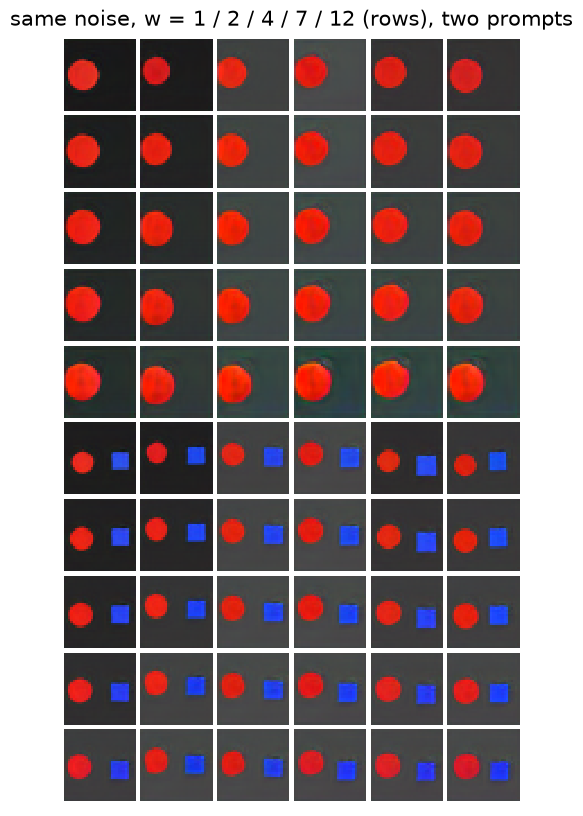

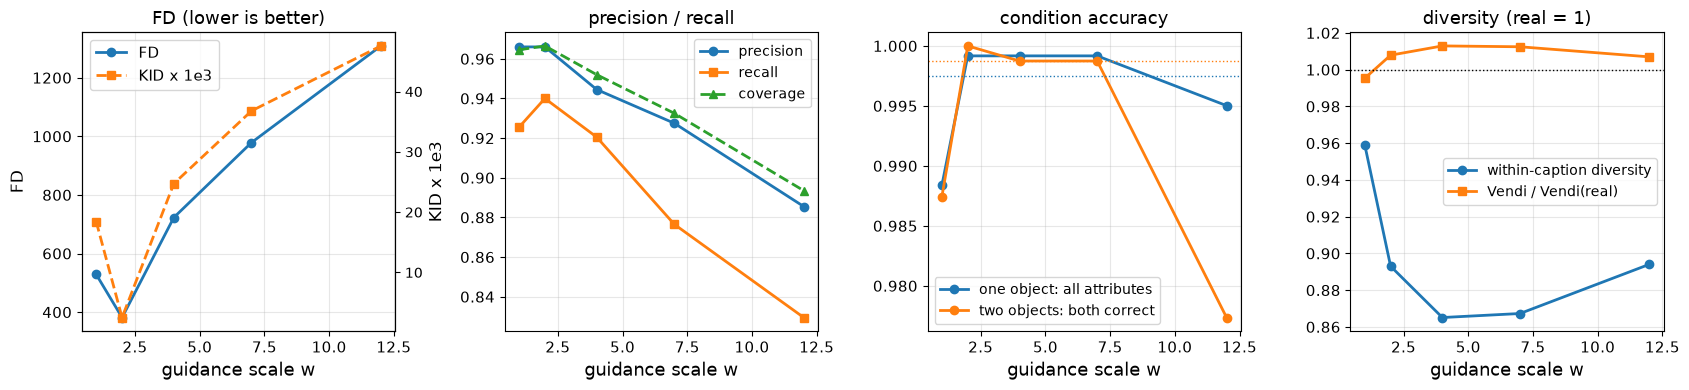

In [18]:
CFG_W = [1.0, 2.0, 4.0, 7.0, 12.0]; cfg_res = {}
div_caps = [c for c in DIV_CAPS for _ in range(10)]
with Timer() as t:
    for w in CFG_W:
        x = generate(EV_CAPS, w=w, steps=20, seed=21); xd = generate(div_caps, w=w, steps=20, seed=22)
        cfg_res[w] = full_eval(x, div_x=xd)
        if w == 4.0: X_BASE4 = x
        print(f"w={w:4.1f}: {fmt(cfg_res[w])}")
print(f"sweep: {t.s / 60:.1f} min")
show(torch.cat([generate(DEMO[i:i + 1] * 6, w=w, steps=20, seed=5) for i in (0, 5) for w in CFG_W]), nrow=6, scale=1.1,
     title="same noise, w = 1 / 2 / 4 / 7 / 12 (rows), two prompts")
keys = [("FD", "FD (lower is better)"), ("precision", "precision / recall"), ("acc1", "condition accuracy"), ("div", "diversity (real = 1)")]
fig, ax = plt.subplots(1, 4, figsize=(17, 4.0))
ax[0].plot(CFG_W, [cfg_res[w]["FD"] for w in CFG_W], "o-", lw=2, label="FD"); a2 = ax[0].twinx()
a2.plot(CFG_W, [cfg_res[w]["KID"] for w in CFG_W], "s--", color="C1", lw=2, label="KID x 1e3"); ax[0].set_ylabel("FD", fontsize=12); a2.set_ylabel("KID x 1e3", fontsize=12)
ax[0].legend(ax[0].get_lines() + a2.get_lines(), ["FD", "KID x 1e3"], fontsize=11, loc="upper left")
for k, st in (("precision", "o-"), ("recall", "s-"), ("coverage", "^--")): ax[1].plot(CFG_W, [cfg_res[w][k] for w in CFG_W], st, lw=2, label=k)
for k, lb in (("acc1", "one object: all attributes"), ("acc2", "two objects: both correct")): ax[2].plot(CFG_W, [cfg_res[w][k] for w in CFG_W], "o-", lw=2, label=lb)
ax[2].axhline(R_REAL["acc1"], color="C0", ls=":", lw=1); ax[2].axhline(R_REAL["acc2"], color="C1", ls=":", lw=1)
ax[3].plot(CFG_W, [cfg_res[w]["div"] for w in CFG_W], "o-", lw=2, label="within-caption diversity")
ax[3].plot(CFG_W, [cfg_res[w]["vendi"] / R_REAL["vendi"] for w in CFG_W], "s-", lw=2, label="Vendi / Vendi(real)"); ax[3].axhline(1, color="k", lw=1, ls=":")
for a, (k, tt) in zip(ax, keys):
    a.set_xlabel("guidance scale w", fontsize=13); a.set_title(tt, fontsize=13); a.grid(alpha=0.3); a.tick_params(labelsize=11)
for a in ax[1:]: a.legend(fontsize=10)
plt.tight_layout(); plt.show()

### 11.4. Что видит и чего не видит CLIP score

CLIP score удобен, но он проверяет «похожесть» подписи и изображения в целом. Проверим его на настоящих тестовых изображениях. Для каждого изображения верная подпись сравнивается с испорченной: заменён цвет, форма, положение, размер, или в паре фигур переставлены цвета (проверка связывания атрибутов). Если бы CLIP score надёжно проверял условие, верная подпись почти всегда получала бы больший балл. Доля таких случаев 0,5 означает уровень монетки.

In [19]:
def perturb(c, kind, rng):
    p = parse_cap(c)
    if kind == "color": p["color"] = rng.choice([x for x in CNAMES if x != p["color"]])
    elif kind == "shape": p["shape"] = rng.choice([x for x in BASE_SHAPES if x != p["shape"]])
    elif kind == "position": p["pos"] = rng.choice([x for x in PNAMES if x != p["pos"]])
    elif kind == "size": p["size"] = "large" if p["size"] == "small" else "small"
    elif kind == "binding":
        if p["color"] == p["color2"]: return None
        p["color"], p["color2"] = p["color2"], p["color"]
    if p.get("double"): return f"a {p['color']} {p['shape']} on the left and a {p['color2']} {p['shape2']} on the right"
    return f"a {p['size']} {p['color']} {p['shape']} {p['pos']}"

rng = random.Random(0); x_cl = u8(TE["X"][:N_EV]); ie = clip_img_emb(x_cl); te_ok = clip_txt_emb(EV_CAPS)
s_ok = clip_score(ie, te_ok); clip_sens = {}
for kind in ("color", "shape", "size", "position", "binding"):
    idx = [i for i, c in enumerate(EV_CAPS) if (" and " in c) == (kind == "binding")]
    bad = [perturb(EV_CAPS[i], kind, rng) for i in idx]; keep = [j for j, b_ in enumerate(bad) if b_ is not None]
    idx = [idx[j] for j in keep]; bad = [bad[j] for j in keep]
    s_bad = clip_score(ie[idx], clip_txt_emb(bad))
    clip_sens[kind] = (s_ok[idx] > s_bad).float().mean().item()
    print(f"{kind:9s}: correct caption wins in {clip_sens[kind]:.3f} of {len(idx)} images; "
          f"mean score {s_ok[idx].mean():.2f} vs perturbed {s_bad.mean():.2f}")

color    : correct caption wins in 0.972 of 1205 images; mean score 27.56 vs perturbed 24.83
shape    : correct caption wins in 0.862 of 1205 images; mean score 27.56 vs perturbed 25.65
size     : correct caption wins in 0.540 of 1205 images; mean score 27.56 vs perturbed 27.46
position : correct caption wins in 0.499 of 1205 images; mean score 27.56 vs perturbed 27.54
binding  : correct caption wins in 0.511 of 657 images; mean score 31.17 vs perturbed 31.19


## 12. Memorization: как дубликаты превращаются в копии

Для каждой канарейки из раздела 9.1 сгенерируем 50 изображений по её подписи и измерим попиксельное расстояние (RMS в $[0, 1]$) до самой канарейки $d_{\text{can}}$ и до ближайшего из десятков других обучающих изображений с той же подписью $d_{\text{oth}}$. Абсолютный порог здесь не годится: в ShapeWorld два разных настоящих изображения с одной подписью бывают очень близки (RMS 0,03–0,10), и «близко к какому-то обучающему» ничего не говорит о запоминании. Поэтому критерий относительный: генерация считается копией канарейки, если $d_{\text{can}} < 0{,}5\, d_{\text{oth}}$, то есть она вдвое ближе к конкретному изображению, чем к любому другому примеру того же содержания. Так же устроен критерий извлечения в [Carlini et al. (2023)](https://arxiv.org/abs/2301.13188): расстояние до обучающего изображения нормируется на расстояния до его соседей. В [Somepalli et al. (2023)](https://arxiv.org/abs/2212.03860) сходство измерялось признаками детектора копий.

Контроль — та же процедура для 8 подписей без канареек: «псевдоканарейкой» объявляется одно случайное обучающее изображение с этой подписью, встречающееся в данных один раз, как и все остальные.

10 s
x1    copy rate 0.00 | median RMS to canary 0.095, to nearest other train image 0.044 (real-real nearest 0.039) | a large red circle on the left
x1    copy rate 0.00 | median RMS to canary 0.199, to nearest other train image 0.035 (real-real nearest 0.041) | a large blue square at the top
x10   copy rate 0.00 | median RMS to canary 0.089, to nearest other train image 0.030 (real-real nearest 0.031) | a large green triangle on the right
x10   copy rate 0.00 | median RMS to canary 0.141, to nearest other train image 0.096 (real-real nearest 0.096) | a large yellow person in the center
x50   copy rate 0.00 | median RMS to canary 0.177, to nearest other train image 0.048 (real-real nearest 0.047) | a large magenta circle at the bottom
x50   copy rate 0.00 | median RMS to canary 0.153, to nearest other train image 0.043 (real-real nearest 0.043) | a large cyan square in the center
x200  copy rate 0.00 | median RMS to canary 0.138, to nearest other train image 0.037 (real-real nearest 0

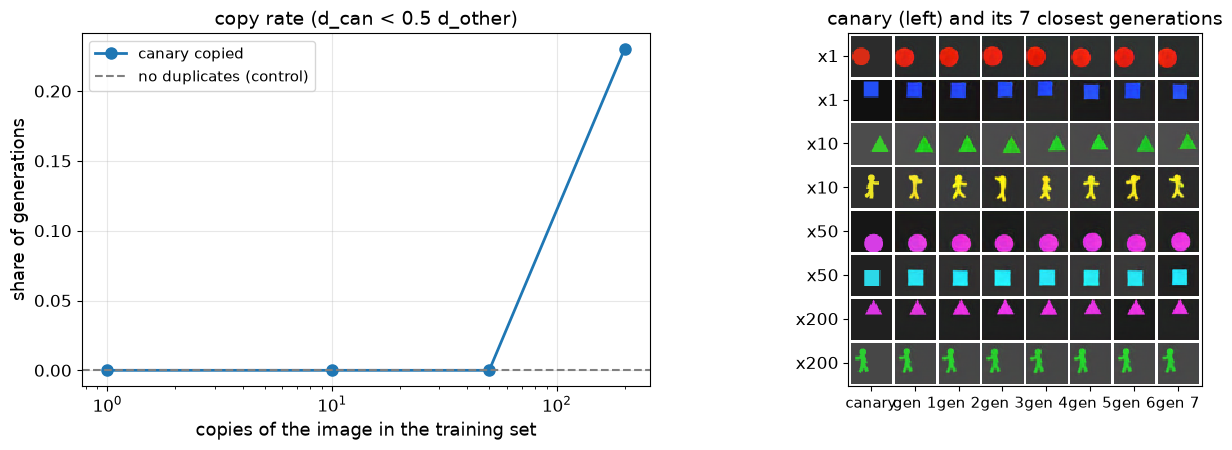

In [20]:
TAU = 0.05                                                                   # абсолютный порог RMS: понадобится в разделах 13 и 15
TAU_REL = 0.5                                                                # копия: вдвое ближе к канарейке, чем к любому другому примеру
rms = lambda a, b: (a[:, None] - b[None]).pow(2).flatten(2).mean(-1).sqrt()      # N×M матрица RMS-расстояний
X_TR_UNIQUE = TR["X"][:S["n_train"]]; caps_unique = TR["caps"][:S["n_train"]]
memo = []; memo_imgs = []
with Timer() as t:
    for k, c in enumerate(CANARIES):
        x = generate([c["cap"]] * 50, w=4, steps=20, seed=300 + k)
        d_can = rms(x, u8(c["X"])[None])[:, 0]
        others = u8(X_TR_UNIQUE[[i for i, cc in enumerate(caps_unique) if cc == c["cap"]]])
        d_oth = rms(x, others).min(1).values
        d_real = rms(others, others).fill_diagonal_(9).min(1).values           # насколько близки друг к другу настоящие
        memo.append(dict(dup=c["dup"], cap=c["cap"], copy=(d_can < TAU_REL * d_oth).float().mean().item(), d_can=d_can.median().item(),
                         d_oth=d_oth.median().item(), d_real=d_real.median().item()))
        memo_imgs.append(torch.cat([u8(c["X"])[None], x[d_can.argsort()[:7]]]))
    ctrl_caps = [c for c in sorted(set(caps_unique)) if " and " not in c and c not in {cc["cap"] for cc in CANARIES}][::29][:8]
    ctrl_copy = []
    for k, c in enumerate(ctrl_caps):
        x = generate([c] * 50, w=4, steps=20, seed=400 + k)
        same = u8(X_TR_UNIQUE[[i for i, cc in enumerate(caps_unique) if cc == c]])
        j = random.Random(k).randrange(len(same)); d_p = rms(x, same[j:j + 1])[:, 0]
        d_o = rms(x, torch.cat([same[:j], same[j + 1:]])).min(1).values
        ctrl_copy.append((d_p < TAU_REL * d_o).float().mean().item())
print(f"{t.s:.0f} s")
for m in memo:
    print(f"x{m['dup']:<4d} copy rate {m['copy']:.2f} | median RMS to canary {m['d_can']:.3f}, to nearest other train image {m['d_oth']:.3f} "
          f"(real-real nearest {m['d_real']:.3f}) | {m['cap']}")
print(f"8 control captions, pseudo-canary seen once: copy rate {np.mean(ctrl_copy):.3f} (max {np.max(ctrl_copy):.2f})")
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw=dict(width_ratios=[1, 1.6]))
dups = sorted(set(m["dup"] for m in memo))
ax[0].plot(dups, [np.mean([m["copy"] for m in memo if m["dup"] == d]) for d in dups], "o-", lw=2, ms=8, label="canary copied")
ax[0].axhline(np.mean(ctrl_copy), color="gray", ls="--", label="no duplicates (control)")
ax[0].set_xscale("log"); ax[0].set_xlabel("copies of the image in the training set", fontsize=13); ax[0].set_ylabel("share of generations", fontsize=13)
ax[0].set_title(f"copy rate (d_can < {TAU_REL} d_other)", fontsize=14); ax[0].legend(fontsize=11); ax[0].grid(alpha=0.3); ax[0].tick_params(labelsize=12)
order = sorted(range(len(memo)), key=lambda i: memo[i]["dup"])
ax[1].imshow(torchvision.utils.make_grid(torch.cat([memo_imgs[i] for i in order]), nrow=8, padding=2, pad_value=1).permute(1, 2, 0), interpolation="nearest")
ax[1].set_xticks([17 + 34 * j for j in range(8)]); ax[1].set_xticklabels(["canary"] + [f"gen {j}" for j in range(1, 8)], fontsize=11)
ax[1].set_yticks([17 + 34 * j for j in range(8)]); ax[1].set_yticklabels([f"x{memo[i]['dup']}" for i in order], fontsize=12)
ax[1].set_title("canary (left) and its 7 closest generations", fontsize=14)
plt.tight_layout(); plt.show()

## 13. Адаптация: textual inversion, DreamBooth, LoRA

### 13.1. Постановка

Новый концепт — форма cross (крест), которой нет в обучающих данных. Есть всего пять изображений: крупный жёлтый крест слева или справа. Слово для концепта — редкий токен `sks`, как в DreamBooth ([Ruiz et al., 2023](https://arxiv.org/abs/2208.12242)), или новый токен `<concept>` для textual inversion ([Gal et al., 2023](https://arxiv.org/abs/2208.01618)). Методы сравниваются по четырём вопросам.

1. Выучен ли концепт: доля крестов по подписям из обучающего контекста («a large yellow sks on the left / on the right»).
2. Обобщается ли он: доля крестов и точность цвета, положения и размера по подписям с новыми цветами, положениями и размерами («a small blue sks at the top»).
3. Не копирует ли модель пять обучающих изображений: доля генераций с RMS < 0,05 до одного из них.
4. Не испортилось ли остальное (language drift): точность атрибутов на 200 обычных подписях и доля крестов среди них («утечка» концепта).

Для контроля приводится второй, «выразимый» концепт для textual inversion: крупный зелёный треугольник, обозначенный одним токеном без слов цвета и формы.

base: cross_in=0.000  cross_new=0.000  attr_new=1.000  copy=0.000  drift_acc=1.000  leak=0.000


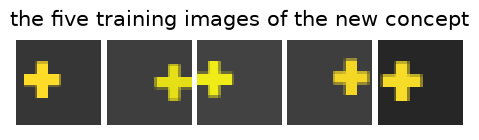

In [21]:
rng = random.Random(77)
C_IMGS = []
for k in range(5):
    objs, _, _ = sample_scene(rng, shapes=SHAPES, force=dict(double=False, shape="cross", color="yellow", size="large", pos=["on the left", "on the right"][k % 2]))
    C_IMGS.append(render(objs, rng.uniform(0.05, 0.30))[0])
C_X = torch.from_numpy(np.stack(C_IMGS)); C_Z = vae_enc(C_X) * SF
C_CAPS = [f"a large yellow sks {['on the left', 'on the right'][k % 2]}" for k in range(5)]
rng = random.Random(78)
NEW_CTX = [f"a {rng.choice(SIZES)} {rng.choice(['red', 'blue', 'green', 'magenta'])} sks {rng.choice(['at the top', 'at the bottom', 'in the center'])}" for _ in range(48)]
IN_CTX = [f"a large yellow sks {p}" for p in ("on the left", "on the right") for _ in range(10)]
DRIFT = [c for c in EV_CAPS if " and " not in c][:200]
LAB_NEW = cap_lab([c.replace("sks", "cross") for c in NEW_CTX]); LAB_DRIFT = cap_lab(DRIFT)

def eval_concept(model_fn=None, emb_fn=encode_text, tok_word="sks", seed=0):
    caps = [c.replace("sks", tok_word) for c in IN_CTX + NEW_CTX] + DRIFT
    x = generate(None, emb=emb_fn(caps), w=4, steps=20, seed=seed, model_fn=model_fn)
    xi, xn, xd = x[:20], x[20:68], x[68:]
    pi, pn, pd = judge(xi)[1], judge(xn)[1], judge(xd)[1]
    one = lambda p: p["nobj"] == 1
    attr = ((pn["co1"] == LAB_NEW[:, 2]) & (pn["pos1"] == LAB_NEW[:, 3]) & (pn["size1"] == LAB_NEW[:, 4])).float().mean().item()
    return dict(cross_in=((pi["sh1"] == 4) & one(pi)).float().mean().item(), cross_new=((pn["sh1"] == 4) & one(pn)).float().mean().item(),
                attr_new=attr, copy=(rms(torch.cat([xi, xn]), C_X).min(1).values < TAU).float().mean().item(),
                drift_acc=attr_acc(pd, LAB_DRIFT)["all1"], leak=(pd["sh1"] == 4).float().mean().item()), x

ADAPT = {}
r, x_sks_base = eval_concept(); ADAPT["base model, no training"] = dict(params=0, time=0, **r)
print("base:", fmt(r))
show(C_X, nrow=5, scale=1.3, title="the five training images of the new concept")

### 13.2. Textual inversion: учим только эмбеддинг слова

В токенизатор добавляется новый токен, его эмбеддинг инициализируется эмбеддингом слова «square» и обучается обычной диффузионной потерей. Все веса U-Net и текстового энкодера заморожены, обучается 512 чисел. Градиент проходит через весь текстовый энкодер CLIP, поэтому шаг дороже, чем кажется по числу параметров.

In [22]:
def textual_inversion(images_z, captions, init_word, steps, lr=5e-3, seed=0):
    seed_all(seed)
    tok_ti = CLIPTokenizer.from_pretrained("openai/clip-vit-base-patch32", model_max_length=L_TXT)
    tok_ti.add_tokens(["<concept>"]); new_id = tok_ti.convert_tokens_to_ids("<concept>")
    te = copy.deepcopy(text_enc); te.resize_token_embeddings(len(tok_ti)); emb_layer = te.get_input_embeddings()
    with torch.no_grad(): emb_layer.weight[new_id] = emb_layer.weight[tok_ti.convert_tokens_to_ids(init_word + "</w>")]
    orig = emb_layer.weight.detach().clone(); emb_layer.weight.requires_grad_(True)
    opt = torch.optim.AdamW([emb_layer.weight], lr, weight_decay=0.0)
    ids = tok_ti(captions, padding="max_length", max_length=L_TXT, return_tensors="pt").input_ids.to(DEVICE)
    for step in range(steps):
        j = torch.randint(0, len(images_z), (16,))
        e = te(ids[j]).last_hidden_state
        loss = diffusion_loss(base_fn, images_z[j].to(DEVICE), e)
        opt.zero_grad(); loss.backward(); opt.step()
        with torch.no_grad():                                                # все строки, кроме новой, остаются прежними
            keep = torch.ones(len(orig), dtype=torch.bool); keep[new_id] = False; emb_layer.weight[keep] = orig[keep]
    te.eval().requires_grad_(False)
    @torch.no_grad()
    def emb_fn(caps):
        out = []
        for i in range(0, len(caps), 256):
            ii = tok_ti(caps[i:i + 256], padding="max_length", max_length=L_TXT, truncation=True, return_tensors="pt").input_ids.to(DEVICE)
            out.append(te(ii).last_hidden_state.cpu())
        return torch.cat(out)
    drift = (emb_layer.weight[new_id] - orig[tok_ti.convert_tokens_to_ids(init_word + "</w>")]).norm().item()
    return emb_fn, drift

with Timer() as t:
    ti_emb, ti_move = textual_inversion(C_Z, [c.replace("sks", "<concept>") for c in C_CAPS], "square", S["steps_ti"])
r, x_ti = eval_concept(emb_fn=ti_emb, tok_word="<concept>"); ADAPT["textual inversion"] = dict(params=512, time=t.s, **r)
print(f"TI on the cross: {t.s:.0f} s, embedding moved by {ti_move:.3f} from 'square'; ", fmt(r))

# контроль: выразимый концепт «крупный зелёный треугольник» под одним токеном
rng = random.Random(79); G_IMGS = []
for k in range(5):
    objs, _, _ = sample_scene(rng, force=dict(double=False, shape="triangle", color="green", size="large", pos=["on the left", "on the right"][k % 2]))
    G_IMGS.append(render(objs, rng.uniform(0.05, 0.30))[0])
G_Z = vae_enc(torch.from_numpy(np.stack(G_IMGS))) * SF
with Timer() as t:
    ti2_emb, _ = textual_inversion(G_Z, [f"a <concept> {['on the left', 'on the right'][k % 2]}" for k in range(5)], "square", S["steps_ti"], seed=1)
probe = [f"a <concept> {p}" for p in PNAMES for _ in range(8)]
x_g = generate(None, emb=ti2_emb(probe), w=4, steps=20, seed=9); pg = judge(x_g)[1]
ti2 = dict(green_triangle=((pg["sh1"] == 2) & (pg["co1"] == 1)).float().mean().item(),
           pos=(pg["pos1"] == torch.tensor([PNAMES.index(p) for p in PNAMES for _ in range(8)])).float().mean().item())
print(f"TI on an expressible concept (large green triangle as one token): {t.s:.0f} s; green triangle rate {ti2['green_triangle']:.3f}, "
      f"position accuracy for 5 positions {ti2['pos']:.3f}")

TI on the cross: 77 s, embedding moved by 1.912 from 'square';  cross_in=0.000  cross_new=0.000  attr_new=0.979  copy=0.000  drift_acc=1.000  leak=0.000
TI on an expressible concept (large green triangle as one token): 77 s; green triangle rate 1.000, position accuracy for 5 positions 1.000


### 13.3. DreamBooth: дообучаем всю U-Net, с сохранением априорного знания и без

DreamBooth дообучает все веса U-Net на изображениях концепта с подписью, содержащей редкий токен. Prior preservation добавляет к каждому батчу столько же изображений, сгенерированных исходной моделью по обычным подписям, и потерю на них с весом 1. Модель напоминает себе, как выглядит «всё остальное». Чтобы увидеть переобучение, качество измеряется после 1/6, 1/2 и полного числа шагов (на CPU это 100, 300 и 600).

In [23]:
PRIOR_CAPS = random.Random(5).sample(sorted(set(caps_unique)), 200)
PRIOR_Z = generate(PRIOR_CAPS, w=4, steps=20, seed=55, decode=False)       # латенты исходной модели
C_EMB = encode_text(C_CAPS).to(DEVICE); PRIOR_EMB = encode_text(PRIOR_CAPS).to(DEVICE)

def finetune(model, params, steps, lr, prior_w=0.0, evals=(), seed=0, name=""):
    params = list(params)
    for p_ in params: p_.requires_grad_(True)
    seed_all(seed); opt = torch.optim.AdamW(params, lr, weight_decay=0.0); res = {}; t0 = time.time(); el = 0.0
    fn = lambda zt, tt, e, **kw: model(zt, tt, encoder_hidden_states=e).sample
    for step in range(1, steps + 1):
        model.train(); j = torch.randint(0, 5, (8,))
        loss = diffusion_loss(fn, C_Z[j].to(DEVICE), C_EMB[j])
        if prior_w > 0:
            jp = torch.randint(0, len(PRIOR_Z), (8,)); loss = loss + prior_w * diffusion_loss(fn, PRIOR_Z[jp].to(DEVICE), PRIOR_EMB[jp])
        opt.zero_grad(); loss.backward(); opt.step()
        if step in evals:
            el += time.time() - t0; model.eval()
            r, x = eval_concept(model_fn=lambda zt, tt, e, **kw: model(zt, tt, encoder_hidden_states=e).sample)
            res[step] = (dict(time=el, **r), x); print(f"{name} step {step:4d}: {fmt(r)}"); t0 = time.time()
    model.eval(); return res

N_DB = S["steps_db"] * 3; EV_STEPS = (N_DB // 6, N_DB // 2, N_DB)   # на CPU: 100, 300, 600
db_noprior = copy.deepcopy(unet)
res_db0 = finetune(db_noprior, db_noprior.parameters(), EV_STEPS[-1], 1e-4, 0.0, EV_STEPS, name="DreamBooth, no prior")
db_prior = copy.deepcopy(unet)
res_db1 = finetune(db_prior, db_prior.parameters(), EV_STEPS[-1], 1e-4, 1.0, EV_STEPS, name="DreamBooth + prior")
for st in EV_STEPS:
    ADAPT[f"DreamBooth {st} steps"] = dict(params=nparam(unet), **res_db0[st][0])
    ADAPT[f"DreamBooth + prior {st} steps"] = dict(params=nparam(unet), **res_db1[st][0])

DreamBooth, no prior step  200: cross_in=1.000  cross_new=0.875  attr_new=1.000  copy=0.015  drift_acc=0.780  leak=0.220
DreamBooth, no prior step  600: cross_in=1.000  cross_new=0.938  attr_new=0.979  copy=0.015  drift_acc=0.760  leak=0.230
DreamBooth, no prior step 1200: cross_in=1.000  cross_new=1.000  attr_new=0.688  copy=0.000  drift_acc=0.710  leak=0.250
DreamBooth + prior step  200: cross_in=1.000  cross_new=0.396  attr_new=1.000  copy=0.000  drift_acc=0.935  leak=0.065
DreamBooth + prior step  600: cross_in=1.000  cross_new=0.396  attr_new=1.000  copy=0.000  drift_acc=0.955  leak=0.045
DreamBooth + prior step 1200: cross_in=1.000  cross_new=0.438  attr_new=1.000  copy=0.000  drift_acc=0.975  leak=0.025


### 13.4. LoRA: низкоранговая добавка к проекциям внимания

LoRA ([Hu et al., 2022](https://arxiv.org/abs/2106.09685)) замораживает исходные веса и добавляет к матрицам $W_q, W_k, W_v, W_o$ всех слоёв внимания низкоранговые поправки $\Delta W = \frac{\alpha}{r} BA$. Матрица $B$ инициализируется нулём, поэтому в начале модель совпадает с исходной. Адаптер подключается средствами `peft`, так же как в официальных скриптах diffusers. После обучения силу адаптера можно менять без переобучения: множитель 0 возвращает исходную модель, 1 — полную поправку.

In [24]:
from peft import LoraConfig
lora_unet = copy.deepcopy(unet)
lora_unet.add_adapter(LoraConfig(r=4, lora_alpha=4, init_lora_weights="gaussian", target_modules=["to_q", "to_k", "to_v", "to_out.0"]))
lora_params = [p for n, p in lora_unet.named_parameters() if "lora" in n]
for n, p in lora_unet.named_parameters(): p.requires_grad_("lora" in n)
z_probe = torch.randn(4, 4, 8, 8, device=DEVICE); t_probe = torch.full((4,), 500, device=DEVICE); e_probe = C_EMB[:4]
with torch.no_grad(): d0 = (lora_unet(z_probe, t_probe, encoder_hidden_states=e_probe).sample - unet(z_probe, t_probe, encoder_hidden_states=e_probe).sample).abs().max().item()
print(f"LoRA r=4: {sum(p.numel() for p in lora_params)} trainable params ({100 * sum(p.numel() for p in lora_params) / nparam(unet):.2f} % of U-Net); "
      f"output change at init {d0:.1e}")
res_lora = finetune(lora_unet, lora_params, EV_STEPS[-1], 1e-3, 0.0, EV_STEPS[1:], name="LoRA r=4")
for st in EV_STEPS[1:]: ADAPT[f"LoRA r=4, {st} steps"] = dict(params=sum(p.numel() for p in lora_params), **res_lora[st][0])
lora_scale = {}
for sc in (0.0, 0.5, 1.5):
    lora_unet.set_adapters(["default"], weights=[sc])
    lora_scale[sc] = eval_concept(model_fn=lambda zt, tt, e, **kw: lora_unet(zt, tt, encoder_hidden_states=e).sample)[0]
    print(f"LoRA scale {sc}: {fmt(lora_scale[sc])}")
lora_unet.set_adapters(["default"], weights=[1.0])

LoRA r=4: 68096 trainable params (1.41 % of U-Net); output change at init 0.0e+00
LoRA r=4 step  600: cross_in=1.000  cross_new=0.583  attr_new=1.000  copy=0.000  drift_acc=0.810  leak=0.160
LoRA r=4 step 1200: cross_in=1.000  cross_new=0.688  attr_new=1.000  copy=0.000  drift_acc=0.785  leak=0.175
LoRA scale 0.0: cross_in=0.000  cross_new=0.000  attr_new=1.000  copy=0.000  drift_acc=1.000  leak=0.000
LoRA scale 0.5: cross_in=0.750  cross_new=0.125  attr_new=1.000  copy=0.000  drift_acc=0.975  leak=0.025
LoRA scale 1.5: cross_in=0.750  cross_new=0.542  attr_new=0.729  copy=0.000  drift_acc=0.365  leak=0.280


### 13.5. Сводка адаптации

method                              params  time,s  cross in  cross new  attr new   copy  drift acc   leak
base model, no training                  0       0     0.000      0.000     1.000  0.000      1.000  0.000
textual inversion                      512      77     0.000      0.000     0.979  0.000      1.000  0.000
DreamBooth 200 steps               4823684      12     1.000      0.875     1.000  0.015      0.780  0.220
DreamBooth + prior 200 steps       4823684      22     1.000      0.396     1.000  0.000      0.935  0.065
DreamBooth 600 steps               4823684      35     1.000      0.938     0.979  0.015      0.760  0.230
DreamBooth + prior 600 steps       4823684      69     1.000      0.396     1.000  0.000      0.955  0.045
DreamBooth 1200 steps              4823684      69     1.000      1.000     0.688  0.000      0.710  0.250
DreamBooth + prior 1200 steps      4823684     141     1.000      0.438     1.000  0.000      0.975  0.025
LoRA r=4, 600 steps                  

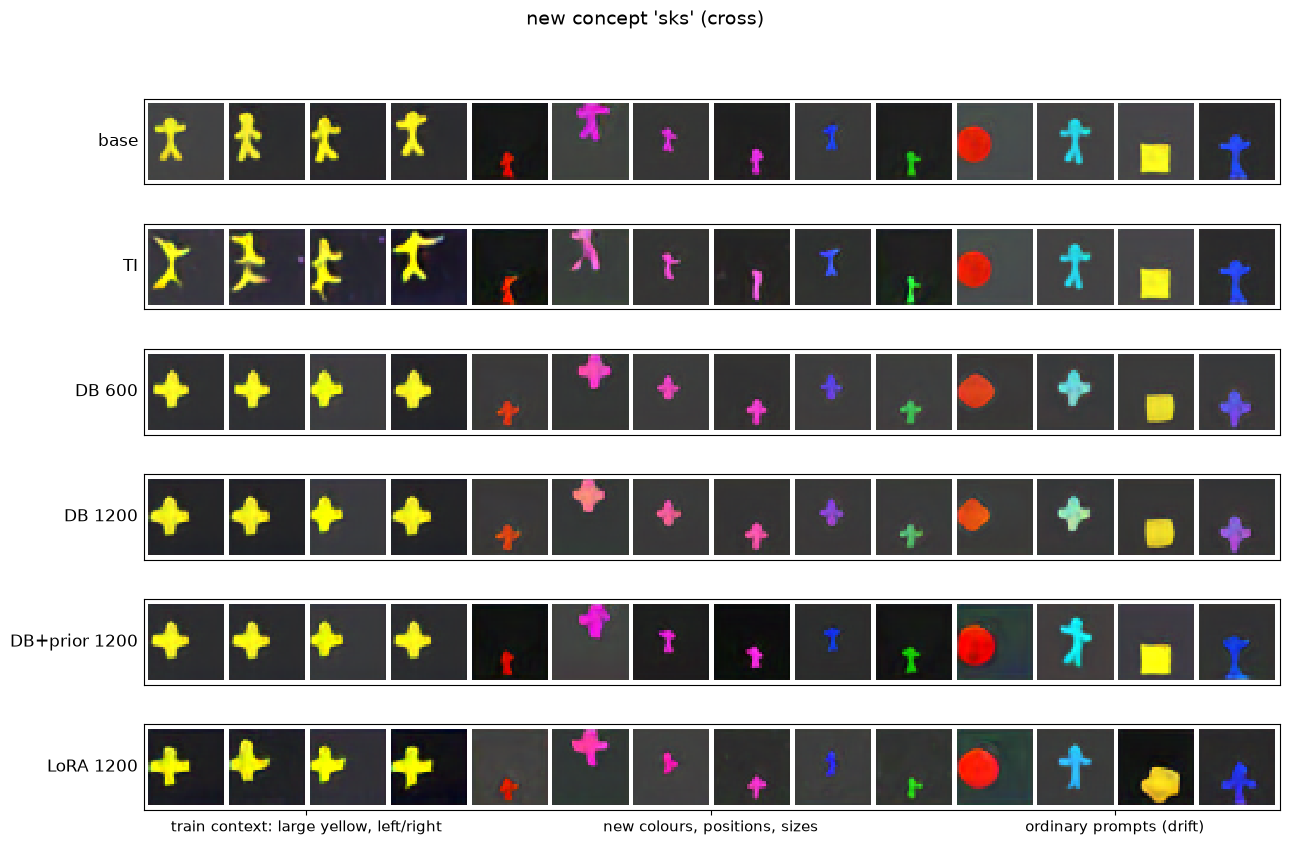

In [25]:
print(f"{'method':32s} {'params':>9s} {'time,s':>7s} {'cross in':>9s} {'cross new':>10s} {'attr new':>9s} {'copy':>6s} {'drift acc':>10s} {'leak':>6s}")
for k, v in ADAPT.items():
    print(f"{k:32s} {v['params']:9d} {v['time']:7.0f} {v['cross_in']:9.3f} {v['cross_new']:10.3f} {v['attr_new']:9.3f} {v['copy']:6.3f} {v['drift_acc']:10.3f} {v['leak']:6.3f}")
rows = [("base", x_sks_base), ("TI", x_ti), (f"DB {EV_STEPS[1]}", res_db0[EV_STEPS[1]][1]), (f"DB {EV_STEPS[-1]}", res_db0[EV_STEPS[-1]][1]),
        (f"DB+prior {EV_STEPS[-1]}", res_db1[EV_STEPS[-1]][1]), (f"LoRA {EV_STEPS[-1]}", res_lora[EV_STEPS[-1]][1])]
sel = list(range(0, 4)) + list(range(20, 26)) + list(range(68, 72))            # 4 обучающих контекста, 6 новых, 4 обычные подписи
fig, ax = plt.subplots(len(rows), 1, figsize=(13, 1.35 * len(rows) + 0.6))
for a, (nm, x) in zip(ax, rows):
    a.imshow(torchvision.utils.make_grid(x[sel], nrow=len(sel), padding=2, pad_value=1).permute(1, 2, 0), interpolation="nearest")
    a.set_yticks([]); a.set_xticks([]); a.set_ylabel(nm, rotation=0, ha="right", va="center", fontsize=12)
ax[-1].set_xticks([68, 238, 408]); ax[-1].set_xticklabels(["train context: large yellow, left/right", "new colours, positions, sizes", "ordinary prompts (drift)"], fontsize=11)
plt.suptitle("new concept 'sks' (cross)", fontsize=14); plt.tight_layout(rect=(0, 0, 1, 0.96)); plt.show()

## 14. ControlNet: контуры, глубина, поза, сегментация

### 14.1. Обучаемая копия энкодера и нулевые свёртки

`ControlNetModel.from_unet` копирует входную свёртку, все down-блоки и средний блок U-Net вместе с их весами. Добавляются два элемента: маленький свёрточный энкодер управляющей карты (32×32 → 8×8) и нулевые свёртки 1×1 на каждом выходе копии. Их выходы прибавляются к skip-соединениям замороженной U-Net. Поскольку нулевые свёртки в начале дают ровно ноль, необученный ControlNet не меняет модель, и обучение начинается с исходного качества ([Zhang et al., 2023](https://arxiv.org/abs/2302.05543)).

Здесь обучается один ControlNet сразу на четырёх типах карт, как в объединённых моделях вроде ControlNet-Union. Вход — 12 каналов: контуры (1), глубина (1), сегментация в виде цветной палитры (3), поза (3) и четыре канала-индикатора типа. В каждом примере активен один тип, остальные каналы нулевые. Поза выбирается только для изображений с человечком. В 30 % примеров подпись выбрасывается, чтобы модель училась извлекать смысл из самой карты, как в исходной статье (там 50 %).

In [26]:
SEG_PALETTE = torch.tensor([[0, 0, 0], [1, .5, 0], [0, .7, 0], [1, 0, 0], [.6, .3, 1], [1, 1, 1]], dtype=torch.float32)
CTYPES = ["edges", "depth", "segmentation", "pose"]
def control_maps(X, SEG, DEP, POSE, types):
    """Собирает 12-канальную карту; types: список индексов типа (0..3) для каждого примера."""
    n = len(X); c = torch.zeros(n, 12, 32, 32)
    x01 = u8(X); t_ = torch.as_tensor(types)
    for k in range(4):
        m = t_ == k
        if not m.any(): continue
        if k == 0: c[m, 0:1] = sobel_edges(x01[m])
        if k == 1: c[m, 1:2] = u8(DEP[m])[:, None]
        if k == 2: c[m, 2:5] = SEG_PALETTE[SEG[m].long()].permute(0, 3, 1, 2)
        if k == 3: c[m, 5:8] = u8(POSE[m])
        c[m, 8 + k] = 1.0
    return c

HAS_PERSON = (TR["lab"][:, 1] == 3) | (TR["lab"][:, 5] == 3)
controlnet = ControlNetModel.from_unet(unet, conditioning_channels=12, conditioning_embedding_out_channels=(16, 32, 64)).to(DEVICE)
for p in controlnet.parameters(): p.requires_grad_(True)

def cn_forward(cn, zt, t, e, cond, scale=1.0):
    d, m = cn(zt, t, encoder_hidden_states=e, controlnet_cond=cond, conditioning_scale=scale, return_dict=False)
    return unet(zt, t, encoder_hidden_states=e, down_block_additional_residuals=d, mid_block_additional_residual=m).sample

i = torch.arange(8); cond = control_maps(TR["X"][i], TR["SEG"][i], TR["DEP"][i], TR["POSE"][i], [0] * 8).to(DEVICE)
zt = torch.randn(8, 4, 8, 8, device=DEVICE); tt = torch.full((8,), 400, device=DEVICE); e = encode_text(TR["caps"][:8]).to(DEVICE)
with torch.no_grad():
    diff0 = (cn_forward(controlnet, zt, tt, e, cond) - unet(zt, tt, encoder_hidden_states=e).sample).abs().max().item()
print(f"ControlNet: {nparam(controlnet) / 1e6:.2f} M trainable params (U-Net {nparam(unet) / 1e6:.2f} M, frozen)")
print(f"output change of the untrained ControlNet: {diff0:.1e} (zero convolutions)")

seed_all(0); opt = torch.optim.AdamW(controlnet.parameters(), 3e-4, weight_decay=0.0); cn_log = []
g = torch.Generator().manual_seed(9)
with Timer() as t:
    for step, (i, z0, emb) in enumerate(train_batches(S["bs"], S["steps_cn"], seed=8, p_drop=0.3)):
        types = torch.randint(0, 3, (len(i),), generator=g)
        hp = HAS_PERSON[i]; pick_pose = hp & (torch.rand(len(i), generator=g) < 0.4); types[pick_pose] = 3
        cond = control_maps(TR["X"][i], TR["SEG"][i], TR["DEP"][i], TR["POSE"][i], types).to(DEVICE)
        loss = diffusion_loss(lambda zt_, tt_, e_: cn_forward(controlnet, zt_, tt_, e_, cond), z0, emb)
        opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(controlnet.parameters(), 1.0); opt.step(); cn_log.append(loss.item())
controlnet.eval().requires_grad_(False); t_cn = t.s
print(f"{S['steps_cn']} steps in {t_cn / 60:.1f} min; loss first 100 {np.mean(cn_log[:100]):.4f} -> last 200 {np.mean(cn_log[-200:]):.4f} "
      f"(U-Net alone, last 200 steps: {np.mean(unet_log[-200:]):.4f})")

ControlNet: 2.32 M trainable params (U-Net 4.82 M, frozen)
output change of the untrained ControlNet: 0.0e+00 (zero convolutions)
4000 steps in 9.0 min; loss first 100 0.0261 -> last 200 0.0155 (U-Net alone, last 200 steps: 0.0271)


### 14.2. Проверка соблюдения управляющей карты

Управляющие карты берутся у 200 тестовых изображений (для позы — у 200 тестовых изображений с человечком), подписи — их же. Сгенерированное изображение снова проходит через «препроцессор»: Собель для контуров, аннотатор для глубины, сегментации и позы. Затем полученная карта сравнивается с заданной. Метрики: F1 контуров с допуском 1 пиксель, MAE глубины, mIoU сегментации и IoU масок конечностей для позы. Две опорные строки: без ControlNet (`scale = 0`; совпадение здесь случайное, за счёт подписи) и настоящие изображения (погрешность самих препроцессоров).

In [27]:
def edge_f1(pred, gt):
    dil = lambda e: F.max_pool2d(e, 3, 1, 1)
    p = (pred * dil(gt)).sum() / pred.sum().clamp(min=1); r = (gt * dil(pred)).sum() / gt.sum().clamp(min=1)
    return float(2 * p * r / (p + r).clamp(min=1e-8))

te_person = torch.where((TE["lab"][:, 1] == 3) | (TE["lab"][:, 5] == 3))[0][:200]
te_any = torch.arange(N_EV, N_EV + 200)                                    # карты берутся из эталонной части теста
assert te_any[-1] < len(TE["caps"]) and len(te_person) == 200, "мало тестовых изображений для ControlNet"
def control_set(idx, k):
    return control_maps(TE["X"][idx], TE["SEG"][idx], TE["DEP"][idx], TE["POSE"][idx], [k] * len(idx)), [TE["caps"][j] for j in idx.tolist()]

def adherence(x, idx, k):
    if k == 0: return edge_f1(sobel_edges(x), sobel_edges(u8(TE["X"][idx])))
    s_, d_, p_ = annotate(x)
    if k == 1: return float((d_ - u8(TE["DEP"][idx])).abs().mean())
    if k == 2: return miou(s_, TE["SEG"][idx].long())
    return mask_iou(pose_mask(p_), pose_mask(u8(TE["POSE"][idx])))

def cn_model_fn(cond, scale):
    def fn(zt, tt, e, idx=None, cond_flag=None, **kw):
        c = cond[idx].to(DEVICE); c = torch.cat([c, c]) if len(zt) == 2 * len(c) else c
        return cn_forward(controlnet, zt, tt, e, c, scale)
    return fn

CN_RES = {}; CN_IMGS = {}
with Timer() as t:
    for k, name in enumerate(CTYPES):
        idx = te_person if k == 3 else te_any; cond, caps = control_set(idx, k)
        row = {"real images": adherence(u8(TE["X"][idx]), idx, k)}
        for sc in ((0.0, 0.5, 1.0, 1.5) if k == 0 else (0.0, 1.0)):
            x = generate(caps, w=4, steps=20, seed=31, model_fn=cn_model_fn(cond, sc))
            a = attr_acc(judge(x)[1], TE["lab"][idx])
            row[f"scale {sc}"] = adherence(x, idx, k); row[f"caption acc, scale {sc}"] = a.get("all1", float("nan"))
            if sc == 1.0: CN_IMGS[name] = (cond[:6], x[:6])
        CN_RES[name] = row
print(f"evaluation: {t.s:.0f} s")
metric = {"edges": "edge F1 (higher is better)", "depth": "depth MAE (lower is better)", "segmentation": "seg mIoU (higher is better)", "pose": "limb IoU (higher is better)"}
for name, row in CN_RES.items():
    print(f"{name:12s} {metric[name]:28s}: " + " | ".join(f"{k} {v:.3f}" for k, v in row.items() if not k.startswith("caption")))
    print(f"{'':12s} {'single-object caption accuracy':28s}: " + " | ".join(f"{k.replace('caption acc, ', '')} {v:.3f}" for k, v in row.items() if k.startswith("caption")))

evaluation: 15 s
edges        edge F1 (higher is better)  : real images 1.000 | scale 0.0 0.820 | scale 0.5 0.990 | scale 1.0 1.000 | scale 1.5 1.000
             single-object caption accuracy: scale 0.0 1.000 | scale 0.5 1.000 | scale 1.0 1.000 | scale 1.5 1.000
depth        depth MAE (lower is better) : real images 0.012 | scale 0.0 0.043 | scale 1.0 0.016
             single-object caption accuracy: scale 0.0 1.000 | scale 1.0 1.000
segmentation seg mIoU (higher is better) : real images 0.766 | scale 0.0 0.468 | scale 1.0 0.713
             single-object caption accuracy: scale 0.0 1.000 | scale 1.0 1.000
pose         limb IoU (higher is better) : real images 0.744 | scale 0.0 0.283 | scale 1.0 0.686
             single-object caption accuracy: scale 0.0 1.000 | scale 1.0 1.000


### 14.3. Карта задаёт геометрию, подпись — всё остальное

Ниже для каждого типа показаны управляющая карта и результат с исходной подписью. В последних строках одна и та же карта сегментации сочетается с подписями разных цветов: если ControlNet обучен правильно, форма и положение берутся из карты, а цвет — из текста.

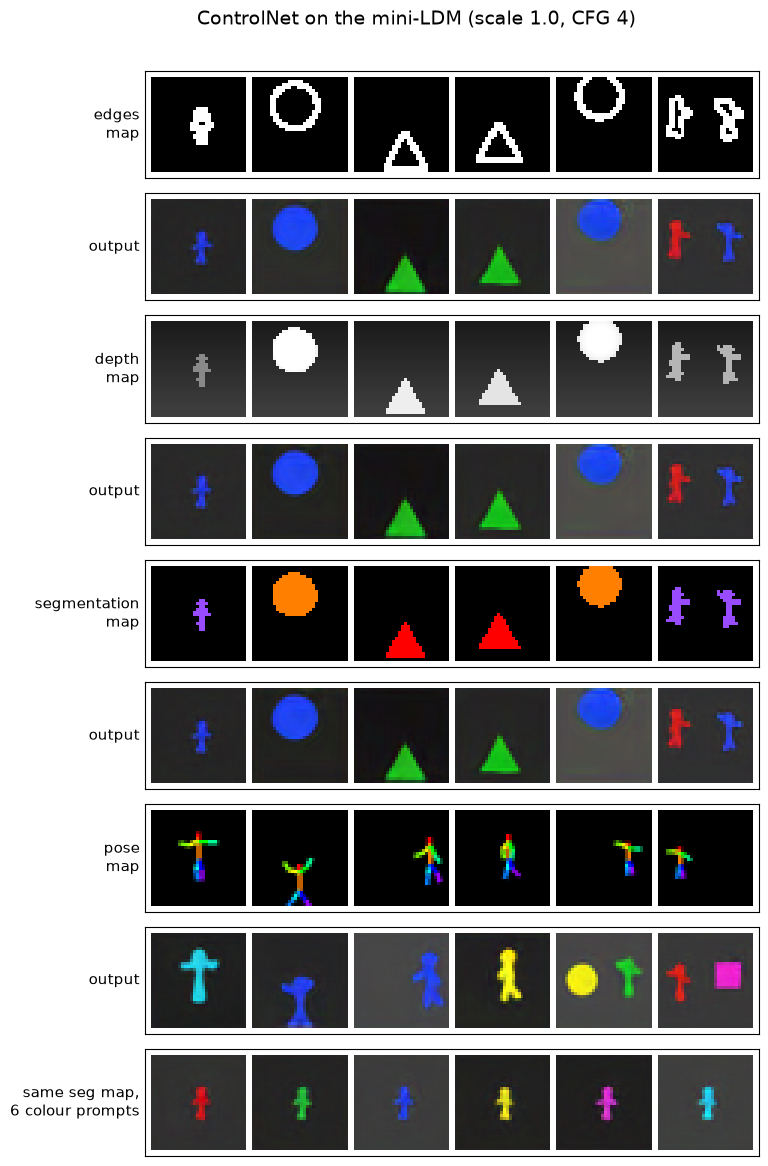

colour requested vs colour detected: [('red', 'red'), ('green', 'green'), ('blue', 'blue'), ('yellow', 'yellow'), ('magenta', 'magenta'), ('cyan', 'cyan')]


In [28]:
def show_map(c, k):
    if k == 0: return c[0:1].repeat(3, 1, 1)
    if k == 1: return c[1:2].repeat(3, 1, 1)
    return c[2:5] if k == 2 else c[5:8]
fig, ax = plt.subplots(len(CTYPES) * 2 + 1, 1, figsize=(8, 1.25 * (2 * len(CTYPES) + 1) + 0.6))
for k, name in enumerate(CTYPES):
    cond, x = CN_IMGS[name]
    ax[2 * k].imshow(torchvision.utils.make_grid(torch.stack([show_map(c, k) for c in cond]), nrow=6, padding=2, pad_value=1).permute(1, 2, 0), interpolation="nearest")
    ax[2 * k + 1].imshow(torchvision.utils.make_grid(x, nrow=6, padding=2, pad_value=1).permute(1, 2, 0), interpolation="nearest")
    ax[2 * k].set_ylabel(f"{name}\nmap", rotation=0, ha="right", va="center", fontsize=11); ax[2 * k + 1].set_ylabel("output", rotation=0, ha="right", va="center", fontsize=11)
j = te_any[:1].repeat(6); cond, _ = control_set(j, 2)
p0 = parse_cap(TE["caps"][int(j[0])])
caps_c = [(f"a {p0['size']} {c} {p0['shape']} {p0['pos']}" if not p0.get("double") else
           f"a {c} {p0['shape']} on the left and a {c} {p0['shape2']} on the right") for c in CNAMES]
x = generate(caps_c, w=4, steps=20, seed=32, model_fn=cn_model_fn(cond, 1.0))
ax[-1].imshow(torchvision.utils.make_grid(x, nrow=6, padding=2, pad_value=1).permute(1, 2, 0), interpolation="nearest")
ax[-1].set_ylabel("same seg map,\n6 colour prompts", rotation=0, ha="right", va="center", fontsize=11)
for a in ax: a.set_xticks([]); a.set_yticks([])
plt.suptitle("ControlNet on the mini-LDM (scale 1.0, CFG 4)", fontsize=14); plt.tight_layout(rect=(0, 0, 1, 0.97)); plt.show()
pc = judge(x)[1]
print("colour requested vs colour detected:", list(zip(CNAMES, [CNAMES[i] for i in pc["co1"].tolist()])))

## 15. IP-Adapter: изображение как подсказка

IP-Adapter ([Ye et al., 2023](https://arxiv.org/abs/2308.06721)) добавляет к каждому слою cross-attention вторую, развязанную ветку внимания. Глобальный эмбеддинг изображения из замороженного CLIP-энкодера проецируется в 4 токена, и для них в каждом слое заводятся свои матрицы $W'_k, W'_v$. Запрос $Q$ общий: $\mathrm{Attn}(Q, K_{\text{txt}}, V_{\text{txt}}) + \lambda \cdot \mathrm{Attn}(Q, K_{\text{img}}, V_{\text{img}})$. U-Net и оба энкодера заморожены. Новые матрицы инициализируются копиями текстовых $W_k, W_v$, как в статье. Обучение — обычная диффузионная потеря на парах «изображение — его же эмбеддинг», подпись выбрасывается в половине примеров, чтобы модель училась опираться на образ.

Ниже ветка реализована собственным attention processor для diffusers: класс, который получает модуль `Attention` и вычисляет внимание. Это тот же механизм, которым IP-Adapter встроен в саму библиотеку. Эмбеддинги CLIP ViT-B/32 для 3000 обучающих изображений считаются один раз (изображение увеличивается до 224×224).

In [29]:
class IPAttnProcessor(nn.Module):
    def __init__(self, attn):
        super().__init__(); self.to_k_ip = copy.deepcopy(attn.to_k); self.to_v_ip = copy.deepcopy(attn.to_v)
        self.scale = 1.0; self.tokens = None
    def __call__(self, attn, hidden_states, encoder_hidden_states=None, attention_mask=None, temb=None, **kw):
        b, n, _ = hidden_states.shape; h = attn.heads
        ctx = hidden_states if encoder_hidden_states is None else encoder_hidden_states
        split = lambda x: x.view(b, -1, h, x.shape[-1] // h).transpose(1, 2)
        q = split(attn.to_q(hidden_states))
        o = F.scaled_dot_product_attention(q, split(attn.to_k(ctx)), split(attn.to_v(ctx)))
        if self.tokens is not None and self.scale != 0:
            o = o + self.scale * F.scaled_dot_product_attention(q, split(self.to_k_ip(self.tokens)), split(self.to_v_ip(self.tokens)))
        o = o.transpose(1, 2).reshape(b, n, -1)
        return attn.to_out[1](attn.to_out[0](o))

class ImageProj(nn.Module):
    def __init__(self, d_in=512, d=512, n_tok=4):
        super().__init__(); self.n = n_tok; self.lin = nn.Linear(d_in, d * n_tok); self.norm = nn.LayerNorm(d)
    def forward(self, e): return self.norm(self.lin(e).view(len(e), self.n, -1))

ip_unet = copy.deepcopy(unet); procs = {}; ip_procs = []
for name, mod in ip_unet.named_modules():
    if name.endswith("attn2"): procs[name + ".processor"] = IPAttnProcessor(mod).to(DEVICE); ip_procs.append(procs[name + ".processor"])
for k in ip_unet.attn_processors:
    procs.setdefault(k, ip_unet.attn_processors[k])
ip_unet.set_attn_processor(procs)
ip_proj = ImageProj().to(DEVICE)
ip_params = list(ip_proj.parameters()) + [p for pr in ip_procs for p in pr.parameters()]
for p in ip_params: p.requires_grad_(True)
def set_ip(tokens, scale=1.0):
    for pr in ip_procs: pr.tokens, pr.scale = tokens, scale

with Timer() as t_emb:
    IP_IDX = torch.randperm(S["n_train"], generator=torch.Generator().manual_seed(4))[:S["n_ip"]]
    IP_EMB = clip_img_emb(u8(TR["X"][IP_IDX]))
print(f"IP-Adapter: {sum(p.numel() for p in ip_params) / 1e6:.2f} M trainable params in {len(ip_procs)} cross-attention layers; "
      f"CLIP image embeddings for {len(IP_IDX)} images: {t_emb.s:.0f} s")
seed_all(0); opt = torch.optim.AdamW(ip_params, 1e-3, weight_decay=0.0); ip_log = []
g = torch.Generator().manual_seed(12)
with Timer() as t:
    for step in range(S["steps_ip"]):
        j = torch.randint(0, len(IP_IDX), (32,), generator=g); i = IP_IDX[j]
        caps = [TR["caps"][k] if random.random() > 0.5 else "" for k in i.tolist()]
        ie = IP_EMB[j].to(DEVICE); ie = torch.where(torch.rand(len(ie), 1, device=DEVICE) < 0.05, torch.zeros_like(ie), ie)
        set_ip(ip_proj(ie))
        loss = diffusion_loss(lambda zt, tt, e: ip_unet(zt, tt, encoder_hidden_states=e).sample, Z_TR[i].to(DEVICE), encode_text(caps).to(DEVICE))
        opt.zero_grad(); loss.backward(); opt.step(); ip_log.append(loss.item())
ip_proj.eval().requires_grad_(False); [p.requires_grad_(False) for p in ip_params]; t_ip = t.s
print(f"{S['steps_ip']} steps in {t_ip / 60:.1f} min; loss first 100 {np.mean(ip_log[:100]):.4f} -> last 100 {np.mean(ip_log[-100:]):.4f}")

def ip_model_fn(img_emb, scale=1.0):
    def fn(zt, tt, e, idx=None, **kw):
        ie = img_emb[idx].to(DEVICE)
        if len(zt) == 2 * len(ie): ie = torch.cat([torch.zeros_like(ie), ie])       # безусловная ветка: нулевой образ
        set_ip(ip_proj(ie), scale); out = ip_unet(zt, tt, encoder_hidden_states=e).sample; set_ip(None); return out
    return fn

IP-Adapter: 1.77 M trainable params in 7 cross-attention layers; CLIP image embeddings for 20000 images: 75 s
3000 steps in 4.1 min; loss first 100 0.0276 -> last 100 0.0247


### 15.1. Следование образцу и баланс «текст против образа»

Сначала подписи нет совсем (пустая строка), есть только образ: 200 тестовых изображений с одной фигурой. Измеряется, какую долю атрибутов образца (форма, цвет, положение, размер) воспроизводит генерация. Для сравнения — та же модель без образа (безусловная генерация, совпадения случайны). Генерация не должна быть копией: RMS до образца сравнивается с RMS между двумя настоящими изображениями с одинаковой подписью.

Затем подпись и образ противоречат друг другу: в подписи другой цвет и другая форма. Меняя $\lambda$, видно, как управление переходит от текста к образу.

no image (unconditional)     shape=0.305  color=0.195  pos=0.235  size=0.535
image prompt, lambda=0.5     shape=0.790  color=0.880  pos=0.380  size=0.880
image prompt, lambda=1.0     shape=0.975  color=0.995  pos=0.605  size=0.935
RMS generation-reference: median 0.119; copies (RMS < 0.05): 0.030
lambda=0.00: color_text=1.00  color_image=0.00  shape_text=1.00  shape_image=0.00
lambda=0.25: color_text=1.00  color_image=0.00  shape_text=1.00  shape_image=0.00
lambda=0.50: color_text=0.99  color_image=0.01  shape_text=1.00  shape_image=0.00
lambda=0.75: color_text=0.95  color_image=0.04  shape_text=1.00  shape_image=0.00
lambda=1.00: color_text=0.86  color_image=0.09  shape_text=0.96  shape_image=0.03


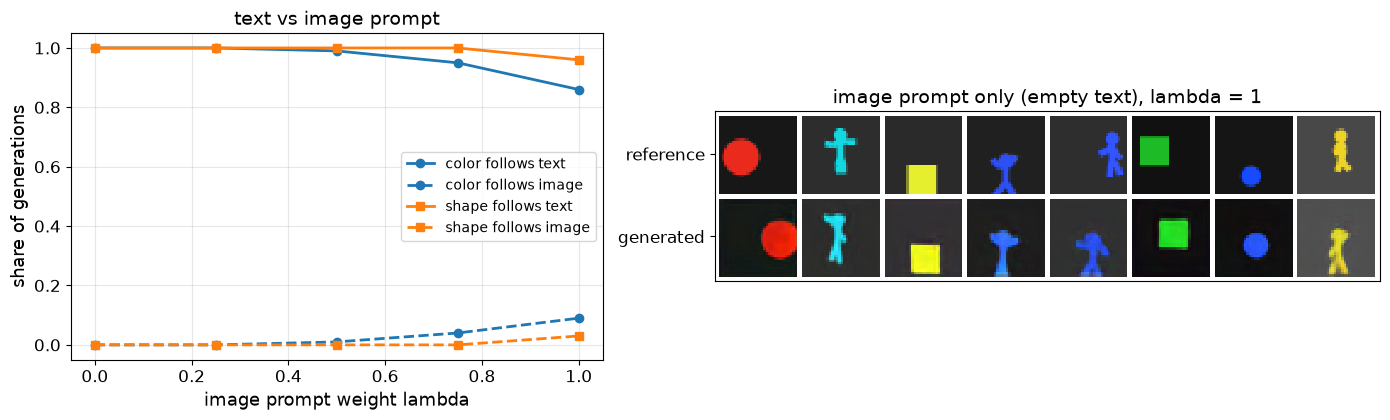

In [30]:
ref_idx = torch.where(TE["lab"][:, 0] == 1)[0][:200]; ref_x = u8(TE["X"][ref_idx]); ref_lab = TE["lab"][ref_idx]; ref_emb = clip_img_emb(ref_x)
def agree(p, lab):
    return {k: (p[h] == lab[:, j]).float().mean().item() for k, h, j in (("shape", "sh1", 1), ("color", "co1", 2), ("pos", "pos1", 3), ("size", "size1", 4))}
IP_RES = {}
x_unc = generate([""] * 200, w=4, steps=20, seed=41); IP_RES["no image (unconditional)"] = agree(judge(x_unc)[1], ref_lab)
for sc in (0.5, 1.0):
    x_ip = generate([""] * 200, w=4, steps=20, seed=41, model_fn=ip_model_fn(ref_emb, sc))
    IP_RES[f"image prompt, lambda={sc}"] = agree(judge(x_ip)[1], ref_lab)
    if sc == 1.0: X_IP = x_ip
for k, v in IP_RES.items(): print(f"{k:28s} " + "  ".join(f"{a}={b:.3f}" for a, b in v.items()))
d_ref = rms(X_IP, ref_x).diag()
print(f"RMS generation-reference: median {d_ref.median():.3f}; copies (RMS < {TAU}): {(d_ref < TAU).float().mean():.3f}")

rng = random.Random(3); conflict = []
for j in range(100):
    p = parse_cap(TE["caps"][int(ref_idx[j])])
    c_new = rng.choice([c for c in CNAMES if c != p["color"]]); s_new = rng.choice([s for s in BASE_SHAPES if s != p["shape"]])
    conflict.append((f"a {p['size']} {c_new} {s_new} {p['pos']}", CNAMES.index(c_new), SHAPES.index(s_new)))
cf_caps = [c for c, _, _ in conflict]; cf_col = torch.tensor([c for _, c, _ in conflict]); cf_sh = torch.tensor([s for _, _, s in conflict])
lam_res = {}
for lam in (0.0, 0.25, 0.5, 0.75, 1.0):
    x = generate(cf_caps, w=4, steps=20, seed=42, model_fn=ip_model_fn(ref_emb[:100], lam)); p_ = judge(x)[1]
    lam_res[lam] = dict(color_text=(p_["co1"] == cf_col).float().mean().item(), color_image=(p_["co1"] == ref_lab[:100, 2]).float().mean().item(),
                        shape_text=(p_["sh1"] == cf_sh).float().mean().item(), shape_image=(p_["sh1"] == ref_lab[:100, 1]).float().mean().item())
    if lam == 0.5: X_CONF = x
    print(f"lambda={lam:4.2f}: " + "  ".join(f"{a}={b:.2f}" for a, b in lam_res[lam].items()))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.3), gridspec_kw=dict(width_ratios=[1, 1.25]))
L = list(lam_res)
for k, st, cl in (("color_text", "o-", "C0"), ("color_image", "o--", "C0"), ("shape_text", "s-", "C1"), ("shape_image", "s--", "C1")):
    ax[0].plot(L, [lam_res[l][k] for l in L], st, color=cl, lw=2, label=k.replace("_", " follows "))
ax[0].set_xlabel("image prompt weight lambda", fontsize=13); ax[0].set_ylabel("share of generations", fontsize=13)
ax[0].set_title("text vs image prompt", fontsize=14); ax[0].legend(fontsize=10); ax[0].grid(alpha=0.3); ax[0].tick_params(labelsize=12)
ax[1].imshow(torchvision.utils.make_grid(torch.cat([ref_x[:8], X_IP[:8]]), nrow=8, padding=2, pad_value=1).permute(1, 2, 0), interpolation="nearest")
ax[1].set_xticks([]); ax[1].set_yticks([17, 51]); ax[1].set_yticklabels(["reference", "generated"], fontsize=12)
ax[1].set_title("image prompt only (empty text), lambda = 1", fontsize=14)
plt.tight_layout(); plt.show()

## 16. Inpainting: смешивание латентов против обученной модели

Задача: в тестовой сцене с двумя фигурами заменить правую фигуру на другую (новые цвет и форма из подписи), не трогая левую половину. Маска — правая половина латента (4 из 8 столбцов), то есть правая половина изображения.

- Смешивание (как в разделе 8.6 и в RePaint без повторного зашумления, [Lugmayr et al., 2022](https://arxiv.org/abs/2201.09865)): обычная U-Net, после каждого шага латент вне маски заменяется зашумлённым латентом оригинала. Модель не знает, что часть изображения фиксирована, и видит контекст только через этот «подклеенный» шум.
- Inpainting-модель, как SD-Inpainting: на вход U-Net подаются 9 каналов — зашумлённый латент, маска и латент с вырезанной областью. Модель инициализируется весами базовой, новые входные каналы — нулями, и дообучается на случайных масках (половины и прямоугольники).

В обоих случаях итог «склеивается» с оригиналом в пикселях вне маски, как это делают на практике. Метрики: верна ли новая правая фигура (оценщик), сохранена ли левая фигура, и шов — разница яркости фона слева и справа. В настоящих изображениях ShapeWorld фон однородный, поэтому любая разница — артефакт.

inpainting U-Net: 2000 steps in 4.2 min; loss first 100 0.0253 -> last 100 0.0136
original images              right_correct=0.000  left_kept=1.000  seam=0.001
latent blending, base U-Net  right_correct=1.000  left_kept=0.995  seam=0.002
9-channel inpainting U-Net   right_correct=1.000  left_kept=0.995  seam=0.002
(original images: right_correct = 0 by construction, the new caption changes the right object)


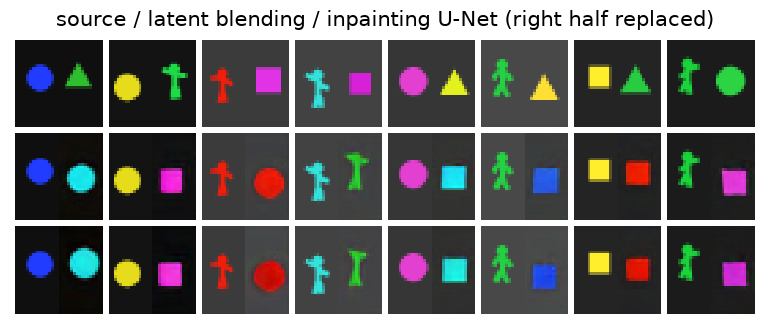

new captions: ['a blue circle on the left and a cyan circle on the right', 'a yellow circle on the left and a magenta square on the right', 'a red person on the left and a red circle on the right', 'a cyan person on the left and a green person on the right']


In [31]:
inp_unet = make_unet(in_ch=9)
sd_ = {k: v.clone() for k, v in unet.state_dict().items()}
w_in = torch.zeros_like(inp_unet.conv_in.weight); w_in[:, :4] = sd_["conv_in.weight"]; sd_["conv_in.weight"] = w_in
inp_unet.load_state_dict(sd_)
def rand_masks(n, g):
    m = torch.zeros(n, 1, 8, 8)
    for i in range(n):
        r = torch.rand(1, generator=g).item()
        if r < 0.5:                                                          # половина кадра
            side = torch.randint(0, 4, (1,), generator=g).item()
            if side == 0: m[i, :, :, 4:] = 1
            elif side == 1: m[i, :, :, :4] = 1
            elif side == 2: m[i, :, :4] = 1
            else: m[i, :, 4:] = 1
        else:                                                                # случайный прямоугольник
            h, w_ = torch.randint(2, 7, (2,), generator=g).tolist(); y, x = torch.randint(0, 9 - h, (1,), generator=g).item(), torch.randint(0, 9 - w_, (1,), generator=g).item()
            m[i, :, y:y + h, x:x + w_] = 1
    return m
seed_all(0); opt = torch.optim.AdamW(inp_unet.parameters(), 2e-4, weight_decay=0.0); g = torch.Generator().manual_seed(13); inp_log = []
with Timer() as t:
    for step, (i, z0, emb) in enumerate(train_batches(S["bs"], S["steps_inp"], seed=14)):
        m = rand_masks(len(i), g).to(DEVICE); zm = z0 * (1 - m)
        loss = diffusion_loss(lambda zt, tt, e: inp_unet(torch.cat([zt, m, zm], 1), tt, encoder_hidden_states=e).sample, z0, emb)
        opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(inp_unet.parameters(), 1.0); opt.step(); inp_log.append(loss.item())
inp_unet.eval().requires_grad_(False); t_inp = t.s
print(f"inpainting U-Net: {S['steps_inp']} steps in {t_inp / 60:.1f} min; loss first 100 {np.mean(inp_log[:100]):.4f} -> last 100 {np.mean(inp_log[-100:]):.4f}")

two = torch.where(TE["lab"][:, 0] == 2)[0][:200]; x_src = u8(TE["X"][two]); z_src = vae_enc(x_src) * SF
rng = random.Random(6); new_caps, new_lab = [], []
for j in two.tolist():
    p = parse_cap(TE["caps"][j]); c2 = rng.choice([c for c in CNAMES if c != p["color2"]]); s2 = rng.choice([s for s in BASE_SHAPES if s != p["shape2"]])
    new_caps.append(f"a {p['color']} {p['shape']} on the left and a {c2} {s2} on the right")
new_lab = cap_lab(new_caps)
M_LAT = torch.zeros(len(two), 1, 8, 8); M_LAT[..., 4:] = 1
M_PIX = torch.zeros(len(two), 1, 32, 32); M_PIX[..., 16:] = 1

def inp_fn(zt, tt, e, idx=None, **kw):
    m, zm = M_LAT[idx].to(DEVICE), (z_src[idx] * (1 - M_LAT[idx])).to(DEVICE)
    if len(zt) == 2 * len(m): m, zm = torch.cat([m, m]), torch.cat([zm, zm])
    return inp_unet(torch.cat([zt, m, zm], 1), tt, encoder_hidden_states=e).sample

def inpaint_metrics(x):
    comp = x * M_PIX + x_src * (1 - M_PIX)                                     # вклейка оригинала вне маски
    p = judge(comp)[1]
    right_ok = ((p["sh2"] == new_lab[:, 5]) & (p["co2"] == new_lab[:, 6])).float().mean().item()
    left_kept = ((p["sh1"] == new_lab[:, 1]) & (p["co1"] == new_lab[:, 2])).float().mean().item()
    seg_c = annotate(comp)[0]; bgm = (seg_c == 0)
    def bg_mean(img, cols):
        mm = bgm[:, cols]; v = img.mean(1)[:, cols]
        return (v * mm).sum((1, 2)) / mm.sum((1, 2)).clamp(min=1)
    seam = (bg_mean(comp, slice(0, 16)) - bg_mean(comp, slice(16, 32))).abs()
    return dict(right_correct=right_ok, left_kept=left_kept, seam=seam.mean().item()), comp

INP = {}
INP["original images"] = inpaint_metrics(x_src)[0]
with Timer() as t1: x_bl = generate(new_caps, w=4, steps=20, seed=51, blend=(z_src, M_LAT))
INP["latent blending, base U-Net"], comp_bl = inpaint_metrics(x_bl)
with Timer() as t2: x_ip = generate(new_caps, w=4, steps=20, seed=51, model_fn=inp_fn)
INP["9-channel inpainting U-Net"], comp_ip = inpaint_metrics(x_ip)
for k, v in INP.items(): print(f"{k:28s} " + "  ".join(f"{a}={b:.3f}" for a, b in v.items()))
print("(original images: right_correct = 0 by construction, the new caption changes the right object)")
show(torch.cat([x_src[:8], comp_bl[:8], comp_ip[:8]]), nrow=8, scale=1.3, title="source / latent blending / inpainting U-Net (right half replaced)")
print("new captions:", new_caps[:4])

## 17. Слепая ручная оценка

### 17.1. Протокол и набор для оценки

Автоматические метрики не заменяют людей, но и ручная оценка без протокола мало что доказывает. Минимальный корректный протокол попарного сравнения (2AFC):

1. одна подпись и один начальный шум для обеих систем, чтобы различие было только в системе;
2. порядок «слева/справа» случаен для каждой пары, имена систем скрыты, ключ хранится отдельно;
3. вопрос сформулирован заранее и один («какое изображение лучше соответствует подписи?» или «какое качественнее?», но не оба сразу);
4. несколько независимых оценщиков, согласие между ними (каппа Флейса);
5. результат — доля побед с доверительным интервалом, а для нескольких систем — оценки Брэдли–Терри.

Ниже сравниваются три настройки одной модели: CFG $w = 1$, $4$ и $12$. Для 40 подписей строятся все три пары, итого 120 сравнений. Набор сохраняется в папку `blind_eval/`: картинки пар без имён систем, таблица для заполнения и отдельный файл-ключ. Функция `blind_session()` показывает пары в Colab с кнопками «left / right» и сохраняет ответы. При автоматическом прогоне её некому нажимать, поэтому по умолчанию ответы дают симулированные оценщики (следующая ячейка). Это демонстрация статистики, а не результат настоящего эксперимента.

120 pairs saved to blind_eval/ (sheet.csv for raters, key.json kept separately)


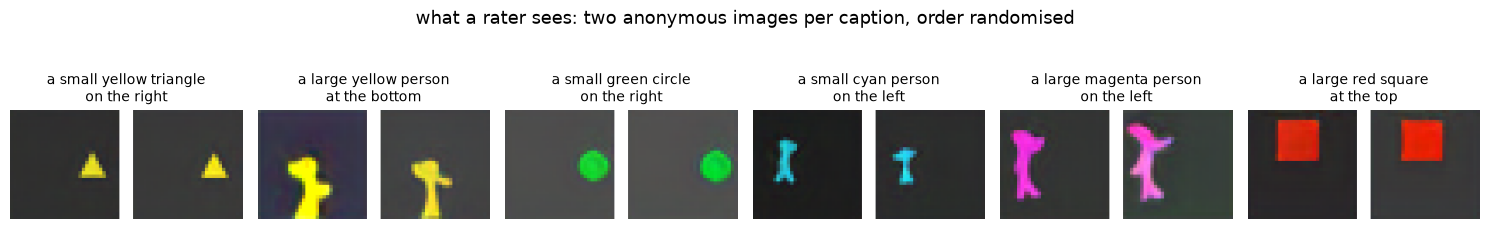

In [32]:
import csv, pathlib
BL_DIR = pathlib.Path("blind_eval"); BL_DIR.mkdir(exist_ok=True)
SYSTEMS = {"A": 1.0, "B": 4.0, "C": 12.0}                                   # ключ: какая буква какой w
bl_caps = [c for c in TE["caps"][N_EV:] if " and " not in c][:40]; bl_lab = cap_lab(bl_caps)
assert len(bl_caps) == 40, f"для слепой оценки нужно 40 подписей, найдено {len(bl_caps)}"
BL_IMG = {s: generate(bl_caps, w=w, steps=20, seed=61) for s, w in SYSTEMS.items()}
rng = random.Random(2026); pairs = []
for i, c in enumerate(bl_caps):
    for s1, s2 in itertools.combinations(SYSTEMS, 2):
        left, right = (s1, s2) if rng.random() < 0.5 else (s2, s1)
        pairs.append(dict(pair_id=len(pairs), prompt=c, idx=i, left=left, right=right))
rng.shuffle(pairs)
for k, p in enumerate(pairs):
    im = torch.cat([BL_IMG[p["left"]][p["idx"]], torch.ones(3, 32, 4), BL_IMG[p["right"]][p["idx"]]], 2)
    Image.fromarray((im.permute(1, 2, 0).numpy() * 255).astype(np.uint8)).resize((272, 128), Image.NEAREST).save(BL_DIR / f"pair_{k:03d}.png")
with open(BL_DIR / "sheet.csv", "w", newline="") as f:
    wr = csv.writer(f); wr.writerow(["pair_file", "prompt", "choice (L/R)"])
    for k, p in enumerate(pairs): wr.writerow([f"pair_{k:03d}.png", p["prompt"], ""])
json.dump([dict(pair_file=f"pair_{k:03d}.png", left=p["left"], right=p["right"]) for k, p in enumerate(pairs)], open(BL_DIR / "key.json", "w"))
print(f"{len(pairs)} pairs saved to {BL_DIR}/ (sheet.csv for raters, key.json kept separately)")

def blind_session(rater="rater1"):
    """Интерактивная оценка в Colab: показывает пары по одной, ответы пишет в blind_eval/<rater>.json."""
    import ipywidgets as wdg
    from IPython.display import display
    answers, state = {}, {"k": 0}
    img, lbl = wdg.Image(width=544), wdg.HTML()
    def render_pair():
        k = state["k"]; img.value = open(BL_DIR / f"pair_{k:03d}.png", "rb").read()
        lbl.value = f"<b>{k + 1}/{len(pairs)}</b>: which image matches the caption better? {pairs[k]['prompt']}"
    def choose(side):
        answers[state["k"]] = side; state["k"] += 1
        if state["k"] < len(pairs): render_pair()
        else: json.dump(answers, open(BL_DIR / f"{rater}.json", "w")); lbl.value = "done, saved"
    bL, bR = wdg.Button(description="left"), wdg.Button(description="right")
    bL.on_click(lambda _: choose("L")); bR.on_click(lambda _: choose("R"))
    render_pair(); display(wdg.VBox([lbl, img, wdg.HBox([bL, bR])]))

fig, ax = plt.subplots(1, 6, figsize=(15, 2.6))
for a, k in zip(ax, range(6)):
    a.imshow(Image.open(BL_DIR / f"pair_{k:03d}.png")); a.set_title(pairs[k]["prompt"].replace(" at the", "\nat the").replace(" on the", "\non the").replace(" in the", "\nin the"), fontsize=10); a.axis("off")
plt.suptitle("what a rater sees: two anonymous images per caption, order randomised", fontsize=13); plt.tight_layout(rect=(0, 0, 1, 0.9)); plt.show()

### 17.2. Анализ ответов

Симулированный оценщик выбирает изображение с большей «полезностью»: 1, если оценщик атрибутов считает изображение полностью соответствующим подписи, плюс личный шум оценщика (нормальный, $\sigma = 0{,}5$) и смещение в пользу левой картинки (+0,15). Пять таких оценщиков независимы. Анализ ниже одинаков для настоящих и симулированных ответов: достаточно заменить `RATINGS` на ответы из файлов `blind_eval/*.json`.

In [33]:
correct = {s: ((judge(BL_IMG[s])[1]["sh1"] == bl_lab[:, 1]) & (judge(BL_IMG[s])[1]["co1"] == bl_lab[:, 2]) &
               (judge(BL_IMG[s])[1]["pos1"] == bl_lab[:, 3]) & (judge(BL_IMG[s])[1]["size1"] == bl_lab[:, 4])).float() for s in SYSTEMS}
rng_np = np.random.default_rng(7)
RATINGS = np.zeros((5, len(pairs)), dtype="<U1")
for r_ in range(5):
    for k, p in enumerate(pairs):
        uL = correct[p["left"]][p["idx"]].item() + rng_np.normal(0, 0.5) + 0.15; uR = correct[p["right"]][p["idx"]].item() + rng_np.normal(0, 0.5)
        RATINGS[r_, k] = "L" if uL > uR else "R"

def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z * z / n; c = (p + z * z / (2 * n)) / d; h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return p, c - h, c + h

def fleiss_kappa(R):
    cats = np.unique(R); n = R.shape[0]; counts = np.stack([(R == c).sum(0) for c in cats], 1)
    P_i = ((counts ** 2).sum(1) - n) / (n * (n - 1)); P_bar = P_i.mean(); p_j = counts.sum(0) / counts.sum()
    return float((P_bar - (p_j ** 2).sum()) / (1 - (p_j ** 2).sum()))

def bradley_terry(wins, items, iters=200):
    """wins[(a, b)] = сколько раз a победил b. MM-алгоритм Хантера; нормировка: среднее log-силы = 0."""
    s = {i: 1.0 for i in items}
    for _ in range(iters):
        new = {}
        for i in items:
            w_i = sum(v for (a, b), v in wins.items() if a == i)
            den = sum((wins.get((i, j), 0) + wins.get((j, i), 0)) / (s[i] + s[j]) for j in items if j != i)
            new[i] = w_i / den if den > 0 else s[i]
        g_ = np.exp(np.mean(np.log(list(new.values())))); s = {i: v / g_ for i, v in new.items()}
    return {i: math.log(v) for i, v in s.items()}

def analyze(R, verbose=True):
    winners = np.where(R == "L", [p["left"] for p in pairs], [p["right"] for p in pairs])     # оценщик × пара
    maj = [max(set(col), key=list(col).count) for col in winners.T]                       # победитель по большинству
    out = {}
    for s1, s2 in itertools.combinations(SYSTEMS, 2):
        ks = [k for k, p in enumerate(pairs) if {p["left"], p["right"]} == {s1, s2}]
        w = sum(maj[k] == s2 for k in ks); out[(s2, s1)] = wilson(w, len(ks))
        if verbose:
            pv = stats.binomtest(w, len(ks), 0.5).pvalue
            print(f"w={SYSTEMS[s2]:4.1f} vs w={SYSTEMS[s1]:4.1f}: wins {w}/{len(ks)} = {out[(s2, s1)][0]:.2f}, "
                  f"95% CI [{out[(s2, s1)][1]:.2f}, {out[(s2, s1)][2]:.2f}], binomial p = {pv:.3g}")
    wins = {}
    for k, p in enumerate(pairs):
        loser = p["right"] if maj[k] == p["left"] else p["left"]; wins[(maj[k], loser)] = wins.get((maj[k], loser), 0) + 1
    return out, bradley_terry(wins, list(SYSTEMS)), maj

_, bt, maj = analyze(RATINGS)
boot = []
for b_ in range(200):                                                        # бутстрэп по подписям
    ids = np.random.default_rng(b_).choice(len(bl_caps), len(bl_caps), replace=True); cnt = collections.Counter(ids.tolist())
    wins = {}
    for k, p in enumerate(pairs):
        loser = p["right"] if maj[k] == p["left"] else p["left"]
        wins[(maj[k], loser)] = wins.get((maj[k], loser), 0) + cnt.get(p["idx"], 0)
    boot.append(bradley_terry(wins, list(SYSTEMS), iters=100))
for s in SYSTEMS:
    v = [b_[s] for b_ in boot]; print(f"Bradley-Terry log-strength w={SYSTEMS[s]:4.1f}: {bt[s]:+.2f}  (bootstrap 95% [{np.percentile(v, 2.5):+.2f}, {np.percentile(v, 97.5):+.2f}])")
print(f"Fleiss kappa (5 raters, {len(pairs)} pairs): {fleiss_kappa(RATINGS):.3f}")
left_share = (RATINGS == "L").mean(); print(f"position bias: 'left' chosen in {left_share:.3f} of answers, binomial p = {stats.binomtest(int((RATINGS == 'L').sum()), RATINGS.size, 0.5).pvalue:.3g}")
print("automatic attribute accuracy of the three systems:", {f"w={SYSTEMS[s]}": round(correct[s].mean().item(), 3) for s in SYSTEMS})
z_a, z_b = stats.norm.ppf(0.975), stats.norm.ppf(0.8)
n_need = ((z_a * math.sqrt(0.25) + z_b * math.sqrt(0.6 * 0.4)) / 0.1) ** 2
print(f"pairs needed to detect a 60% vs 50% preference (alpha 0.05, power 0.8): {math.ceil(n_need)}")

w= 4.0 vs w= 1.0: wins 22/40 = 0.55, 95% CI [0.40, 0.69], binomial p = 0.636
w=12.0 vs w= 1.0: wins 19/40 = 0.47, 95% CI [0.33, 0.63], binomial p = 0.875
w=12.0 vs w= 4.0: wins 19/40 = 0.47, 95% CI [0.33, 0.63], binomial p = 0.875
Bradley-Terry log-strength w= 1.0: -0.03  (bootstrap 95% [-0.27, +0.24])
Bradley-Terry log-strength w= 4.0: +0.10  (bootstrap 95% [-0.21, +0.38])
Bradley-Terry log-strength w=12.0: -0.07  (bootstrap 95% [-0.35, +0.27])
Fleiss kappa (5 raters, 120 pairs): -0.048
position bias: 'left' chosen in 0.637 of answers, binomial p = 2.15e-11
automatic attribute accuracy of the three systems: {'w=1.0': 1.0, 'w=4.0': 1.0, 'w=12.0': 1.0}
pairs needed to detect a 60% vs 50% preference (alpha 0.05, power 0.8): 194


## 18. Маркировка синтетики: невидимый водяной знак и подписанные метаданные

### 18.1. Водяной знак расширенного спектра

Простейший невидимый водяной знак — шумоподобный ключ $p_i \in \{-1, +1\}$, добавленный к 6000 коэффициентам среднего диапазона двумерного DCT яркости с амплитудой, дающей PSNR около 36 дБ (на глаз незаметно). Детектор не знает исходного изображения: он считает нормированную корреляцию $z = \sum_i c_i p_i / \sqrt{\sum_i c_i^2}$. Без знака $z \approx \mathcal N(0, 1)$, со знаком $z$ смещается на величину порядка $a\sqrt{N}/\mathrm{rms}(c)$. Порог $z > 4$ соответствует вероятности ложной тревоги около $3 \cdot 10^{-5}$. По этому принципу (знак в частотной области) работает библиотека invisible-watermark, которую Stability AI использует в SDXL ([invisible-watermark](https://github.com/ShieldMnt/invisible-watermark)). Современные схемы встраивают знак в сам генератор: в декодер VAE ([Stable Signature](https://arxiv.org/abs/2303.15435)) или в начальный шум ([Tree-Ring](https://arxiv.org/abs/2305.20030)).

Знак проверяется на шести изображениях SD-Turbo из раздела 8 после типичных преобразований, включая «регенерацию» через VAE Stable Diffusion: кодирование и декодирование, которое сохраняет смысл изображения, но меняет мелкие детали ([Zhao et al., 2023](https://arxiv.org/abs/2306.01953)).

8 images (3, 512, 512); PSNR watermarked vs original: 36.0 dB
no watermark, 7 images x 300 random keys: z mean -0.02, std 0.98, max 2.97, share z>4: 0.0000
none                   PSNR vs marked    inf dB | z mean  10.44, min   5.79 | detected 1.00
JPEG q=90              PSNR vs marked   37.1 dB | z mean  10.44, min   5.79 | detected 1.00
JPEG q=50              PSNR vs marked   32.1 dB | z mean  10.42, min   5.79 | detected 1.00
resize x0.5            PSNR vs marked   31.2 dB | z mean  10.39, min   5.78 | detected 1.00
noise sigma=0.03       PSNR vs marked   30.5 dB | z mean  10.39, min   5.77 | detected 1.00
brightness +10%        PSNR vs marked   26.1 dB | z mean  10.28, min   5.68 | detected 1.00
rotate 2 deg           PSNR vs marked   17.4 dB | z mean   1.53, min  -0.05 | detected 0.00
crop 10% + resize      PSNR vs marked   14.6 dB | z mean   0.10, min  -1.38 | detected 0.00
SD VAE regeneration    PSNR vs marked   32.1 dB | z mean   8.33, min   4.09 | detected 1.00
6 s


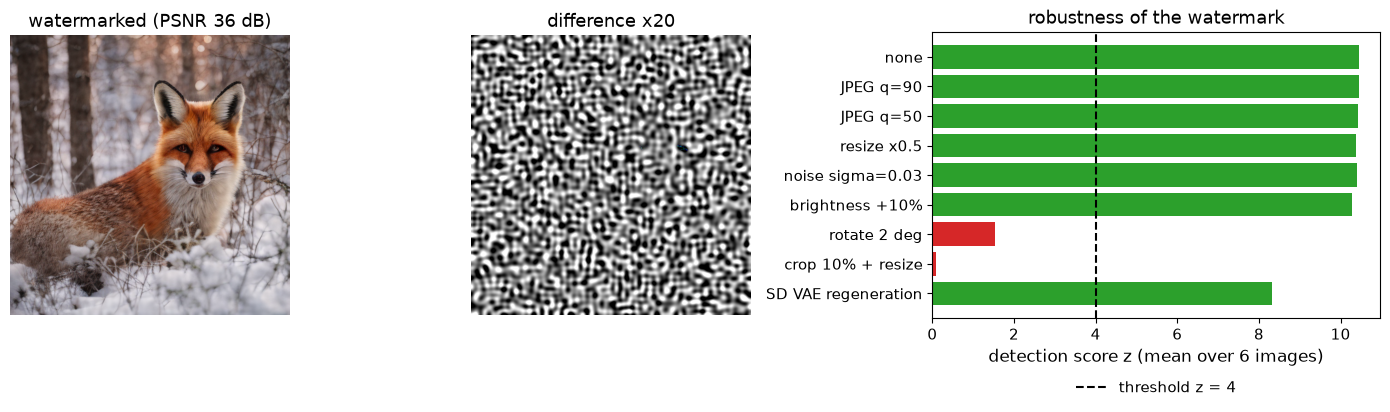

In [34]:
from scipy.fft import dctn, idctn
WM_N, WM_PSNR = 6000, 36.0
def wm_positions(h, w, key):
    rng = np.random.default_rng(key); u, v = np.meshgrid(np.arange(h), np.arange(w), indexing="ij")
    band = np.argwhere(((u + v) >= 16) & ((u + v) <= 96)); n = min(WM_N, len(band) // 2)
    sel = band[rng.choice(len(band), n, replace=False)]; return sel[:, 0], sel[:, 1], rng.choice([-1.0, 1.0], n)
luma = lambda x: 0.299 * x[0] + 0.587 * x[1] + 0.114 * x[2]
def wm_embed(x, key):
    """x: 3×H×W в [0, 1]. Яркостная поправка добавляется во все три канала одинаково (цветность не меняется)."""
    h, w = x.shape[1:]; pu, pv, pat = wm_positions(h, w, key)
    a = math.sqrt(10 ** (-WM_PSNR / 10) * h * w / len(pat))
    delta = np.zeros((h, w)); delta[pu, pv] = a * pat
    return (x + torch.from_numpy(idctn(delta, norm="ortho")).float()[None]).clamp(0, 1)
def wm_detect(x, key):
    h, w = x.shape[1:]; pu, pv, pat = wm_positions(h, w, key)
    c = dctn(luma(x.double().numpy()), norm="ortho")[pu, pv]
    return float((c * pat).sum() / np.sqrt((c ** 2).sum()))

def jpeg(x, q):
    b = io.BytesIO(); Image.fromarray((x.permute(1, 2, 0).numpy() * 255).round().astype(np.uint8)).save(b, "JPEG", quality=q)
    return to_t(Image.open(b))[0]
pil = lambda x: Image.fromarray((x.permute(1, 2, 0).numpy() * 255).round().astype(np.uint8))
def resize_back(x, f): h = x.shape[1]; return to_t(pil(x).resize((int(h * f), int(h * f)), Image.BICUBIC).resize((h, h), Image.BICUBIC))[0]
def crop_back(x, f): h = x.shape[1]; m = int(h * f / 2); return to_t(pil(x).crop((m, m, h - m, h - m)).resize((h, h), Image.BICUBIC))[0]
@torch.no_grad()
def vae_regen(x):
    lat = SD_VAE.encode((x[None] * 2 - 1).to(DEVICE, SD_DTYPE)).latent_dist.mean
    return ((SD_VAE.decode(lat).sample.float().cpu()[0] + 1) / 2).clamp(0, 1)
ATTACKS = {"none": lambda x: x, "JPEG q=90": lambda x: jpeg(x, 90), "JPEG q=50": lambda x: jpeg(x, 50),
           "resize x0.5": lambda x: resize_back(x, 0.5), "noise sigma=0.03": lambda x: (x + 0.03 * torch.randn_like(x)).clamp(0, 1),
           "brightness +10%": lambda x: (x * 1.1).clamp(0, 1), "rotate 2 deg": lambda x: to_t(pil(x).rotate(2, Image.BICUBIC))[0],
           "crop 10% + resize": lambda x: crop_back(x, 0.1), "SD VAE regeneration": vae_regen}
KEY = 20261027
WM_SRC = [im[0] for im in SD_IMAGES]
WM_IMGS = [wm_embed(x, KEY) for x in WM_SRC]
print(f"{len(WM_IMGS)} images {tuple(WM_IMGS[0].shape)}; PSNR watermarked vs original: {np.mean([psnr(a[None], b[None]) for a, b in zip(WM_IMGS, WM_SRC)]):.1f} dB")
null_z = np.array([wm_detect(x, k) for x in WM_SRC + [x_ph[0]] for k in range(300)])
print(f"no watermark, 7 images x 300 random keys: z mean {null_z.mean():.2f}, std {null_z.std():.2f}, max {null_z.max():.2f}, share z>4: {(null_z > 4).mean():.4f}")
WM_RES = {}
with Timer() as t:
    for name, f in ATTACKS.items():
        zs, ps = [], []
        for x in WM_IMGS:
            y = f(x); zs.append(wm_detect(y, KEY)); ps.append(psnr(y[None], x[None]) if name != "none" else float("inf"))
        WM_RES[name] = (np.mean(zs), np.min(zs), np.mean(np.array(zs) > 4), np.mean(ps))
        print(f"{name:22s} PSNR vs marked {np.mean(ps):6.1f} dB | z mean {np.mean(zs):6.2f}, min {np.min(zs):6.2f} | detected {np.mean(np.array(zs) > 4):.2f}")
print(f"{t.s:.0f} s")
fig, ax = plt.subplots(1, 3, figsize=(14, 4.3), gridspec_kw=dict(width_ratios=[1, 1, 1.6]))
ax[0].imshow(WM_IMGS[0].permute(1, 2, 0)); ax[0].set_title(f"watermarked (PSNR {WM_PSNR:.0f} dB)", fontsize=13); ax[0].axis("off")
ax[1].imshow(((WM_IMGS[0] - WM_SRC[0]) * 20 + 0.5).clamp(0, 1).permute(1, 2, 0)); ax[1].set_title("difference x20", fontsize=13); ax[1].axis("off")
names = list(WM_RES); ax[2].barh(names, [WM_RES[n][0] for n in names], color=["C2" if WM_RES[n][2] == 1 else "C3" if WM_RES[n][2] == 0 else "C1" for n in names])
ax[2].axvline(4, color="k", ls="--", lw=1.5, label="threshold z = 4"); ax[2].invert_yaxis(); ax[2].set_xlabel("detection score z (mean over 6 images)", fontsize=12)
ax[2].tick_params(labelsize=11); ax[2].legend(fontsize=11, loc="upper center", bbox_to_anchor=(0.5, -0.17), frameon=False); ax[2].set_title("robustness of the watermark", fontsize=13)
plt.tight_layout(); plt.show()

### 18.2. Подписанные метаданные: идея C2PA

C2PA ([спецификация](https://spec.c2pa.org/specifications/specifications/2.5/specs/C2PA_Specification.html)) прикладывает к файлу манифест: кто и чем создал или изменил изображение, хеш содержимого и криптографическую подпись сертификатом издателя. Ниже — учебный аналог: JSON-манифест с SHA-256 пикселей, подписанный HMAC (вместо сертификата X.509), записывается в PNG-чанк. Проверяются четыре случая: исходный файл, пересохранение в JPEG (метаданные теряются), правка пикселей с переносом старого манифеста и подделка поля в манифесте.

In [35]:
SECRET = b"course-demo-signing-key"                                          # в C2PA вместо этого — закрытый ключ сертификата
pix_hash = lambda im: hashlib.sha256(np.asarray(im.convert("RGB")).tobytes()).hexdigest()
def sign_png(im, path, meta):
    man = dict(meta, sha256=pix_hash(im)); body = json.dumps(man, sort_keys=True)
    info = PngImagePlugin.PngInfo(); info.add_text("ai_manifest", body); info.add_text("ai_signature", hmac.new(SECRET, body.encode(), "sha256").hexdigest())
    im.save(path, pnginfo=info)
def verify(path):
    im = Image.open(path); txt = getattr(im, "text", {}) or {}
    if "ai_manifest" not in txt: return "no manifest"
    body = txt["ai_manifest"]
    if not hmac.compare_digest(hmac.new(SECRET, body.encode(), "sha256").hexdigest(), txt.get("ai_signature", "")): return "INVALID signature"
    if json.loads(body)["sha256"] != pix_hash(im): return "signature ok, but pixels were changed"
    return "valid: " + json.loads(body)["generator"]
im0 = pil(WM_IMGS[0]); meta = dict(generator="stabilityai/sd-turbo", ai_generated=True, created="2026-10-27")
sign_png(im0, "signed.png", meta)
im0.save("resaved.jpg", quality=95)                                          # обычное пересохранение: PIL не переносит чанки
edited = im0.copy(); ImageDraw.Draw(edited).rectangle([10, 10, 60, 60], fill=(255, 255, 255))
src = Image.open("signed.png"); info = PngImagePlugin.PngInfo()
for k, v in src.text.items(): info.add_text(k, v)
edited.save("edited.png", pnginfo=info)
forged = PngImagePlugin.PngInfo(); body = json.loads(src.text["ai_manifest"]); body["ai_generated"] = False
forged.add_text("ai_manifest", json.dumps(body, sort_keys=True)); forged.add_text("ai_signature", src.text["ai_signature"]); im0.save("forged.png", pnginfo=forged)
for f in ("signed.png", "resaved.jpg", "edited.png", "forged.png"):
    zf = wm_detect(to_t(Image.open(f).convert("RGB"))[0], KEY)
    print(f"{f:12s} manifest: {verify(f):40s} | watermark z = {zf:5.1f}")

signed.png   manifest: valid: stabilityai/sd-turbo              | watermark z =   8.8
resaved.jpg  manifest: no manifest                              | watermark z =   8.8
edited.png   manifest: signature ok, but pixels were changed    | watermark z =   7.8
forged.png   manifest: INVALID signature                        | watermark z =   8.8


## 19. Сводка практикума

In [ ]:
def best_w(key, sign=1): return min(CFG_W, key=lambda w: sign * cfg_res[w][key])
rows = [
    ("SD-Turbo, 1 step on " + DEVICE, f"{np.mean(sd_times):.1f} s per {res}x{res} image; matched CLIP score {cs.diag().mean():.1f} vs {cs[~torch.eye(len(PROMPTS), dtype=bool)].mean():.1f}"),
    ("mini VAE", f"latent 4x8x8 (x12 compression), scaling_factor {SF:.3f}, PSNR {np.mean(psnr_te):.1f} dB"),
    ("mini U-Net", f"{nparam(unet) / 1e6:.2f} M params, {t_unet / 60:.1f} min; own loop = StableDiffusionPipeline"),
    ("FD bias (real vs real)", f"n=50: {bias[0][1]:.1f}, n=2000: {bias[-1][1]:.2f}; KID x1e3: {bias[0][3]:+.2f} / {bias[-1][3]:+.3f}"),
    ("CFG sweep", f"best FD at w={best_w('FD')}; condition accuracy w=1: {cfg_res[1.0]['acc1']:.2f} -> w=12: {cfg_res[12.0]['acc1']:.2f}; "
                  f"recall {cfg_res[1.0]['recall']:.2f} -> {cfg_res[12.0]['recall']:.2f}"),
    ("CLIP score sensitivity", ", ".join(f"{k} {v:.2f}" for k, v in clip_sens.items())),
    ("memorization", ", ".join(f"x{d}: {np.mean([m['copy'] for m in memo if m['dup'] == d]):.2f}" for d in sorted(set(m['dup'] for m in memo))) + f"; no duplicates {np.mean(ctrl_copy):.2f}"),
    ("textual inversion (cross)", f"cross in train context {ADAPT['textual inversion']['cross_in']:.2f}; expressible concept {ti2['green_triangle']:.2f}"),
    ("DreamBooth / + prior / LoRA", " | ".join(f"{k}: new-context cross {ADAPT[k]['cross_new']:.2f}, copy {ADAPT[k]['copy']:.2f}, drift acc {ADAPT[k]['drift_acc']:.2f}"
                                       for k in (f"DreamBooth {EV_STEPS[-1]} steps", f"DreamBooth + prior {EV_STEPS[-1]} steps", f"LoRA r=4, {EV_STEPS[-1]} steps"))),
    ("ControlNet (scale 0 -> 1)", " | ".join(f"{n} {CN_RES[n]['scale 0.0']:.2f} -> {CN_RES[n]['scale 1.0']:.2f}" for n in CTYPES)),
    ("IP-Adapter, image only", f"shape {IP_RES['image prompt, lambda=1.0']['shape']:.2f}, colour {IP_RES['image prompt, lambda=1.0']['color']:.2f} "
                               f"(unconditional {IP_RES['no image (unconditional)']['shape']:.2f} / {IP_RES['no image (unconditional)']['color']:.2f})"),
    ("inpainting: blending vs 9-ch", f"right object correct {INP['latent blending, base U-Net']['right_correct']:.2f} vs {INP['9-channel inpainting U-Net']['right_correct']:.2f}; "
                                     f"seam {INP['latent blending, base U-Net']['seam']:.3f} vs {INP['9-channel inpainting U-Net']['seam']:.3f}"),
    ("blind 2AFC (simulated raters)", f"Fleiss kappa {fleiss_kappa(RATINGS):.2f}; BT: " + ", ".join(f"w={SYSTEMS[s]}: {bt[s]:+.2f}" for s in SYSTEMS)),
    ("watermark", ", ".join(f"{n}: {WM_RES[n][2]:.2f}" for n in ("JPEG q=50", "resize x0.5", "crop 10% + resize", "SD VAE regeneration"))),
]
w0 = max(len(a) for a, _ in rows)
for a, b_ in rows: print(f"{a:{w0}s}  {b_}")
print(f"\ntotal notebook time: {(time.time() - T_START) / 60:.1f} min on {DEVICE} (FAST_DEV_RUN={FAST_DEV_RUN})")

SD-Turbo, 1 step on cuda       0.5 s per 512x512 image; matched CLIP score 35.5 vs 11.1
mini VAE                       latent 4x8x8 (x12 compression), scaling_factor 0.668, PSNR 36.8 dB
mini U-Net                     4.82 M params, 31.8 min; own loop = StableDiffusionPipeline
FD bias (real vs real)         n=50: 11429.4, n=2000: 311.12; KID x1e3: -10.36 / +0.368
CFG sweep                      best FD at w=2.0; condition accuracy w=1: 0.99 -> w=12: 1.00; recall 0.93 -> 0.83
CLIP score sensitivity         color 0.97, shape 0.86, size 0.54, position 0.50, binding 0.51
memorization                   x1: 0.00, x10: 0.00, x50: 0.00, x200: 0.23; no duplicates 0.00
textual inversion (cross)      cross in train context 0.00; expressible concept 1.00
DreamBooth / + prior / LoRA    DreamBooth 1200 steps: new-context cross 1.00, copy 0.00, drift acc 0.71 | DreamBooth + prior 1200 steps: new-context cross 0.44, copy 0.00, drift acc 0.98 | LoRA r=4, 1200 steps: new-context cross 0.69, copy 0.00, dri

: 

## Выводы

1. Latent diffusion переносит диффузию в латентное пространство автоэнкодера. У SD изображение 512×512×3 сжимается в латент 64×64×4, в 48 раз по числу чисел, и U-Net работает с 4096 позициями вместо 262 144 ([Rombach et al., 2022](https://arxiv.org/abs/2112.10752)). Качество деталей ограничено декодером VAE: в разделе 8.2 одна только реконструкция без генерации теряет мелкую текстуру.
2. Stable Diffusion — это четыре независимых компонента: VAE, текстовый энкодер, U-Net с cross-attention и планировщик. Ручной цикл в шесть строк совпадает с библиотечным пайплайном, планировщик меняется без переобучения, а мини-модель из тех же классов работает в стандартном `StableDiffusionPipeline`.
3. Textual inversion, DreamBooth и LoRA отличаются тем, куда записывается концепт. Textual inversion не выходит за пределы того, что генератор уже умеет. DreamBooth и LoRA учат новую форму, но портят обычные подписи (language drift) и протаскивают концепт туда, где его не просили. Prior preservation снижает и то, и другое ценой более слабого переноса концепта в новые контексты.
4. Дословное запоминание растёт с числом дубликатов в данных ([Carlini et al., 2023](https://arxiv.org/abs/2301.13188)). Дедупликация обучающей выборки — самая дешёвая защита. Проверять копирование нужно относительным критерием, а не просто близостью к какому-нибудь обучающему изображению.
5. ControlNet добавляет управление геометрией без порчи исходной модели благодаря нулевым свёрткам ([Zhang et al., 2023](https://arxiv.org/abs/2302.05543)). IP-Adapter делает подсказкой изображение через отдельную ветку внимания с весом $\lambda$ ([Ye et al., 2023](https://arxiv.org/abs/2308.06721)). Соблюдение условия проверяется тем же препроцессором, которым получена карта.
6. Ни одна метрика не описывает генератор целиком. FD смещён и сравним только при одинаковом $n$. KID несмещён, но шумен. Precision/recall и density/coverage разделяют качество и покрытие. Vendi измеряет разнообразие без эталона. CLIP score видит объекты и цвета, но почти не видит связывание атрибутов и положение. Для проверки условия нужны детекторы и VQA-бенчмарки ([GenEval](https://arxiv.org/abs/2310.11513), [TIFA](https://arxiv.org/abs/2303.11897)).
7. Ручная оценка доказательна только при протоколе: слепое предъявление, случайный порядок, заранее заданный вопрос, несколько оценщиков, доверительные интервалы. Чтобы отличить 60 % побед от 50 %, нужно около 200 пар.
8. Право в области генеративных моделей меняется быстро. Лицензии весов (OpenRAIL-M, OpenRAIL++-M, Stability AI Community License) ограничивают использование. Дипфейки регулируются отдельными законами. С 2026–2027 годов маркировка синтетики становится обязательной в ЕС, Китае и, по принятому закону, в России. Невидимый водяной знак переживает пересохранение, но не геометрические искажения и регенерацию. Подписанный манифест C2PA надёжен, но теряется при удалении метаданных. На практике нужны оба механизма.

## Контрольные вопросы

1. Во сколько раз VAE Stable Diffusion сжимает изображение 512×512×3, если латент 64×64×4?
   Ответ: $786\,432 / 16\,384 = 48$.
2. Во сколько раз мини-VAE практикума сжимает изображение 32×32×3 в латент 4×8×8?
   Ответ: $3072 / 256 = 12$.
3. Во сколько раз уменьшается стоимость self-attention по всем позициям при переходе от пикселей 512×512 к латенту 64×64? Стоимость квадратична по числу позиций.
   Ответ: позиций в $8^2 = 64$ раза меньше, стоимость в $64^2 = 4096$ раз меньше.
4. Какой латент у SDXL при генерации 1024×1024 с тем же VAE (понижение в 8 раз, 4 канала)?
   Ответ: $4 \times 128 \times 128$.
5. Стандартное отклонение латентов VAE на обучающих данных равно 5,49. Каким должен быть `scaling_factor`?
   Ответ: $s = 1/5{,}49 \approx 0{,}182$. Это близко к 0,18215 у SD.
6. В точке $\hat\epsilon_\varnothing = 0{,}2$, $\hat\epsilon_c = 0{,}5$. Чему равно предсказание с CFG при $w = 7$?
   Ответ: $0{,}2 + 7 \cdot (0{,}5 - 0{,}2) = 2{,}3$.
7. Сколько вызовов U-Net стоит генерация за 20 шагов с CFG и сколько у SD-Turbo за 1 шаг без CFG?
   Ответ: 40 и 1.
8. Сколько параметров добавляет LoRA ранга 4 к матрице 320×320 и какая это доля от самой матрицы?
   Ответ: $r(d + k) = 4 \cdot 640 = 2560$, то есть 2,5 % от 102 400.
9. Сколько чисел обучает textual inversion для одного токена в SD 1.x (ширина CLIP ViT-L/14 равна 768) и в мини-модели (ширина 512)?
   Ответ: 768 и 512.
10. Почему необученный ControlNet не меняет выход U-Net, но всё же обучается?
    Ответ: веса нулевых свёрток равны нулю, поэтому их выход ноль. Градиент по весам $W$ пропорционален входу свёртки, а вход ненулевой. Поэтому уже после первого шага веса становятся ненулевыми.
11. Чему равен выход слоя IP-Adapter при $\lambda = 0$?
    Ответ: обычному текстовому cross-attention, то есть исходной модели.
12. Чему равно FD между одномерными гауссианами $\mathcal N(0, 1)$ и $\mathcal N(1, 2^2)$?
    Ответ: $(\mu_1 - \mu_2)^2 + (\sigma_1 - \sigma_2)^2 = 1 + 1 = 2$.
13. Две выборки из одного распределения дали FD = 165 при $n = 2000$. Смещение FID порядка $1/n$. Какого FD ожидать при $n = 50$?
    Ответ: примерно $165 \cdot 2000/50 = 6600$. В пробном прогоне получилось около 6200.
14. Может ли оценка KID быть отрицательной? Почему?
    Ответ: может. Это несмещённая оценка квадрата MMD: при совпадающих распределениях её среднее равно нулю, а отдельные значения разбросаны вокруг нуля в обе стороны.
15. Чему равен Vendi score у выборки из $n$ одинаковых изображений, из $n$ попарно ортогональных и из двух равных ортогональных кластеров одинаковых изображений?
    Ответ: 1, $n$ и 2.
16. Косинус эмбеддингов изображения и подписи в CLIP равен 0,33. Каков CLIP score с множителем 100 и с множителем 2,5?
    Ответ: 33 и 0,825.
17. Сколько пар нужно, чтобы при $\alpha = 0{,}05$ (двусторонний тест) и мощности 0,8 отличить долю побед 0,6 от 0,5?
    Ответ: $n = \left(\frac{1{,}96 \cdot 0{,}5 + 0{,}84 \sqrt{0{,}24}}{0{,}1}\right)^2 \approx 194$.
18. Система победила в 27 из 40 пар. Каков приближённый 95-процентный доверительный интервал Вальда?
    Ответ: $\hat p = 0{,}675$, $\mathrm{SE} = \sqrt{0{,}675 \cdot 0{,}325/40} \approx 0{,}074$, интервал $[0{,}53;\ 0{,}82]$.
19. Логарифмические силы Брэдли–Терри систем A и B равны +0,24 и −0,31. Какова вероятность, что A победит B?
    Ответ: $1/(1 + e^{-0{,}55}) \approx 0{,}63$.
20. Наблюдаемое согласие оценщиков $\bar P = 0{,}6$, случайное $\bar P_e = 0{,}5$. Чему равна каппа Флейса?
    Ответ: $(0{,}6 - 0{,}5)/(1 - 0{,}5) = 0{,}2$, слабое согласие.
21. Детектор водяного знака срабатывает при $z > 4$, без знака $z \sim \mathcal N(0, 1)$. Сколько ложных срабатываний ожидается на миллионе немаркированных изображений?
    Ответ: $P(z > 4) \approx 3{,}2 \cdot 10^{-5}$, то есть около 32.
22. Сдвиг $z$ от водяного знака примерно равен $a\sqrt N/\mathrm{rms}(c)$. При $N = 6000$ и $a/\mathrm{rms}(c) = 0{,}05$ знак обнаруживается? Что даёт удвоение амплитуды и чего оно стоит?
    Ответ: $z \approx 0{,}05 \cdot 77{,}5 \approx 3{,}9 < 4$, не обнаруживается. При удвоении $z \approx 7{,}7$, но PSNR падает на 6 дБ.
23. Почему JPEG-пересохранение удаляет манифест C2PA, но не водяной знак?
    Ответ: манифест хранится в метаданных файла и при перекодировании не переносится. Водяной знак записан в самих пикселях, в среднем диапазоне частот, который JPEG сохраняет.
24. С какой даты применяются обязанности прозрачности по статье 50 AI Act ЕС?
    Ответ: со 2 августа 2026 года ([Еврокомиссия](https://digital-strategy.ec.europa.eu/en/faqs/transparency-obligations-under-article-50-ai-act)).

## Задания

1. Масштабный множитель. Обучите мини-LDM с `scaling_factor = 1` вместо подобранного и сравните FD и точность атрибутов при $w = 4$. Объясните результат через расписание шума.
2. Длина контекста. Уменьшите `L_TXT` с 20 до 8 токенов. Какие подписи обрезаются и как падает точность для двух фигур?
3. Ранг LoRA. Повторите раздел 13.4 для $r = 1, 4, 16$ и для LoRA только на $W_q, W_v$. Постройте зависимость «перенос концепта / дрейф» от числа параметров.
4. Канарейки. Добавьте уровни дублирования 500 и 1000 и проверьте, где доля копий выходит на насыщение. Повторите эксперимент после дедупликации данных.
5. ControlNet. Обучите отдельный ControlNet только на позе и сравните его с объединённым на четырёх типах карт по IoU конечностей при равном числе шагов.
6. Метрики. Посчитайте FD и KID в признаках CLIP ViT-B/32 вместо признаков оценщика и сравните ранжирование значений $w$ с ранжированием по точности атрибутов.
7. Настоящая слепая оценка. Проведите `blind_session()` с тремя–пятью людьми на 120 парах, замените `RATINGS` и сравните доли побед и каппу Флейса с симулированными.
8. Водяной знак. Сделайте знак устойчивым к обрезке 10 %: встраивайте его в блоки 64×64 с повторением или используйте инвариантное к сдвигу преобразование. Проверьте ложные срабатывания на 300 случайных ключах.

## Источники

Модели и инструменты
- Stable Diffusion v1-4, карточка модели: https://huggingface.co/CompVis/stable-diffusion-v1-4
- Stable Diffusion 2.1: https://huggingface.co/stabilityai/stable-diffusion-2-1
- SDXL base 1.0: https://huggingface.co/stabilityai/stable-diffusion-xl-base-1.0
- SD-Turbo: https://huggingface.co/stabilityai/sd-turbo
- Stability AI License: https://stability.ai/license
- TAESD: https://huggingface.co/madebyollin/taesd
- CLIP ViT-B/32: https://huggingface.co/openai/clip-vit-base-patch32
- Изображение COCO для раздела 8: http://images.cocodataset.org/val2017/000000039769.jpg
- invisible-watermark: https://github.com/ShieldMnt/invisible-watermark
- SynthID: https://deepmind.google/models/synthid/
- C2PA Specification 2.5: https://spec.c2pa.org/specifications/specifications/2.5/specs/C2PA_Specification.html
- Re-LAION-5B: https://laion.ai/blog/relaion-5b/

Статьи
- Rombach et al. High-Resolution Image Synthesis with Latent Diffusion Models: https://arxiv.org/abs/2112.10752
- Podell et al. SDXL: https://arxiv.org/abs/2307.01952
- Esser et al. Scaling Rectified Flow Transformers (SD3): https://arxiv.org/abs/2403.03206
- Sauer et al. Adversarial Diffusion Distillation: https://arxiv.org/abs/2311.17042
- Ho et al. Denoising Diffusion Probabilistic Models: https://arxiv.org/abs/2006.11239
- Ho & Salimans. Classifier-Free Diffusion Guidance: https://arxiv.org/abs/2207.12598
- Lin et al. Common Diffusion Noise Schedules and Sample Steps are Flawed: https://arxiv.org/abs/2305.08891
- Radford et al. CLIP: https://arxiv.org/abs/2103.00020
- Hu et al. LoRA: https://arxiv.org/abs/2106.09685
- Ruiz et al. DreamBooth: https://arxiv.org/abs/2208.12242
- Gal et al. Textual Inversion: https://arxiv.org/abs/2208.01618
- Zhang et al. ControlNet: https://arxiv.org/abs/2302.05543
- Mou et al. T2I-Adapter: https://arxiv.org/abs/2302.08453
- Ye et al. IP-Adapter: https://arxiv.org/abs/2308.06721
- Lugmayr et al. RePaint: https://arxiv.org/abs/2201.09865
- Meng et al. SDEdit: https://arxiv.org/abs/2108.01073
- Heusel et al. FID: https://arxiv.org/abs/1706.08500
- Bińkowski et al. KID: https://arxiv.org/abs/1801.01401
- Chong & Forsyth. Effectively Unbiased FID: https://arxiv.org/abs/1911.07023
- Parmar et al. Clean-FID: https://arxiv.org/abs/2104.11222
- Kynkäänniemi et al. The Role of ImageNet Classes in FID: https://arxiv.org/abs/2203.06026
- Stein et al. Exposing Flaws of Generative Model Evaluation Metrics: https://arxiv.org/abs/2306.04675
- Hessel et al. CLIPScore: https://arxiv.org/abs/2104.08718
- Kynkäänniemi et al. Improved Precision and Recall: https://arxiv.org/abs/1904.06991
- Naeem et al. Density and Coverage: https://arxiv.org/abs/2002.09797
- Friedman & Dieng. Vendi Score: https://arxiv.org/abs/2210.02410
- Ghosh et al. GenEval: https://arxiv.org/abs/2310.11513
- Hu et al. TIFA: https://arxiv.org/abs/2303.11897
- Wu et al. HPSv2: https://arxiv.org/abs/2306.09341
- Xu et al. ImageReward: https://arxiv.org/abs/2304.05977
- Kirstain et al. Pick-a-Pic / PickScore: https://arxiv.org/abs/2305.01569
- Carlini et al. Extracting Training Data from Diffusion Models: https://arxiv.org/abs/2301.13188
- Somepalli et al. Diffusion Art or Digital Forgery: https://arxiv.org/abs/2212.03860
- Wen et al. Tree-Ring Watermarks: https://arxiv.org/abs/2305.20030
- Fernandez et al. Stable Signature: https://arxiv.org/abs/2303.15435
- Zhao et al. Invisible Image Watermarks Are Provably Removable: https://arxiv.org/abs/2306.01953
- Saberi et al. Robustness of AI-Image Detectors: https://arxiv.org/abs/2310.00076

Право и регулирование
- Getty Images v Stability AI, решение Высокого суда Англии и Уэльса: https://www.judiciary.uk/wp-content/uploads/2025/11/Getty-Images-v-Stability-AI.pdf
- Latham & Watkins о решении по делу Getty v Stability: https://www.lw.com/en/insights/getty-images-v-stability-ai-english-high-court-rejects-secondary-copyright-claim
- Orrick о деле Getty v Stability: https://www.orrick.com/en/Insights/2025/11/Pixels-at-Dawn-Getty-Images-v-Stability-AI
- Andersen v. Stability AI, AI Lawsuit Tracker: https://ailawsuittracker.com/cases/andersen-v-stability-ai-ltd-3-23-cv-00201/
- Andersen v. Stability AI, материалы дела (CourtListener): https://www.courtlistener.com/docket/66732129/andersen-v-stability-ai-ltd/?entry_gte=177&page=3
- Thaler v. Perlmutter, D.C. Circuit, 2025: https://media.cadc.uscourts.gov/opinions/docs/2025/03/23-5233.pdf
- U.S. Copyright Office. Copyright and Artificial Intelligence, Part 2: https://www.copyright.gov/ai/Copyright-and-Artificial-Intelligence-Part-2-Copyrightability-Report.pdf
- FTC о применении TAKE IT DOWN Act: https://www.ftc.gov/business-guidance/blog/2026/05/take-it-down-act-enforcement-starts-now-what-know-about-ftc-tida
- CRS о TAKE IT DOWN Act: https://www.congress.gov/crs_external_products/LSB/HTML/LSB11314.html
- AI Act ЕС, статья 50: https://ai-act-service-desk.ec.europa.eu/en/ai-act/article-50
- Еврокомиссия, обязанности прозрачности по статье 50: https://digital-strategy.ec.europa.eu/en/faqs/transparency-obligations-under-article-50-ai-act
- Китай, меры по маркировке ИИ-контента (ETO AGORA): https://agora.eto.tech/instrument/2096
- Allen & Gledhill о китайских правилах маркировки: https://www.allenandgledhill.com/publication/articles/30284/further-regulates-ai-generated-content
- Федеральный закон № 243-ФЗ, статья 9: https://www.consultant.ru/document/cons_doc_LAW_540336/8694776acd071da231c9a76eea4963707333e495/
- Обзор закона № 243-ФЗ: https://www.consultant.ru/law/hotdocs/95007.html
- ComNews о законопроекте о маркировке контента: https://www.comnews.ru/content/246954/2026-08-19/2026-w34/1008/gosduma-rf-pometit-kontent
- Гарант о законе № 130-ФЗ: https://www.garant.ru/news/2078500/
- Гарант о законопроекте № 1288702-8: https://www.garant.ru/news/2168210/